# EDA — Caso A: Optimización de Abastecimiento (Tostao)

**Objetivo del EDA:** entender los datos lo suficiente para (1) construir un pronóstico de demanda por SKU-Tienda a 1 semana con incertidumbre y (2) decidir cuánto pedir con un enfoque Newsvendor (costo de quiebre vs. costo de sobrestock).

> **Alcance:** la decisión de pedido se apoya en `01_supply_optimization/`. Las carpetas de los casos B y C (`02_product_bundles/`, `03_aov_drivers/`) se usan **solo como contexto y para poner a prueba hipótesis** (¿explican la demanda? ¿cuánto vale la venta cruzada?). Lo que no se pueda conocer antes de la semana a pronosticar no entra al modelo.

> **Punto de partida.** El enunciado entrega 13 semanas de ventas y una foto del inventario, pero no el historial de stock ni de pedidos. Con eso no se puede evaluar cómo se repone hoy (ver 1.6). Lo que sí se puede hacer es decidir bien la semana del 1 al 7 de abril: pronosticar la demanda con incertidumbre y pedir según el costo de cada tipo de error (Newsvendor). Su valor se mide en el backtest, contra reglas simples como repetir la venta reciente. Para medir la política actual haría falta el historial de stock, pedidos y mermas.

### Hoja de ruta
| Parte | Qué responde | Contenido |
|---|---|---|
| **1. Entendimiento de los datos** | ¿Qué datos hay, cómo se comporta la demanda y cuánto cuesta equivocarse? | 1.1 Qué datos componen el ejercicio · 1.2 Temporalidad · 1.3 Calidad estructural · 1.4 Radiografía descriptiva · 1.5 Catálogo y economía del producto · 1.6 El inventario: una foto sin contexto · 1.7 Supuestos y límites |
| **2. Anomalías** | ¿Qué está raro y qué hacemos con eso? | 2.1 Ceros · 2.2 Outliers · 2.3 Demanda censurada y picos · 2.4 Anomalías de inventario · 2.5 Inconsistencias entre tablas |
| **3. Generación de hipótesis** | ¿Qué variables explican la demanda o cambian la decisión? ¿Entran al modelo? | Tabla de veredicto de variables + H1 a H13 (hipótesis → prueba → resultado → decisión); H13 mide el efecto de los parámetros operativos |
| **4. Conclusiones** | ¿Qué descubrimos y qué decidimos para el modelo? | Hallazgos, decisiones de modelado, preguntas abiertas |
| **Anexo y glosario** | Material de apoyo | Exploración del stock (movida desde 1.6) y glosario de términos |

### Contenido
Haz clic en una sección para ir a ella.

> **Nota de navegación.** Los enlaces del contenido funcionan al abrir el notebook en Jupyter. En GitHub no saltan a la sección; para recorrerlo, desplázate por las secciones numeradas o descarga el archivo.

- **<a href="#PARTE-1-—-Entendimiento-de-los-datos">PARTE 1 — Entendimiento de los datos</a>**
  - <a href="#1.1-Qué-datos-componen-el-ejercicio">1.1 Qué datos componen el ejercicio</a>
  - <a href="#1.2-Temporalidad:-¿qué-periodo-cubre-cada-tabla?">1.2 Temporalidad: ¿qué periodo cubre cada tabla?</a>
  - <a href="#1.3-Calidad-estructural-de-los-datos">1.3 Calidad estructural de los datos</a>
  - <a href="#1.4-Radiografía-descriptiva:-quién-vende-qué,-cuándo-y-cuánto">1.4 Radiografía descriptiva: quién vende qué, cuándo y cuánto</a>
  - <a href="#1.5-El-catálogo-y-la-economía-del-producto">1.5 El catálogo y la economía del producto</a>
  - <a href="#1.6-El-inventario:-una-foto-sin-contexto">1.6 El inventario: una foto sin contexto</a>
  - <a href="#1.7-Supuestos-y-límites-de-los-datos">1.7 Supuestos y límites de los datos</a>
- **<a href="#PARTE-2-—-Anomalías">PARTE 2 — Anomalías</a>**
  - <a href="#2.1-Ceros">2.1 Ceros</a>
  - <a href="#2.2-Outliers">2.2 Outliers</a>
  - <a href="#2.3-Demanda-censurada-y-picos">2.3 Demanda censurada y picos</a>
  - <a href="#2.4-Anomalías-de-inventario">2.4 Anomalías de inventario</a>
  - <a href="#2.5-Inconsistencias-entre-tablas">2.5 Inconsistencias entre tablas</a>
- **<a href="#PARTE-3-—-Generación-de-hipótesis:-¿qué-sirve-para-pronosticar-y-para-decidir-el-pedido?">PARTE 3 — Generación de hipótesis: ¿qué sirve para pronosticar y para decidir el pedido?</a>**
  - <a href="#Veredicto-de-variables">Veredicto de variables</a>
  - <a href="#Bloque-A-—-Calendario,-patrón-semanal,-memoria-y-tendencias-(H1-a-H6)">Bloque A — Calendario, patrón semanal, memoria y tendencias (H1 a H6)</a>
    - <a href="#H1-·-El-calendario-(festivos,-Semana-Santa,-puentes)-mueve-las-ventas">H1 · El calendario (festivos, Semana Santa, puentes) mueve las ventas</a>
    - <a href="#H2-·-La-quincena-y-el-fin-de-mes-(ventana-de-pago)-mueven-las-ventas">H2 · La quincena y el fin de mes (ventana de pago) mueven las ventas</a>
    - <a href="#H3-·-El-patrón-semanal-es-distinto-según-producto-o-tamaño-de-tienda">H3 · El patrón semanal es distinto según producto o tamaño de tienda</a>
    - <a href="#H4-·-Hay-memoria:-un-día-atípico-anticipa-los-siguientes">H4 · Hay memoria: un día atípico anticipa los siguientes</a>
    - <a href="#H5-·-Hay-choques-comunes-(de-tienda,-de-día-o-entre-productos)-que-ningún-SKU-explica">H5 · Hay choques comunes (de tienda, de día o entre productos) que ningún SKU explica</a>
    - <a href="#H6-·-Cada-SKU-tiene-una-tendencia-propia,-y-ground_truth_trends-la-describe">H6 · Cada SKU tiene una tendencia propia, y ground_truth_trends la describe</a>
  - <a href="#Bloque-B-—-Variables-externas-y-de-negocio-(H7-a-H11)">Bloque B — Variables externas y de negocio (H7 a H11)</a>
    - <a href="#H7-·-El-clima,-el-tráfico-y-el-precio-de-la-competencia-mueven-la-demanda">H7 · El clima, el tráfico y el precio de la competencia mueven la demanda</a>
    - <a href="#H8-·-Las-promociones-mueven-las-unidades-vendidas">H8 · Las promociones mueven las unidades vendidas</a>
    - <a href="#H9-·-La-venta-cruzada-cambia-el-costo-de-quedarse-corto">H9 · La venta cruzada cambia el costo de quedarse corto</a>
    - <a href="#H10-·-El-producto-perecedero-cambia-el-costo-de-sobrar-(α)">H10 · El producto perecedero cambia el costo de sobrar (α)</a>
    - <a href="#H11-·-Hay-tiendas-con-clientes-más-fieles">H11 · Hay tiendas con clientes más fieles</a>
  - <a href="#Bloque-C-—-Prueba-conjunta">Bloque C — Prueba conjunta</a>
    - <a href="#H12-·-Ninguna-variable-adicional-mejora-de-forma-consistente-el-pronóstico-a-una-semana">H12 · Ninguna variable adicional mejora de forma consistente el pronóstico a una semana</a>
  - <a href="#Bloque-D-—-Parámetros-operativos">Bloque D — Parámetros operativos</a>
    - <a href="#H13-·-Los-parámetros-que-no-vienen-en-los-datos-(lead-time,-MOQ,-capacidad,-stock-en-tránsito)-cambian-cuánto-hay-que-pedir">H13 · Los parámetros que no vienen en los datos (lead time, MOQ, capacidad, stock en tránsito) cambian cuánto hay que pedir</a>
- **<a href="#PARTE-4-—-Conclusiones-del-EDA-y-decisiones-de-modelado">PARTE 4 — Conclusiones del EDA y decisiones de modelado</a>**
  - <a href="#Decisiones-de-modelado">Decisiones de modelado</a>
  - <a href="#Preguntas-abiertas-(a-declarar-como-supuestos-en-la-presentación)">Preguntas abiertas</a>
- **<a href="#ANEXO-—-Exploración-del-stock-(movida-desde-1.6)">ANEXO — Exploración del stock (movida desde 1.6)</a>**
- **<a href="#GLOSARIO">GLOSARIO</a>**

In [2]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3})

# Ajusta esta ruta si es necesario
if "DATA_DIR" not in globals():
    DATA_DIR = Path("data 2/01_supply_optimization")

---
# PARTE 1 — Entendimiento de los datos
<sup><a href="#Contenido">↑ Contenido</a></sup>
Antes de analizar hay que saber qué datos hay, de cuándo son y qué representa cada uno. La Parte 1 avanza con cuatro preguntas, cada una apoyada en la anterior:
1. **¿Qué datos tengo y son confiables?** (1.1 a 1.3)
2. **¿Cómo se comporta la demanda?** (1.4)
3. **¿Qué decisión se toma y cuánto cuesta equivocarse?** (1.5 y 1.6)
4. **¿Qué no sé?** (1.7)

## 1.1 Qué datos componen el ejercicio
<sup><a href="#Contenido">↑ Contenido</a></sup>
El zip trae tres carpetas, una por caso, con 12 tablas. El Caso A (abastecimiento) está en `01_supply_optimization/`. Las otras dos tratan del mismo negocio, pero no comparten del todo las llaves (códigos de tienda y de producto). La tabla de abajo muestra qué se conecta con qué y con qué cobertura.

### Carga de las tablas del Caso A (carpeta 01)

In [3]:
ventas = pd.read_csv(DATA_DIR / "ventas_historicas.csv", parse_dates=["fecha"])
inventario = pd.read_csv(DATA_DIR / "inventario_actual.csv")
catalogo = pd.read_csv(DATA_DIR / "catalogo_productos.csv")
tiendas = pd.read_csv(DATA_DIR / "maestro_tiendas.csv")
tendencias = pd.read_csv(DATA_DIR / "ground_truth_trends.csv")

for nombre, df in [("ventas", ventas), ("inventario", inventario), ("catalogo", catalogo),
                   ("tiendas", tiendas), ("tendencias", tendencias)]:
    print(f"{nombre:<11}: {df.shape}")

ventas     : (14560, 4)
inventario : (160, 3)
catalogo   : (8, 6)
tiendas    : (20, 3)
tendencias : (160, 3)


### Qué es cada archivo
- `ventas_historicas`: ventas diarias por tienda y producto. Es la tabla principal.
- `inventario_actual`: foto del stock actual por tienda y producto. Es el `stock_actual` que se resta del nivel objetivo al calcular el pedido.
- `catalogo_productos`: costo, precio y costo de almacenamiento semanal. De aquí salen Cu y Co del Newsvendor.
- `maestro_tiendas`: ciudad y tamaño (m²).
- `ground_truth_trends`: no está en el enunciado. Es la respuesta con la que se generaron los datos sintéticos (`up`, `down`, `seasonal`, `random`). Sirve para validar que el EDA detecta las tendencias; no se usa como variable, porque sería fuga de información y en la vida real no existe.

### Carga de las tablas de los casos B y C

In [4]:
RAIZ = DATA_DIR.parent

def leer(ruta: str, **kw):
    p = RAIZ / ruta
    try:
        return pd.read_csv(p, **kw)
    except FileNotFoundError:
        print(f"⚠ No encontré {p}")
        return None

exo    = leer("03_aov_drivers/variables_exogenas.csv", parse_dates=["fecha"])
promos = leer("03_aov_drivers/promociones_activas.csv", parse_dates=["fecha_inicio", "fecha_fin"])
trx    = leer("03_aov_drivers/transacciones_resumen.csv", parse_dates=["timestamp"])
tkt    = leer("02_product_bundles/tickets.csv", parse_dates=["fecha"])
det    = leer("02_product_bundles/detalle_tickets.csv")
loy    = leer("03_aov_drivers/clientes_loyalty.csv", parse_dates=["fecha_registro"])

sup_t, sup_p = set(ventas["id_tienda"]), set(ventas["id_producto"])
f0, f1 = ventas["fecha"].min(), ventas["fecha"].max()

def chequeo(nombre, d, col_t=None, col_p=None, col_f=None):
    if d is None:
        return None
    r = {"tabla": nombre, "filas": len(d)}
    if col_t:
        s = set(d[col_t]); r["tiendas"] = len(s); r["tiendas_que_cruzan"] = len(s & sup_t)
        r["ej_codigo_tienda"] = sorted(s)[0]
    if col_p:
        s = set(d[col_p]); r["productos"] = len(s); r["productos_que_cruzan"] = len(s & sup_p)
    if col_f:
        r["fecha_min"], r["fecha_max"] = d[col_f].min().date(), d[col_f].max().date()
        r["% filas en rango de ventas"] = round(100 * d[col_f].between(f0, f1 + pd.Timedelta(days=1)).mean(), 1)
    return r

filas = [chequeo("variables_exogenas", exo, "id_tienda", None, "fecha"),
         chequeo("promociones_activas", promos, "id_tienda", "id_producto", "fecha_inicio"),
         chequeo("transacciones_resumen", trx, "id_tienda", None, "timestamp"),
         chequeo("tickets", tkt, "id_tienda", None, "fecha"),
         chequeo("detalle_tickets", det, None, "id_producto", None)]
cobertura_llaves = pd.DataFrame([f for f in filas if f]).set_index("tabla")
print(f"Ventas (Caso A): tiendas {len(sup_t)}, productos {len(sup_p)}, {f0.date()} -> {f1.date()}")

Ventas (Caso A): tiendas 20, productos 8, 2024-01-01 -> 2024-03-31


In [5]:
# Catálogo de la carpeta 02: trae nombre, categoría y SUBCATEGORÍA de ~35-49 productos (numeración propia).
catalogo_b = leer("02_product_bundles/catalogo_productos.csv")
if catalogo_b is not None:
    print(f"catalogo (carpeta 02): {catalogo_b.shape} | categorías: {catalogo_b['categoria'].nunique()} | subcategorías: {catalogo_b['subcategoria'].nunique()}")
    display(catalogo_b.groupby(["categoria", "subcategoria"]).agg(productos=("id_producto", "count"),
            ejemplos=("nombre", lambda s: ", ".join(list(s)[:4]))).reset_index())

catalogo (carpeta 02): (35, 4) | categorías: 2 | subcategorías: 5


,categoria,subcategoria,productos,ejemplos
0,Alimentos,Panadería Dulce,8,"Rollo de Canela, Corazón de Hojaldre, Galleta ..."
1,Alimentos,Panadería Sal,11,"Pan de Bono, Buñuelo, Almojábana, Pan de Yuca"
2,Alimentos,Sandwiches,2,"Sandwich de Jamón y Queso, Sandwich de Pollo"
3,Bebidas,Calientes,8,"Tinto, Café con Leche, Cappuccino, Mocaccino"
4,Bebidas,Frías,6,"Jugo de Naranja, Avena, Agua Manantial, Gaseos..."


In [6]:
# TABLA ÚNICA DE DATOS: qué es cada tabla, a qué nivel viene, con qué llave y si cruza con ventas
def _cruce(nombre):
    if nombre not in cobertura_llaves.index: return ""
    r = cobertura_llaves.loc[nombre]; p = []
    if pd.notna(r.get("tiendas")):   p.append(f"tiendas {int(r['tiendas_que_cruzan'])}/{int(r['tiendas'])}")
    if pd.notna(r.get("productos")): p.append(f"productos {int(r['productos_que_cruzan'])}/{int(r['productos'])}")
    if pd.notna(r.get("% filas en rango de ventas")): p.append(f"fechas {r['% filas en rango de ventas']:.0f} %")
    return " · ".join(p)
BASE = "(base)"
tablas = [
 ("01", "ventas_historicas",      ventas,     "día × tienda × producto", "fecha + id_tienda + id_producto", BASE, "Base: variable a pronosticar"),
 ("01", "inventario_actual",     inventario, "tienda × producto (foto)", "id_tienda + id_producto",         BASE, "Base: stock que se resta del pedido"),
 ("01", "catalogo_productos",    catalogo,   "producto",                 "id_producto",                      BASE, "Base: costo, precio y almacenamiento (Cu y Co)"),
 ("01", "maestro_tiendas",       tiendas,    "tienda",                   "id_tienda",                        BASE, "Base: ciudad y tamaño"),
 ("01", "ground_truth_trends",   tendencias, "tienda × producto",        "id_tienda + id_producto",          BASE, "Solo validar (clave de respuestas)"),
 ("02", "catalogo_productos (02)", catalogo_b, "producto",               "id_producto (otra numeración)",    "por nombre (ver puente abajo)", "Puente: nombre y subcategoría"),
 ("02", "tickets",               tkt,        "ticket",                   "id_ticket",                        _cruce("tickets"),         "Contexto: clientes y recurrencia"),
 ("02", "detalle_tickets",       det,        "línea de ticket",          "id_ticket + id_producto",          _cruce("detalle_tickets"), "Venta cruzada (β)"),
 ("03", "clientes_loyalty",      loy,        "cliente",                  "id_cliente",                       "sin llave común",         "Contexto: segmento del cliente"),
 ("03", "promociones_activas",   promos,     "promoción",                "id_tienda + id_producto + fechas", _cruce("promociones_activas"), "Hipótesis H8"),
 ("03", "variables_exogenas",    exo,        "tienda × día",             "fecha + id_tienda",                _cruce("variables_exogenas"), "Hipótesis H7"),
 ("03", "transacciones_resumen", trx,        "ticket",                   "id_ticket",                        _cruce("transacciones_resumen"), "Horas pico y ticket promedio"),
]
inv_tablas = pd.DataFrame([{"carpeta": a, "tabla": b, "filas": (len(d) if d is not None else np.nan), "grano": g, "llave": k,
                            "cruza con ventas": x, "rol": u} for a, b, d, g, k, x, u in tablas])
display(inv_tablas)
print("Periodo de cada tabla: ver el gráfico de 1.2.")

,carpeta,tabla,filas,grano,llave,cruza con ventas,rol
0,01,ventas_historicas,14560,día × tienda × producto,fecha + id_tienda + id_producto,(base),Base: variable a pronosticar
1,01,inventario_actual,160,tienda × producto (foto),id_tienda + id_producto,(base),Base: stock que se resta del pedido
2,01,catalogo_productos,8,producto,id_producto,(base),"Base: costo, precio y almacenamiento (Cu y Co)"
3,01,maestro_tiendas,20,tienda,id_tienda,(base),Base: ciudad y tamaño
4,01,ground_truth_trends,160,tienda × producto,id_tienda + id_producto,(base),Solo validar (clave de respuestas)
5,02,catalogo_productos (02),35,producto,id_producto (otra numeración),por nombre (ver puente abajo),Puente: nombre y subcategoría
6,02,tickets,10000,ticket,id_ticket,tiendas 0/20 · fechas 26 %,Contexto: clientes y recurrencia
7,02,detalle_tickets,18376,línea de ticket,id_ticket + id_producto,productos 8/35,Venta cruzada (β)
8,03,clientes_loyalty,1000,cliente,id_cliente,sin llave común,Contexto: segmento del cliente
9,03,promociones_activas,493,promoción,id_tienda + id_producto + fechas,tiendas 10/10 · productos 8/49 · fechas 100 %,Hipótesis H8


Periodo de cada tabla: ver el gráfico de 1.2.


**Qué cruza con las ventas.** `variables_exogenas`, `promociones_activas` y `transacciones_resumen` coinciden con las ventas en los códigos de tienda (`STORE_nn`) y en las fechas (100 % de las filas caen entre el 1-ene y el 31-mar-2024), pero cada una cubre solo 10 de las 20 tiendas, probablemente `STORE_01` a `STORE_10`. Falta comprobar que sea el mismo grupo en las tres.

Consecuencias:
- Para medir el efecto del clima, el tráfico o las promociones solo se pueden comparar esas 10 tiendas.
- Como variables del modelo no sirven tal cual, porque faltarían en la mitad de los SKU-tienda. Entrarían solo si el efecto fuera grande, tratando como dato faltante las otras 10; si no, se usan como hallazgo.

#### Diccionario de datos (todas las columnas)
Se deja plegado: despliega la salida solo si necesitas consultar una columna.

In [7]:
dicc = []
for a, b, d, *_ in tablas:
    if d is None: continue
    for col in d.columns:
        dicc.append({"tabla": b, "columna": col, "tipo": str(d[col].dtype), "ejemplo": d[col].iloc[0], "nulos": int(d[col].isna().sum())})
display(pd.DataFrame(dicc))

,tabla,columna,tipo,ejemplo,nulos
0,ventas_historicas,fecha,datetime64[ns],2024-01-01 00:00:00,0
1,ventas_historicas,id_tienda,object,STORE_01,0
2,ventas_historicas,id_producto,object,PROD_001,0
3,ventas_historicas,unidades_vendidas,int64,5,0
4,inventario_actual,id_tienda,object,STORE_01,0
5,inventario_actual,id_producto,object,PROD_001,0
6,inventario_actual,stock_actual,int64,1,0
7,catalogo_productos,id_producto,object,PROD_001,0
8,catalogo_productos,nombre,object,Tinto,0
9,catalogo_productos,categoria,object,Bebidas,0


### 🔎 Lectura — Qué datos componen el ejercicio
- Hay 12 tablas en 3 carpetas (el catálogo de la carpeta 02 es la 12.ª). Solo las 5 del Caso A son la base del pedido: ventas (14,560 filas = 20 tiendas × 8 productos × 91 días), inventario (160), catálogo (8), tiendas (20) y la clave de respuestas `ground_truth_trends` (160).
- Las tablas más grandes son las de los casos B y C: `tickets` (10,000), `detalle_tickets` (18,376) y `transacciones_resumen` (10,000). Tienen más filas que las ventas, pero son de otro universo (tiendas `TOSTAO_nn`, otras fechas, otro catálogo de 35 productos). Más filas no significan más información para el Caso A.
- Las tres tablas que comparten tienda y fecha con las ventas (`variables_exogenas`, `promociones_activas`, `transacciones_resumen`) cubren solo 10 de las 20 tiendas. Cualquier variable de allí sería un dato faltante para la mitad de los SKU-tienda.
- `clientes_loyalty` registra clientes de 2022–2023, anteriores a todo lo demás.
- Los chequeos de nulos, duplicados e integridad están en 1.3.

### El puente entre catálogos: los códigos de producto no significan lo mismo en todas las carpetas
La numeración `PROD_nnn` es distinta en `01_supply_optimization` y en `02_product_bundles` (que usan también `tickets`, `detalle_tickets` y `promociones_activas`). Por ejemplo, `PROD_008` es *Jugo de Naranja* en el Caso A y *Tinto Grande* en la carpeta 02; solo coinciden `PROD_001` a `PROD_003`. Por eso los productos se cruzan por nombre. El precio se usa como chequeo: no contradice el cruce, aunque no lo prueba, porque varios productos comparten precio. El Croissant existe solo como *Croissant de Queso* en la carpeta 02, así que se marca como análogo.

Dos salvedades. El caso base no depende de este cruce: usa una cifra general de venta cruzada, igual para los 8 productos. Y los tickets son de otro universo (tiendas `TOSTAO_nn`, todo 2024), así que lo que se mida en ellos es una aproximación para el Caso A.

In [8]:
import unicodedata
def _norm(s) -> str:
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower().strip()

ALIAS_NOMBRE = {"croissant": "croissant de queso"}   # análogo aproximado (editable)

CROSSWALK, cw = {}, None
if catalogo_b is not None:
    cb = catalogo_b.assign(_n=catalogo_b["nombre"].map(_norm))
    cw = catalogo[["id_producto", "nombre", "precio_venta"]].assign(_n=lambda x: x["nombre"].map(_norm))
    cw["_n_busca"] = cw["_n"].replace(ALIAS_NOMBRE)
    cw = cw.merge(cb[["id_producto", "nombre", "categoria", "subcategoria", "_n"]]
                    .rename(columns={"id_producto": "id_producto_carpeta02", "nombre": "nombre_carpeta02", "_n": "_n_busca"}),
                  on="_n_busca", how="left")
    cw["tipo_match"] = np.where(cw["id_producto_carpeta02"].isna(), "sin match",
                         np.where(cw["_n"] == cw["_n_busca"], "exacto", "análogo (alias)"))
    if det is not None:
        pt = det.groupby("id_producto")["precio_unitario"].median().rename("precio_en_tickets")
        cw = cw.merge(pt, left_on="id_producto_carpeta02", right_index=True, how="left")
        cw["precio_coincide_con_caso_A"] = cw["precio_en_tickets"] == cw["precio_venta"]
    cw = cw.drop(columns=["_n", "_n_busca"])
    print("Cruce de productos del Caso A con el catálogo de la carpeta 02 (por nombre):")
    display(cw)
    CROSSWALK = cw.dropna(subset=["id_producto_carpeta02"]).set_index("id_producto")["id_producto_carpeta02"].to_dict()
    print(f"\nProductos del Caso A con equivalente en la carpeta 02: {len(CROSSWALK)} de {len(catalogo)}")
    if "precio_coincide_con_caso_A" in cw:
        print("Precio en tickets = precio del Caso A:", cw.set_index("nombre")["precio_coincide_con_caso_A"].to_dict())

Cruce de productos del Caso A con el catálogo de la carpeta 02 (por nombre):


,id_producto,nombre,precio_venta,id_producto_carpeta02,nombre_carpeta02,categoria,subcategoria,tipo_match,precio_en_tickets,precio_coincide_con_caso_A
0,PROD_001,Tinto,2500,PROD_001,Tinto,Bebidas,Calientes,exacto,"2,500.00",True
1,PROD_002,Café con Leche,3500,PROD_002,Café con Leche,Bebidas,Calientes,exacto,"3,500.00",True
2,PROD_003,Cappuccino,4500,PROD_003,Cappuccino,Bebidas,Calientes,exacto,"4,500.00",True
3,PROD_004,Pan de Bono,2800,PROD_015,Pan de Bono,Alimentos,Panadería Sal,exacto,"2,800.00",True
4,PROD_005,Buñuelo,2500,PROD_016,Buñuelo,Alimentos,Panadería Sal,exacto,"2,500.00",True
5,PROD_006,Croissant,3500,PROD_023,Croissant de Queso,Alimentos,Panadería Sal,análogo (alias),"3,500.00",True
6,PROD_007,Pastel de Pollo,3500,PROD_021,Pastel de Pollo,Alimentos,Panadería Sal,exacto,"3,500.00",True
7,PROD_008,Jugo de Naranja,5000,PROD_009,Jugo de Naranja,Bebidas,Frías,exacto,"5,000.00",True



Productos del Caso A con equivalente en la carpeta 02: 8 de 8
Precio en tickets = precio del Caso A: {'Tinto': True, 'Café con Leche': True, 'Cappuccino': True, 'Pan de Bono': True, 'Buñuelo': True, 'Croissant': True, 'Pastel de Pollo': True, 'Jugo de Naranja': True}


### 🔎 Lectura — El cruce por nombre: el precio no lo contradice
- Los 8 productos del Caso A tienen equivalente en el catálogo de la carpeta 02 (35 productos, 2 categorías y 5 subcategorías: Panadería Sal 11, Panadería Dulce 8, Bebidas calientes 8, Bebidas frías 6, Sandwiches 2).
- Los 8 precios coinciden con el precio mediano en los tickets (Tinto 2,500; Café con Leche 3,500; Cappuccino 4,500; Pan de Bono 2,800; Buñuelo 2,500; Croissant 3,500; Pastel de Pollo 3,500; Jugo de Naranja 5,000). Con el cruce por código solo coincidían 3 de 8, es decir, se comparaban productos distintos.
- El precio descarta errores gruesos, pero no prueba cada cruce: varios productos comparten precio (2,500: Tinto y Buñuelo; 3,500: Café con Leche, Croissant y Pastel de Pollo). La evidencia principal es el nombre.
- El Croissant corresponde al *Croissant de Queso* de la carpeta 02. Se marca como análogo por nombre, y el precio idéntico (3,500) es consistente con eso.
- Dependen de este cruce solo H8 (promociones) y el análisis propio por producto de H9 (`MODO = "propio"`). El caso base no.

> **Sigue:** de qué periodo es cada tabla.

## 1.2 Temporalidad: ¿qué periodo cubre cada tabla?
<sup><a href="#Contenido">↑ Contenido</a></sup>
Para el pronóstico importa esto: las ventas son una película de 13 semanas, el stock es una foto al final de esa película, y hay que pronosticar la semana siguiente (1–7 de abril de 2024).

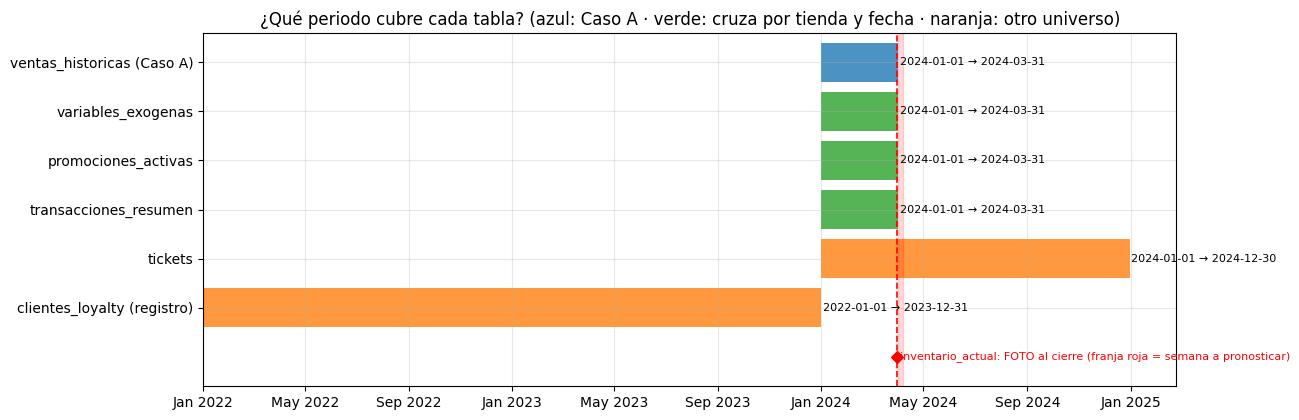

In [9]:
# LÍNEA DE TIEMPO de cobertura por tabla
import matplotlib.dates as mdates
rangos = []
def _rg(nombre, d, c1, c2=None, color="tab:blue"):
    if d is not None and c1 in d:
        rangos.append((nombre, pd.to_datetime(d[c1]).min(), pd.to_datetime(d[c2 or c1]).max(), color))
_rg("ventas_historicas (Caso A)", ventas, "fecha", color="tab:blue")
_rg("variables_exogenas", exo, "fecha", color="tab:green")
_rg("promociones_activas", promos, "fecha_inicio", "fecha_fin", "tab:green")
_rg("transacciones_resumen", trx, "timestamp", color="tab:green")
_rg("tickets", tkt, "fecha", color="tab:orange")
_rg("clientes_loyalty (registro)", loy, "fecha_registro", color="tab:orange")
fig, ax = plt.subplots(figsize=(13, 4.3))
for k, (nombre, a, b, c) in enumerate(rangos):
    ax.barh(k, (b - a).days + 1, left=mdates.date2num(a), color=c, alpha=0.8)
    ax.text(mdates.date2num(b) + 3, k, f"{a.date()} → {b.date()}", va="center", fontsize=8)
f_fin = ventas["fecha"].max()
ax.axvline(mdates.date2num(f_fin), color="red", ls="--", lw=1.2)
ax.scatter([mdates.date2num(f_fin)], [len(rangos)], marker="D", color="red", zorder=3)
ax.text(mdates.date2num(f_fin) + 3, len(rangos), "inventario_actual: FOTO al cierre (franja roja = semana a pronosticar)", va="center", fontsize=8, color="red")
ax.axvspan(mdates.date2num(f_fin) + 1, mdates.date2num(f_fin) + 7, color="red", alpha=0.15)
ax.set_yticks(range(len(rangos))); ax.set_yticklabels([r[0] for r in rangos]); ax.invert_yaxis()
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.set_ylim(len(rangos) + 0.6, -0.6)
ax.set_title("¿Qué periodo cubre cada tabla? (azul: Caso A · verde: cruza por tienda y fecha · naranja: otro universo)")
plt.tight_layout(); plt.show()

### Completitud de la grilla tienda × producto × día

In [10]:
dias = pd.date_range(ventas["fecha"].min(), ventas["fecha"].max(), freq="D")
n_tiendas, n_prod = ventas["id_tienda"].nunique(), ventas["id_producto"].nunique()
esperado = n_tiendas * n_prod * len(dias)

print(f"Rango: {dias.min().date()} -> {dias.max().date()} ({len(dias)} días = {len(dias)/7:.1f} semanas)")
print(f"Tiendas: {n_tiendas} | Productos: {n_prod} | SKU-Tienda: {n_tiendas*n_prod}")
print(f"Filas esperadas: {esperado:,} | Filas reales: {len(ventas):,} | Faltan: {esperado-len(ventas):,}")
print(f"Duplicados por llave (fecha, tienda, producto): {ventas.duplicated(['fecha','id_tienda','id_producto']).sum()}")

Rango: 2024-01-01 -> 2024-03-31 (91 días = 13.0 semanas)
Tiendas: 20 | Productos: 8 | SKU-Tienda: 160
Filas esperadas: 14,560 | Filas reales: 14,560 | Faltan: 0
Duplicados por llave (fecha, tienda, producto): 0


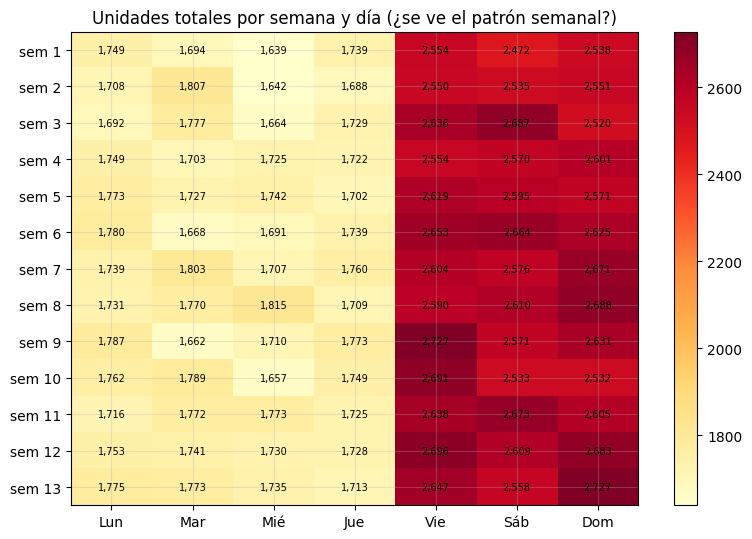

In [11]:
# CALENDARIO DE CALOR: unidades totales por semana y día de la semana
tot_dia = ventas.groupby("fecha")["unidades_vendidas"].sum()
cal_h = pd.DataFrame({"u": tot_dia}); cal_h["sem"] = (cal_h.index - cal_h.index.min()).days // 7 + 1; cal_h["dow"] = cal_h.index.dayofweek
mh = cal_h.pivot(index="sem", columns="dow", values="u"); mh.columns = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, ax = plt.subplots(figsize=(8, 5.5)); im = ax.imshow(mh.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(7)); ax.set_xticklabels(mh.columns); ax.set_yticks(range(len(mh))); ax.set_yticklabels([f"sem {s}" for s in mh.index])
for i in range(mh.shape[0]):
    for j in range(7): ax.text(j, i, f"{mh.values[i, j]:,.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Unidades totales por semana y día (¿se ve el patrón semanal?)"); plt.colorbar(im); plt.tight_layout(); plt.show()

### 🔎 Lectura — El patrón semanal es nítido y se repite las 13 semanas
- De lunes a jueves se venden ≈1,640–1,815 unidades al día en total; de viernes a domingo, ≈2,470–2,730. La diferencia es de ≈50 % (≈1,740 frente a ≈2,600).
- Es el mismo dibujo todas las semanas: no hay semanas raras ni un día que se salga del patrón. Tampoco se ve efecto de la Semana Santa (semana 13): sus valores caen dentro del rango de las demás.
- El día de la semana es la variable más importante y se conoce de antemano (la semana a pronosticar empieza el lunes 1-abr). Ignorarlo causaría un error sistemático grande: el índice semanal va de ≈0.77 (lunes a jueves) a ≈1.30 (viernes a domingo).

**Qué se retiene de 1.2**
- Hay 13 semanas completas (del lunes 1-ene al domingo 31-mar). No hay estacionalidad mensual ni anual que aprender, solo la semanal.
- La semana a pronosticar va del lunes 1 al domingo 7 de abril: completa y sin festivos.
- `tickets` cubre todo 2024 (solo ≈25 % cae en ene–mar). Es otro universo de datos, no un complemento de las ventas.
- `promociones_activas` cubre del 1-ene al 31-mar (la última promo empieza el 23-mar y todas terminan el 31-mar), así que no hay promociones conocidas para la semana a pronosticar.
- `clientes_loyalty` registra clientes de 2022–2023, anteriores al periodo de ventas.

> **Sigue:** ¿se puede confiar en los datos?

## 1.3 Calidad estructural de los datos
<sup><a href="#Contenido">↑ Contenido</a></sup>
*Pregunta: ¿se puede confiar en los datos?*
Se revisan nulos, duplicados, integridad entre tablas, negativos y precios incoherentes. Los ceros y los valores atípicos se tratan en la Parte 2.

In [12]:
def resumen_calidad(df: pd.DataFrame, nombre: str) -> pd.DataFrame:
    print(f"{nombre}: {df.shape[0]:,} filas x {df.shape[1]} cols | duplicados exactos: {df.duplicated().sum()}")
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%nulos": (df.isna().mean() * 100).round(2),
        "unicos": df.nunique(),
    })

for nombre, df in [("ventas", ventas), ("inventario", inventario), ("catalogo", catalogo),
                   ("tiendas", tiendas), ("tendencias", tendencias)]:
    display(resumen_calidad(df, nombre))

ventas: 14,560 filas x 4 cols | duplicados exactos: 0


,dtype,nulos,%nulos,unicos
fecha,datetime64[ns],0,0.00,91
id_tienda,object,0,0.00,20
id_producto,object,0,0.00,8
unidades_vendidas,int64,0,0.00,55


inventario: 160 filas x 3 cols | duplicados exactos: 0


,dtype,nulos,%nulos,unicos
id_tienda,object,0,0.00,20
id_producto,object,0,0.00,8
stock_actual,int64,0,0.00,55


catalogo: 8 filas x 6 cols | duplicados exactos: 0


,dtype,nulos,%nulos,unicos
id_producto,object,0,0.00,8
nombre,object,0,0.00,8
categoria,object,0,0.00,2
costo_unitario,int64,0,0.00,5
precio_venta,int64,0,0.00,5
costo_almacenamiento_semanal,int64,0,0.00,6


tiendas: 20 filas x 3 cols | duplicados exactos: 0


,dtype,nulos,%nulos,unicos
id_tienda,object,0,0.00,20
ciudad,object,0,0.00,3
tamaño_m2,int64,0,0.00,15


tendencias: 160 filas x 3 cols | duplicados exactos: 0


,dtype,nulos,%nulos,unicos
id_tienda,object,0,0.00,20
id_producto,object,0,0.00,8
trend_type,object,0,0.00,4


### Integridad referencial del Caso A (¿todo cruza entre tablas?)
Las llaves de las carpetas 02 y 03 (qué tiendas y productos cruzan con ventas) están en la tabla de 1.1.

In [13]:
def faltantes(a, b, nombre):
    dif = set(a) - set(b)
    print(f"{nombre}: {len(dif)} sin match {sorted(dif)[:5]}")

faltantes(ventas["id_tienda"], tiendas["id_tienda"], "tiendas en ventas que no están en maestro")
faltantes(ventas["id_producto"], catalogo["id_producto"], "productos en ventas que no están en catálogo")
faltantes(inventario["id_tienda"], tiendas["id_tienda"], "tiendas en inventario que no están en maestro")
faltantes(inventario["id_producto"], catalogo["id_producto"], "productos en inventario que no están en catálogo")

llaves_v = set(zip(ventas["id_tienda"], ventas["id_producto"]))
llaves_i = set(zip(inventario["id_tienda"], inventario["id_producto"]))
print("SKU-Tienda en ventas vs inventario -> sólo ventas:", len(llaves_v - llaves_i), "| sólo inventario:", len(llaves_i - llaves_v))

tiendas en ventas que no están en maestro: 0 sin match []
productos en ventas que no están en catálogo: 0 sin match []
tiendas en inventario que no están en maestro: 0 sin match []
productos en inventario que no están en catálogo: 0 sin match []
SKU-Tienda en ventas vs inventario -> sólo ventas: 0 | sólo inventario: 0


### Valores sospechosos: negativos, ceros, precios/costos incoherentes

In [14]:
print("Ventas negativas:", (ventas["unidades_vendidas"] < 0).sum())
print("Ventas == 0     :", (ventas["unidades_vendidas"] == 0).sum(), f"({(ventas['unidades_vendidas']==0).mean():.2%})")
print("Stock negativo  :", (inventario["stock_actual"] < 0).sum(), "| stock == 0:", (inventario["stock_actual"] == 0).sum())
print("Precio <= costo :", (catalogo["precio_venta"] <= catalogo["costo_unitario"]).sum())
print("Tamaño m2 <= 0  :", (tiendas["tamaño_m2"] <= 0).sum())
print("Tipos de tendencia:", tendencias["trend_type"].value_counts().to_dict())
display(ventas["unidades_vendidas"].describe())

Ventas negativas: 0
Ventas == 0     : 26 (0.18%)
Stock negativo  : 0 | stock == 0: 5
Precio <= costo : 0
Tamaño m2 <= 0  : 0
Tipos de tendencia: {'seasonal': 57, 'down': 44, 'random': 32, 'up': 27}


count   14,560.00
mean        13.18
std          7.79
min          0.00
25%          7.00
50%         12.00
75%         17.00
max         58.00
Name: unidades_vendidas, dtype: float64

### 🔎 Lectura — Calidad de datos
- Los datos están limpios: grilla completa (14,560 = 20 tiendas × 8 productos × 91 días), sin duplicados, nulos ni negativos, y con todas las llaves cruzando entre tablas. No hay nada que reparar.
- Hay 26 ceros en total (0.18 %), concentrados en pocos SKU-tienda: `STORE_17 / Pan de Bono` (≈7.7 % de sus días), `STORE_07 / Tinto` (≈4.4 %) y `STORE_17 / Tinto` (≈3.3 %). Son las tiendas más pequeñas (15 y 19 m²) y los productos de menor rotación (Pan de Bono 6.8 u/día, Tinto 8.2). Ahí un cero es lo esperable de una demanda baja y aleatoria, no necesariamente un quiebre (se confirma en 2.3).
- Solo 5 SKU-tienda tienen stock en 0; son los más urgentes del pedido.
- No hace falta imputar ni borrar nada. Sí conviene que el modelo no ignore los SKU-tienda de baja rotación, donde una distribución de Poisson o binomial negativa pesa más que la normal.

> **Sigue:** ¿cómo se comporta la demanda?

## 1.4 Radiografía descriptiva: quién vende qué, cuándo y cuánto
<sup><a href="#Contenido">↑ Contenido</a></sup>
*Pregunta: ¿cómo se comporta la demanda y qué parte de ella se puede predecir?*
Primero un mapa de qué compone una venta y después las vistas por tienda, ciudad, producto y tiempo.

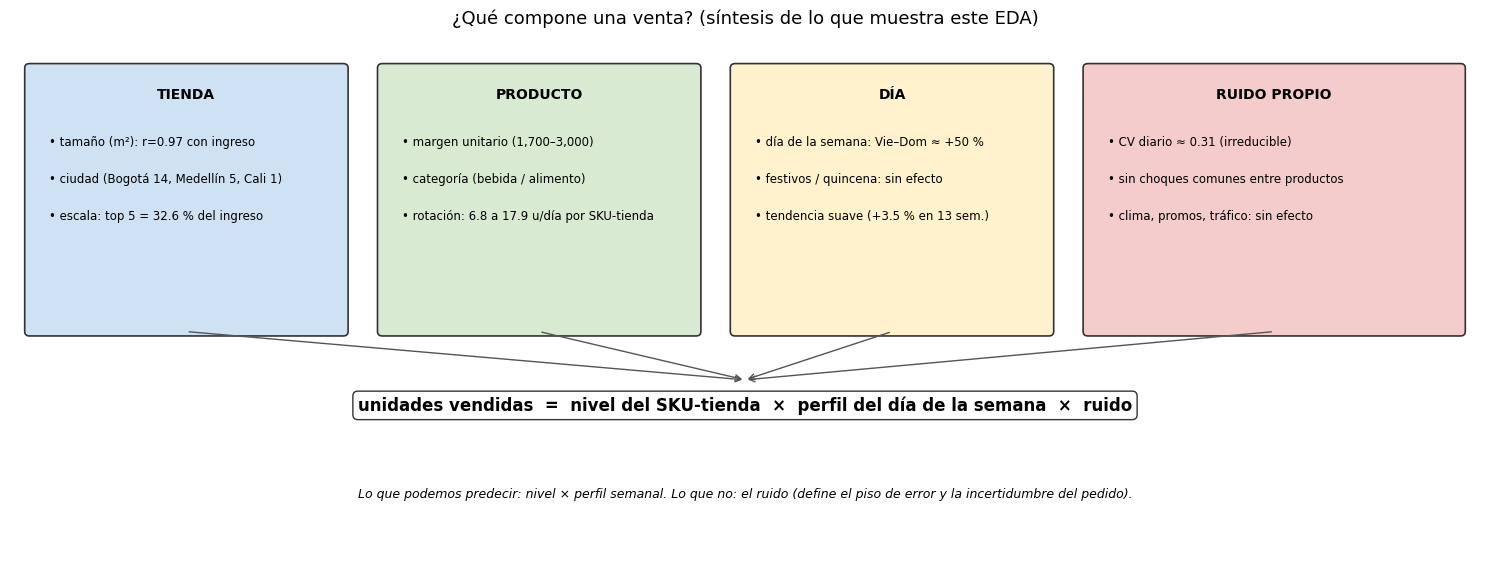

In [15]:
import matplotlib.patches as mpatches
# MAPA CONCEPTUAL: qué compone una venta (SKU-tienda-día)
fig, ax = plt.subplots(figsize=(15, 5.8)); ax.set_xlim(0, 15); ax.set_ylim(0, 6); ax.axis("off")
def b(x, y, w, h, titulo, items, color):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=color, ec="#333", lw=1.2))
    ax.text(x + w / 2, y + h - 0.35, titulo, ha="center", fontweight="bold", fontsize=10)
    for k, it in enumerate(items): ax.text(x + 0.2, y + h - 0.85 - 0.42 * k, "• " + it, fontsize=8.5, va="center")
_ciu = tiendas["ciudad"].value_counts(); _ciu_txt = ", ".join(f"{k} {v}" for k, v in _ciu.items())
_ing = (ventas.merge(catalogo[["id_producto", "precio_venta"]], on="id_producto").assign(i=lambda x: x["unidades_vendidas"] * x["precio_venta"])
            .groupby("id_tienda")["i"].sum()); _m2 = tiendas.set_index("id_tienda")["tamaño_m2"]
_r_m2 = _ing.corr(_m2.reindex(_ing.index)); _top5 = _ing.nlargest(5).sum() / _ing.sum() * 100
_rot = ventas.groupby("id_producto")["unidades_vendidas"].mean(); _mg = catalogo["precio_venta"] - catalogo["costo_unitario"]
b(0.2, 2.6, 3.2, 3.0, "TIENDA", [f"tamaño (m²): r={_r_m2:.2f} con ingreso", f"ciudad ({_ciu_txt})", f"escala: top 5 = {_top5:.1f} % del ingreso"], "#cfe2f3")
b(3.8, 2.6, 3.2, 3.0, "PRODUCTO", [f"margen unitario ({_mg.min():,.0f}–{_mg.max():,.0f})", "categoría (bebida / alimento)", f"rotación: {_rot.min():.1f} a {_rot.max():.1f} u/día por SKU-tienda"], "#d9ead3")
b(7.4, 2.6, 3.2, 3.0, "DÍA", ["día de la semana: Vie–Dom ≈ +50 %", "festivos / quincena: sin efecto", "tendencia suave (+3.5 % en 13 sem.)"], "#fff2cc")
b(11.0, 2.6, 3.8, 3.0, "RUIDO PROPIO", ["CV diario ≈ 0.31 (irreducible)", "sin choques comunes entre productos", "clima, promos, tráfico: sin efecto"], "#f4cccc")
ax.text(7.5, 1.7, "unidades vendidas  =  nivel del SKU-tienda  ×  perfil del día de la semana  ×  ruido", ha="center", fontsize=12, fontweight="bold",
        bbox=dict(boxstyle="round", fc="white", ec="#333"))
for x0 in (1.8, 5.4, 9.0, 12.9): ax.annotate("", xy=(7.5, 2.05), xytext=(x0, 2.6), arrowprops=dict(arrowstyle="->", color="#555"))
ax.text(7.5, 0.7, "Lo que podemos predecir: nivel × perfil semanal. Lo que no: el ruido (define el piso de error y la incertidumbre del pedido).", ha="center", fontsize=9, style="italic")
ax.set_title("¿Qué compone una venta? (síntesis de lo que muestra este EDA)", fontsize=13); plt.tight_layout(); plt.show()

### 🔎 Lectura — Qué compone una venta
Es una síntesis de lo que muestra el EDA: una venta es el nivel del SKU-tienda, multiplicado por el perfil del día de la semana y por un ruido. Lo predecible (nivel y perfil semanal) lo captura un modelo sencillo. El ruido diario (CV residual ≈0.31) no se puede reducir y fija el piso de error y el ancho del intervalo. Las cifras del cuadro salen de los datos del notebook (correlación de m² con ingreso, reparto por ciudad, concentración del top 5, margen y rotación).

### Ventas por tienda y producto

In [16]:
df = (ventas[["fecha", "id_tienda", "id_producto", "unidades_vendidas"]]
      .merge(catalogo, on="id_producto", how="left")
      .merge(tiendas, on="id_tienda", how="left"))
df["ingreso"] = df["unidades_vendidas"] * df["precio_venta"]
df["margen"] = df["unidades_vendidas"] * (df["precio_venta"] - df["costo_unitario"])
df["semana"] = df["fecha"].dt.to_period("W").dt.start_time
df["dow"] = df["fecha"].dt.dayofweek
n_dias = df["fecha"].nunique()

t = df.groupby("id_tienda").agg(unidades=("unidades_vendidas", "sum"), ingreso=("ingreso", "sum"), margen=("margen", "sum")).reset_index()
t = t.merge(tiendas, on="id_tienda")
t["%unidades"] = t["unidades"] / t["unidades"].sum() * 100
t["%ingreso"] = t["ingreso"] / t["ingreso"].sum() * 100
t["%margen"] = t["margen"] / t["margen"].sum() * 100
t["ingreso_por_m2_dia"] = t["ingreso"] / t["tamaño_m2"] / n_dias
t["ticket_unid_dia"] = t["unidades"] / n_dias
t = t.sort_values("ingreso", ascending=False)
display(t)

,id_tienda,unidades,ingreso,margen,ciudad,tamaño_m2,%unidades,%ingreso,%margen,ingreso_por_m2_dia,ticket_unid_dia
15,STORE_16,14582,51446400,32755500,Bogotá,49,7.60,7.55,7.57,"11,537.65",160.24
7,STORE_08,14252,50676100,32090500,Bogotá,49,7.43,7.44,7.41,"11,364.90",156.62
2,STORE_03,11658,41052500,26082300,Bogotá,42,6.08,6.02,6.02,"10,741.10",128.11
3,STORE_04,11281,40849400,25958100,Cali,40,5.88,6.00,6.00,"11,222.36",123.97
1,STORE_02,10690,37883600,24117400,Bogotá,43,5.57,5.56,5.57,"9,681.47",117.47
4,STORE_05,10248,37255000,23631200,Bogotá,34,5.34,5.47,5.46,"12,041.05",112.62
11,STORE_12,10367,36968400,23483700,Medellín,35,5.40,5.43,5.42,"11,607.03",113.92
18,STORE_19,10360,36193800,23080800,Bogotá,37,5.40,5.31,5.33,"10,749.57",113.85
19,STORE_20,9890,35737100,22686700,Medellín,33,5.15,5.24,5.24,"11,900.47",108.68
17,STORE_18,10033,35345400,22428100,Bogotá,38,5.23,5.19,5.18,"10,221.34",110.25


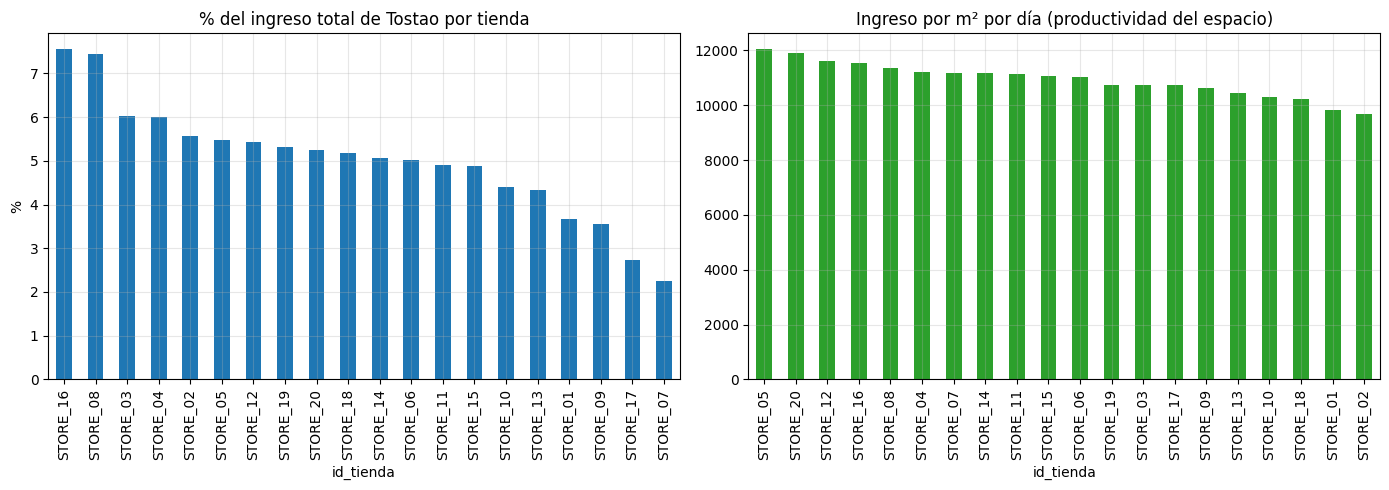

Top 5 tiendas concentran: 32.6% del ingreso


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
t.plot.bar(x="id_tienda", y="%ingreso", ax=axes[0], legend=False, color="tab:blue")
axes[0].set_title("% del ingreso total de Tostao por tienda"); axes[0].set_ylabel("%")
t.sort_values("ingreso_por_m2_dia", ascending=False).plot.bar(x="id_tienda", y="ingreso_por_m2_dia", ax=axes[1], legend=False, color="tab:green")
axes[1].set_title("Ingreso por m² por día (productividad del espacio)")
plt.tight_layout(); plt.show()

print("Top 5 tiendas concentran:", f"{t.head(5)['%ingreso'].sum():.1f}% del ingreso")

### 🔎 Lectura — Concentración de ventas por tienda
- `STORE_16` y `STORE_08` (ambas en Bogotá, 49 m²) suman ≈15 % de las unidades y del ingreso (7.6 % y 7.4 %). El top 5 concentra 32.6 % del ingreso. No hay una tienda dominante, pero sí un grupo de tiendas grandes.
- En el otro extremo, `STORE_07` (2.2 %) y `STORE_17` (2.7 %) casi no pesan: un error de pronóstico ahí cuesta poco en pesos.
- Para el modelo, el pronóstico debe medirse con un WAPE ponderado por volumen o margen y no solo con el error promedio por SKU-tienda, porque equivocarse en `STORE_16` duele ≈3.5 veces más que en `STORE_07`.

,tiendas,ingreso,m2,%ingreso,ingreso_por_tienda
ciudad,,,,,
Bogotá,14,495605300,501,72.73,"35,400,378.57"
Cali,1,40849400,40,6.00,"40,849,400.00"
Medellín,5,144934800,143,21.27,"28,986,960.00"


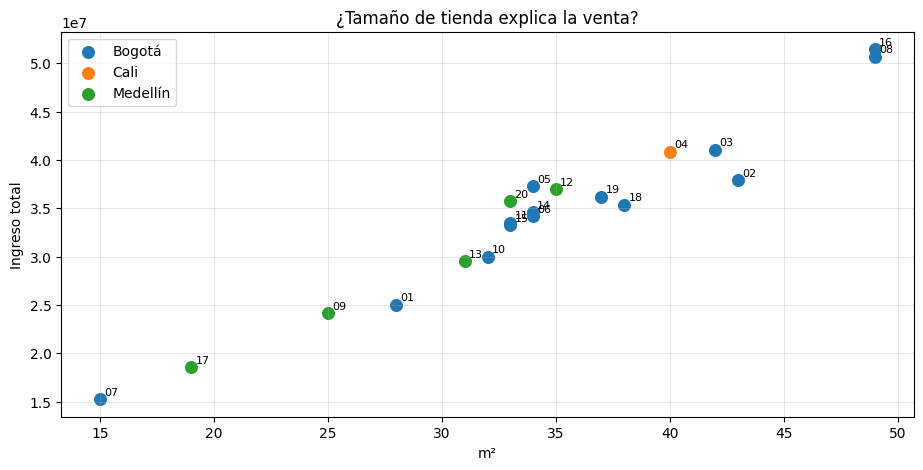

Correlación m² vs ingreso: 0.973


In [18]:
# Ventas por ciudad y por tamaño
ciudad = t.groupby("ciudad").agg(tiendas=("id_tienda", "count"), ingreso=("ingreso", "sum"), m2=("tamaño_m2", "sum"))
ciudad["%ingreso"] = ciudad["ingreso"] / ciudad["ingreso"].sum() * 100
ciudad["ingreso_por_tienda"] = ciudad["ingreso"] / ciudad["tiendas"]
display(ciudad)

fig, ax = plt.subplots()
for c, s in t.groupby("ciudad"):
    ax.scatter(s["tamaño_m2"], s["ingreso"], label=c, s=70)
for _, r in t.iterrows():
    ax.annotate(r["id_tienda"].replace("STORE_", ""), (r["tamaño_m2"], r["ingreso"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("m²"); ax.set_ylabel("Ingreso total"); ax.set_title("¿Tamaño de tienda explica la venta?"); ax.legend()
plt.show()
print("Correlación m² vs ingreso:", round(t["tamaño_m2"].corr(t["ingreso"]), 3))

### 🔎 Lectura — Tamaño de tienda y ciudad
- La correlación entre m² e ingreso es 0.97: el tamaño explica casi toda la diferencia de ventas entre tiendas. Por eso `tamaño_m2` sirve como proxy de escala y como variable del modelo (o para normalizar).
- Bogotá aporta 72.7 % del ingreso con 14 tiendas, Medellín 21.3 % con 5 y Cali 6 % con una sola (`STORE_04`).
- Cali parece mejor por tienda ($40.8M frente a $35.4M en Bogotá y $29.0M en Medellín), pero con una sola tienda no se puede concluir nada de la ciudad, y las tiendas de Medellín son más pequeñas (≈28.6 m² frente a 35.8 m² en Bogotá). La diferencia es de tamaño, no de ciudad.
- Para el modelo, `ciudad` no debería ser variable principal (Cali tiene una sola tienda); `tamaño_m2` y la identidad de la tienda sí.

In [19]:
# Mix de productos: ¿qué vende más y qué deja más margen?
p = df.groupby(["id_producto", "nombre", "categoria"]).agg(unidades=("unidades_vendidas", "sum"), ingreso=("ingreso", "sum"), margen=("margen", "sum")).reset_index()
p["%unidades"] = p["unidades"] / p["unidades"].sum() * 100
p["%margen"] = p["margen"] / p["margen"].sum() * 100
display(p.sort_values("margen", ascending=False))

,id_producto,nombre,categoria,unidades,ingreso,margen,%unidades,%margen
7,PROD_008,Jugo de Naranja,Bebidas,29833,149165000,89499000,15.55,20.67
5,PROD_006,Croissant,Alimentos,28895,101132500,66458500,15.06,15.35
2,PROD_003,Cappuccino,Bebidas,21249,95620500,63747000,11.08,14.72
6,PROD_007,Pastel de Pollo,Alimentos,31469,110141500,62938000,16.40,14.54
4,PROD_005,Buñuelo,Alimentos,32489,81222500,55231300,16.93,12.76
1,PROD_002,Café con Leche,Bebidas,20580,72030000,47334000,10.73,10.93
0,PROD_001,Tinto,Bebidas,14971,37427500,25450700,7.80,5.88
3,PROD_004,Pan de Bono,Alimentos,12375,34650000,22275000,6.45,5.15


### 🔎 Lectura — Mix de productos
- El Jugo de Naranja es el que más margen deja: 15.6 % de las unidades pero 20.7 % del margen. Tiene margen alto (3,000) y también es el más caro de almacenar (50).
- El Buñuelo vende más unidades (16.9 %) pero aporta solo 12.8 % del margen; Pan de Bono y Tinto son los de menor peso (5–6 % del margen).
- Para el optimizador: el valor se concentra en pocos productos. Jugo, Croissant y Cappuccino generan ≈51 % del margen, así que mejorar 1 % el error en el Jugo vale más que en el Tinto.

In [20]:
# Tienda con productos más caros/baratos vendidos (precio promedio ponderado por unidades) y margen % realizado
t2 = df.groupby("id_tienda").apply(lambda s: pd.Series({
    "precio_prom_ponderado": np.average(s["precio_venta"], weights=s["unidades_vendidas"]),
    "margen_pct_realizado": s["margen"].sum() / s["ingreso"].sum(),
})).reset_index().sort_values("precio_prom_ponderado", ascending=False)
display(t2)

,id_tienda,precio_prom_ponderado,margen_pct_realizado
4,STORE_05,"3,635.34",0.63
3,STORE_04,"3,621.08",0.64
19,STORE_20,"3,613.46",0.63
6,STORE_07,"3,606.15",0.64
5,STORE_06,"3,581.71",0.63
12,STORE_13,"3,570.39",0.64
8,STORE_09,"3,567.58",0.63
11,STORE_12,"3,565.97",0.64
16,STORE_17,"3,565.19",0.63
7,STORE_08,"3,555.72",0.63


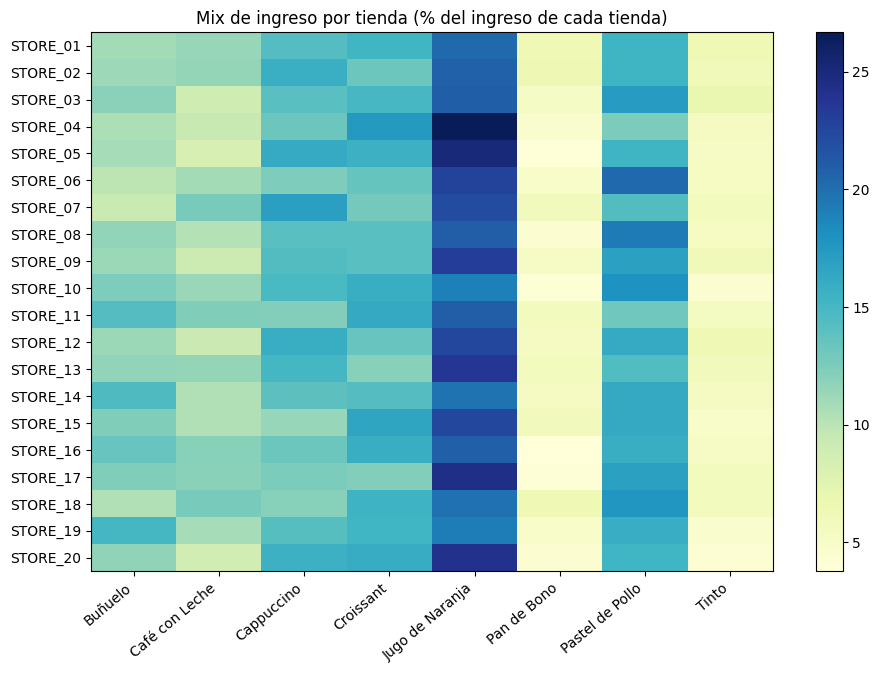

In [21]:
# Heatmap tienda x producto (% del ingreso de la tienda) -> ¿mix distinto entre tiendas?
mix = df.pivot_table(index="id_tienda", columns="nombre", values="ingreso", aggfunc="sum")
mix = mix.div(mix.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(mix.values, aspect="auto", cmap="YlGnBu"); ax.grid(False)
ax.set_xticks(range(mix.shape[1])); ax.set_xticklabels(mix.columns, rotation=40, ha="right")
ax.set_yticks(range(mix.shape[0])); ax.set_yticklabels(mix.index)
ax.set_title("Mix de ingreso por tienda (% del ingreso de cada tienda)"); plt.colorbar(im); plt.show()

### 🔎 Lectura — ¿Hay tiendas que vendan productos más caros o más baratos?
- No de forma relevante. El precio promedio ponderado varía solo entre $3,486 y $3,635 (≈±2 %) y el margen realizado es 63–64 % en todas las tiendas. Las tiendas no se diferencian por ser premium o económicas, sino por su escala (m²).
- El mapa de calor lo confirma: el mix es parecido en todas (el Jugo pesa ≈20–27 % del ingreso en casi todas). Pesan más en Jugo `STORE_04`, `STORE_05`, `STORE_13`, `STORE_17` y `STORE_20`; pesan más en Pastel de Pollo `STORE_06`, `STORE_08`, `STORE_10` y `STORE_18`. Son matices, no perfiles distintos.
- Existe un ranking (`STORE_05` arriba, `STORE_11` y `STORE_14` abajo), pero la brecha de 4 % es demasiado pequeña para segmentar tiendas con ella.

### Serie temporal y estacionalidad semanal

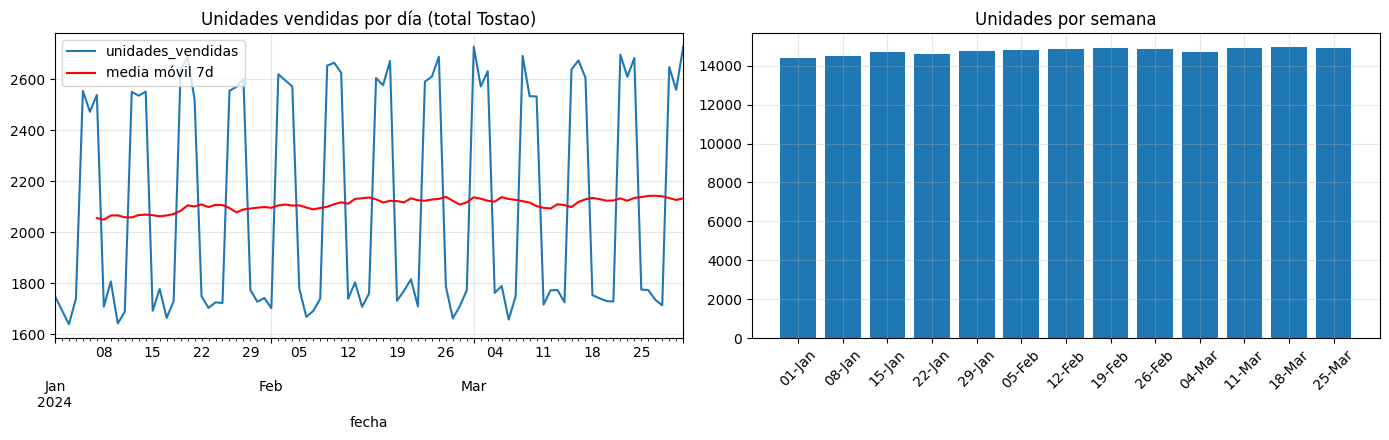

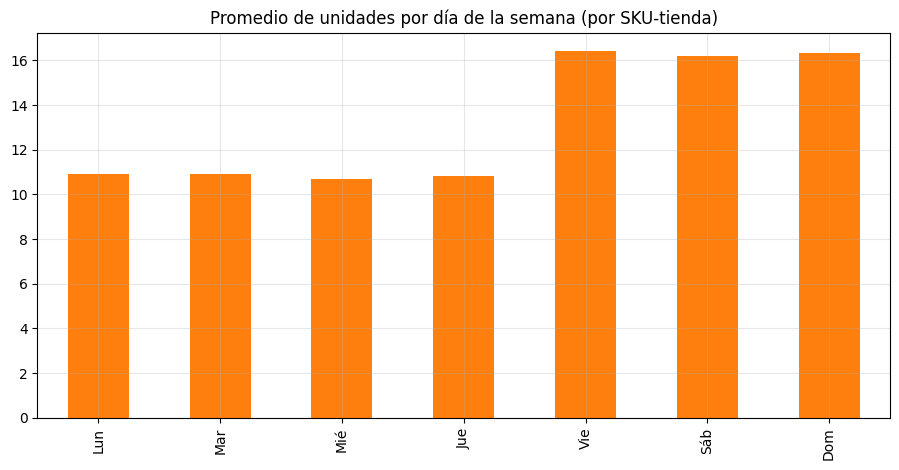

In [22]:
diario = df.groupby("fecha")["unidades_vendidas"].sum()
semanal = df.groupby("semana")["unidades_vendidas"].sum()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
diario.plot(ax=axes[0]); diario.rolling(7).mean().plot(ax=axes[0], color="red", label="media móvil 7d")
axes[0].set_title("Unidades vendidas por día (total Tostao)"); axes[0].legend()
etiq = [pd.Timestamp(d.start_time if hasattr(d, "start_time") else d).strftime("%d-%b") for d in semanal.index]
axes[1].bar(range(len(semanal)), semanal.values); axes[1].set_title("Unidades por semana")
axes[1].set_xticks(range(len(semanal))); axes[1].set_xticklabels(etiq, rotation=45)
plt.tight_layout(); plt.show()

dow = df.groupby("dow")["unidades_vendidas"].mean()
dow.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
dow.plot.bar(title="Promedio de unidades por día de la semana (por SKU-tienda)", color="tab:orange"); plt.show()

### 🔎 Lectura — Serie temporal y patrón semanal
- El patrón semanal es muy marcado: viernes, sábado y domingo venden ≈16.3 u por SKU-tienda frente a ≈10.8 de lunes a jueves (≈+50 %). Es la señal más fuerte de todo el dataset, mucho más que cualquier tendencia.
- El nivel semanal es casi plano: ≈14,400 u la primera semana y ≈14,900 la última (≈+3.5 % en 13 semanas). No hay crecimiento ni caída global importante.
- Implicaciones:
  1. El modelo debe incluir el día de la semana (o modelar a nivel diario y sumar a semana). Un promedio móvil plano de 7 días lo ignora, pero como toda semana completa tiene 4 días bajos y 3 altos, el total semanal sí se puede predecir bien.
  2. La semana a pronosticar empieza el lunes 1-abr-2024 (4 días bajos y 3 altos): una semana típica y completa.
  3. Con solo 13 semanas no hay estacionalidad mensual ni anual que aprender; hay que decirlo como limitación en la presentación.

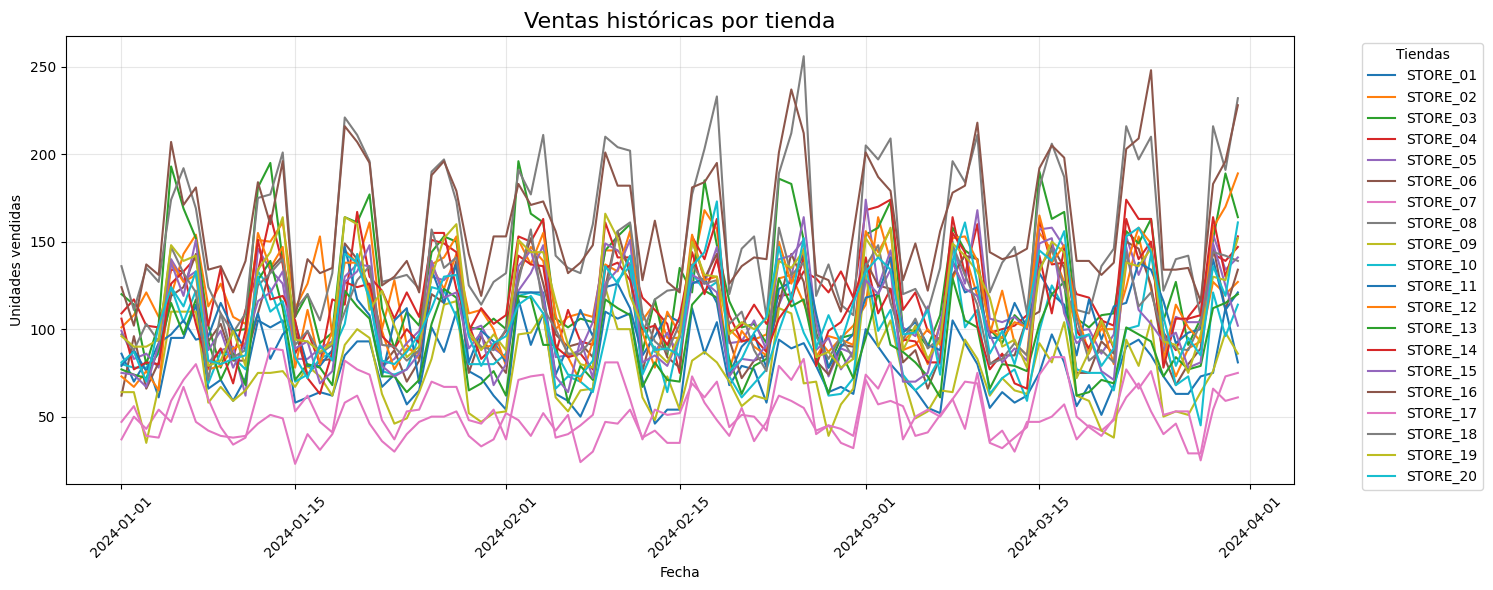

In [23]:
# Tu función original: ventas históricas por tienda (todas las tiendas en un solo gráfico)
def graficar_ventas_tiendas(df):

    # Convertir fecha a formato datetime
    df = df.copy()
    df["fecha"] = pd.to_datetime(df["fecha"])

    # Agrupar ventas por fecha y tienda
    ventas = df.groupby(
        ["fecha", "id_tienda"]
    )["unidades_vendidas"].sum().reset_index()

    # Crear gráfico
    plt.figure(figsize=(15, 6))

    for tienda in ventas["id_tienda"].unique():

        datos = ventas[ventas["id_tienda"] == tienda]

        plt.plot(
            datos["fecha"],
            datos["unidades_vendidas"],
            label=tienda,
            linewidth=1.5
        )

    plt.title("Ventas históricas por tienda", fontsize=16)
    plt.xlabel("Fecha")
    plt.ylabel("Unidades vendidas")
    plt.legend(title="Tiendas", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

df_ventas = ventas
graficar_ventas_tiendas(df_ventas)

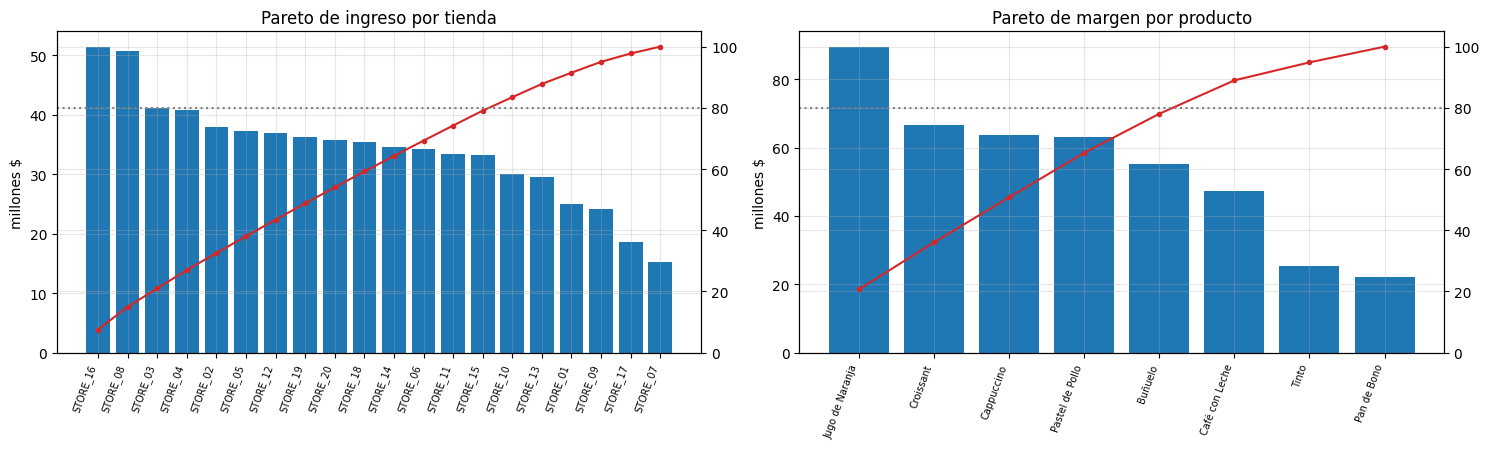

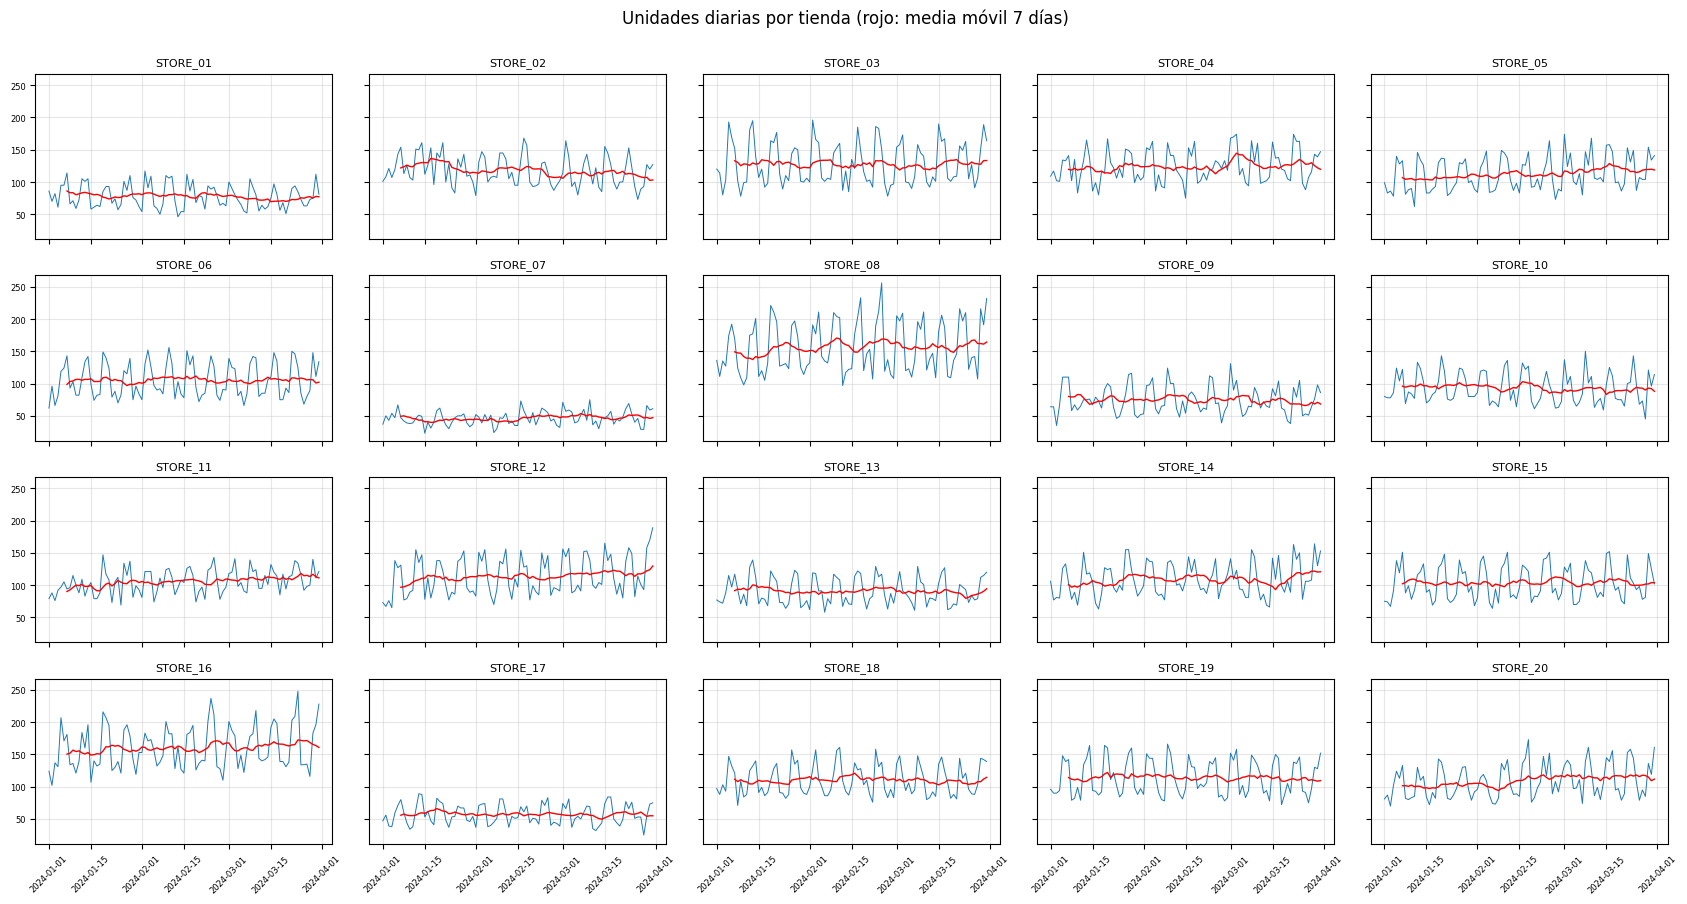

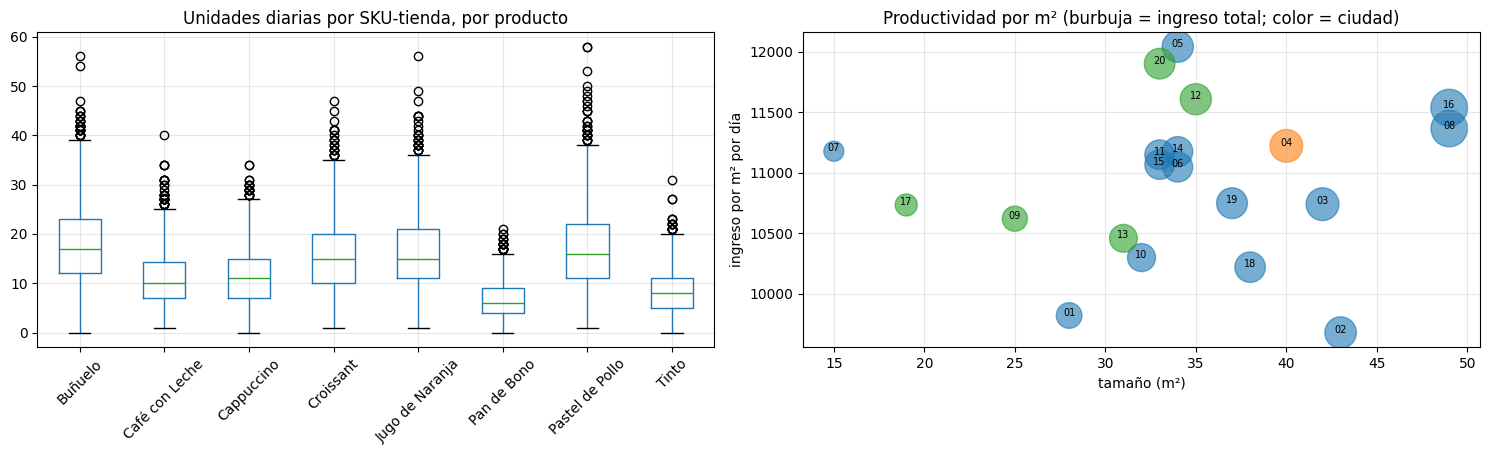

In [24]:
# Más vistas descriptivas: Pareto, tiendas una por una, distribución por producto y productividad por m²
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, (col, g_, tit) in zip(axes, [("id_tienda", df.groupby("id_tienda")["ingreso"].sum(), "Pareto de ingreso por tienda"),
                                      ("nombre", df.groupby("nombre")["margen"].sum(), "Pareto de margen por producto")]):
    s_ = g_.sort_values(ascending=False); acum = s_.cumsum() / s_.sum() * 100
    ax.bar(range(len(s_)), s_.values / 1e6, color="tab:blue"); ax.set_xticks(range(len(s_))); ax.set_xticklabels(s_.index, rotation=70, ha="right", fontsize=7)
    ax2 = ax.twinx(); ax2.plot(range(len(s_)), acum.values, color="tab:red", marker="o", ms=3); ax2.axhline(80, color="gray", ls=":"); ax2.set_ylim(0, 105)
    ax.set_title(tit); ax.set_ylabel("millones $")
plt.tight_layout(); plt.show()

# Las 20 tiendas, una por una (misma escala vertical para comparar)
tiend = sorted(ventas["id_tienda"].unique()); fig, axes = plt.subplots(4, 5, figsize=(17, 9), sharex=True, sharey=True)
for ax, tdn in zip(axes.ravel(), tiend):
    s_ = ventas[ventas["id_tienda"] == tdn].groupby("fecha")["unidades_vendidas"].sum()
    ax.plot(s_.index, s_.values, lw=0.7, color="tab:blue"); ax.plot(s_.index, s_.rolling(7).mean(), color="red", lw=1)
    ax.set_title(tdn, fontsize=8); ax.tick_params(labelsize=6); ax.tick_params(axis="x", rotation=45)
plt.suptitle("Unidades diarias por tienda (rojo: media móvil 7 días)", y=1.0); plt.tight_layout(); plt.show()

# Distribución de unidades diarias por producto y productividad por m² (burbujas)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
orden = ventas.merge(catalogo[["id_producto", "nombre"]], on="id_producto")
orden.boxplot(column="unidades_vendidas", by="nombre", ax=axes[0], rot=45); axes[0].set_title("Unidades diarias por SKU-tienda, por producto"); axes[0].set_xlabel(""); plt.sca(axes[0]); plt.suptitle("")
tt = t.copy(); colores = {"Bogotá": "tab:blue", "Medellín": "tab:green", "Cali": "tab:orange"}
axes[1].scatter(tt["tamaño_m2"], tt["ingreso_por_m2_dia"], s=tt["ingreso"] / tt["ingreso"].max() * 700, c=tt["ciudad"].map(colores), alpha=0.6)
for _, r in tt.iterrows(): axes[1].annotate(r["id_tienda"][-2:], (r["tamaño_m2"], r["ingreso_por_m2_dia"]), fontsize=7, ha="center")
axes[1].set_xlabel("tamaño (m²)"); axes[1].set_ylabel("ingreso por m² por día"); axes[1].set_title("Productividad por m² (burbuja = ingreso total; color = ciudad)")
plt.tight_layout(); plt.show()

### 🔎 Lectura — Más vistas descriptivas
- Pareto de tiendas: el ingreso está repartido. `STORE_16` y `STORE_08` pasan de 50 millones, y hacen falta ≈14–15 de las 20 tiendas para llegar al 80 %. Ninguna tienda sostiene el negocio.
- Pareto de productos (margen): el Jugo de Naranja aporta el mayor margen (≈89 millones, ≈21 %); Tinto y Pan de Bono, los menores (≈25 y ≈22 millones). Se llega al 80 % del margen con 5–6 de los 8 productos.
- Las 20 tiendas, una por una: el mismo patrón semanal en todas, con niveles muy distintos y estables: `STORE_08` (≈150–165 u/día) y `STORE_16` (≈160) arriba; `STORE_07` (≈45–50), `STORE_17` (≈55–60) y `STORE_01` (≈75–80) abajo. No hay quiebres de nivel ni tiendas con comportamiento propio; se nota un ligero ascenso en `STORE_16` y un descenso en `STORE_20` hacia el final.
- Distribución por producto: las medianas diarias por SKU-tienda son ≈15–17 u (Buñuelo, Pastel, Jugo, Croissant), ≈10–11 (Café, Cappuccino) y ≈6–8 (Pan de Bono, Tinto). Los puntos atípicos son todos hacia arriba (hasta ≈55–58 u), lo que explica los picos de 2.2.
- Productividad por m²: el ingreso por m² por día se mueve en un rango estrecho (≈9,700–12,000). El tamaño está correlacionado con la escala de ventas (r = 0.97) y casi nada más. Cali es una sola tienda, por eso la ciudad no aporta (H3).

### Comportamiento de la demanda por SKU-Tienda

Estas métricas indican qué modelo conviene y qué tan agresivo pedir:
- CV (coeficiente de variación): si es alto, la demanda es difícil de predecir y el intervalo es ancho.
- ADI (intervalo promedio entre ventas): si es alto, la demanda es intermitente (muchos ceros).
- Tendencia (pendiente): indica si hay crecimiento o caída, lo que afecta a los rezagos y las medias móviles.
- Estacionalidad semanal: amplitud entre el mejor y el peor día.

In [25]:
def metricas_sku(s: pd.DataFrame) -> pd.Series:
    y = s.sort_values("fecha")["unidades_vendidas"].values.astype(float)
    t_ = np.arange(len(y))
    media = y.mean()
    slope = np.polyfit(t_, y, 1)[0]
    con_venta = (y > 0).sum()
    adi = len(y) / con_venta if con_venta else np.inf
    dow_m = s.groupby(s["fecha"].dt.dayofweek)["unidades_vendidas"].mean()
    return pd.Series({
        "media": media, "std": y.std(ddof=1), "cv": y.std(ddof=1) / media if media else np.nan,
        "pct_ceros": (y == 0).mean(), "adi": adi,
        "tendencia_rel_dia": slope / media if media else np.nan,   # % de cambio por día
        "amp_dow": (dow_m.max() - dow_m.min()) / media if media else np.nan,
    })

sku = (ventas.groupby(["id_tienda", "id_producto"]).apply(metricas_sku).reset_index()
       .merge(tendencias, on=["id_tienda", "id_producto"], how="left")
       .merge(catalogo[["id_producto", "nombre", "precio_venta", "costo_unitario"]], on="id_producto"))
sku["margen_total"] = sku["media"] * n_dias * (sku["precio_venta"] - sku["costo_unitario"])

# Clasificación de patrón de demanda (Syntetos-Boylan)
sku["cv2"] = sku["cv"] ** 2
def patron(r):
    if r["adi"] < 1.32 and r["cv2"] < 0.49: return "Smooth"
    if r["adi"] >= 1.32 and r["cv2"] < 0.49: return "Intermittent"
    if r["adi"] < 1.32 and r["cv2"] >= 0.49: return "Erratic"
    return "Lumpy"
sku["patron"] = sku.apply(patron, axis=1)

# ABC por margen y XYZ por CV
sku = sku.sort_values("margen_total", ascending=False)
cum = sku["margen_total"].cumsum() / sku["margen_total"].sum()
sku["ABC"] = np.where(cum <= 0.8, "A", np.where(cum <= 0.95, "B", "C"))
sku["XYZ"] = pd.cut(sku["cv"], [-np.inf, 0.5, 1.0, np.inf], labels=["X", "Y", "Z"])

display(sku["patron"].value_counts().to_frame("n_sku"))
display(pd.crosstab(sku["ABC"], sku["XYZ"], margins=True))
display(sku.describe()[["media", "cv", "pct_ceros", "adi", "tendencia_rel_dia", "amp_dow"]])

,n_sku
patron,
Smooth,160


XYZ,X,Y,All
ABC,,,
A,95,2,97
B,33,7,40
C,17,6,23
All,145,15,160


,media,cv,pct_ceros,adi,tendencia_rel_dia,amp_dow
count,160.00,160.00,160.00,160.00,160.00,160.00
mean,13.18,0.41,0.00,1.00,0.00,0.60
std,5.62,0.07,0.01,0.01,0.00,0.19
min,2.89,0.26,0.00,1.00,-0.01,0.24
25%,8.47,0.37,0.00,1.00,-0.00,0.44
50%,12.28,0.41,0.00,1.00,0.00,0.59
75%,17.16,0.46,0.00,1.00,0.00,0.76
max,30.63,0.66,0.08,1.08,0.01,1.08


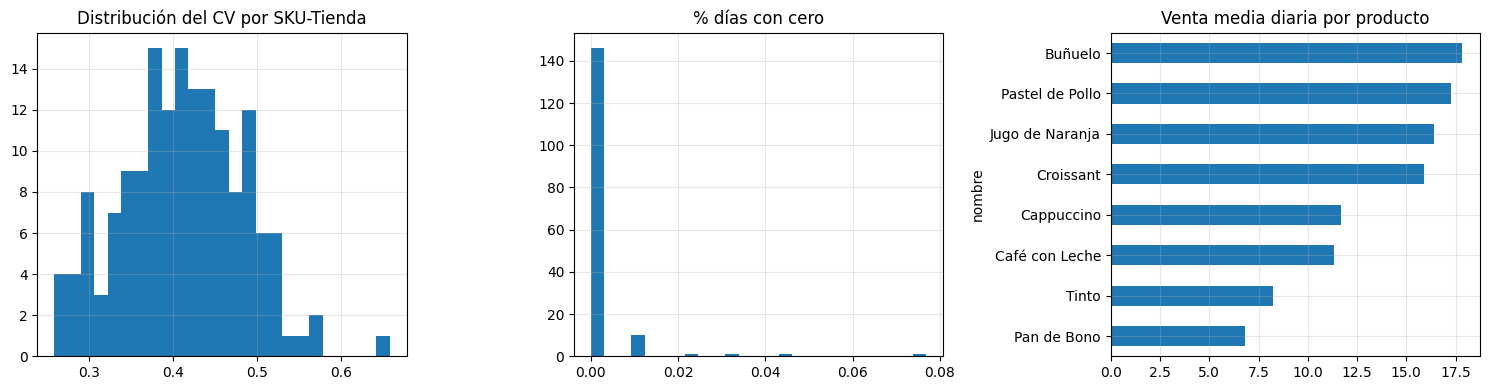

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sku["cv"].hist(bins=25, ax=axes[0]); axes[0].set_title("Distribución del CV por SKU-Tienda")
sku["pct_ceros"].hist(bins=25, ax=axes[1]); axes[1].set_title("% días con cero")
sku.groupby("nombre")["media"].mean().sort_values().plot.barh(ax=axes[2]); axes[2].set_title("Venta media diaria por producto")
plt.tight_layout(); plt.show()

### 🔎 Lectura — Comportamiento de la demanda
- Los 160 SKU-tienda son `Smooth` (ADI ≈1.0, sin intermitencia). No hace falta Croston ni TSB; basta un modelo de regresión por cuantiles.
- El CV diario tiene mediana ≈0.41 (rango 0.26–0.66) y todos los SKU-tienda son `X` o `Y` en la clasificación XYZ, ninguno `Z`: demanda bastante predecible. Gran parte de ese CV es el patrón semanal (amplitud entre días ≈0.6); descontados el día de la semana y la tendencia, el CV residual baja a ≈0.31 (se mide en H6).
- A nivel semana la incertidumbre baja mucho: si los días fueran independientes, el CV semanal sería ≈0.41/√7 ≈0.15. Es una cota superior, porque parte del CV diario es patrón semanal y no ruido; con el CV residual da ≈0.12.
- ABC por margen: 97 SKU-tienda son A (80 % del margen), 40 B y 23 C. El esfuerzo del modelo debe ir a los 97 A.
- Más vendidos por día: Buñuelo (≈17.8), Pastel (≈17.3), Jugo (≈16.4) y Croissant (≈15.9); menos vendidos: Pan de Bono (≈6.8) y Tinto (≈8.2).

> **Sigue:** con esa demanda, ¿cuánto cuesta equivocarse al pedir? (1.5)

## 1.5 El catálogo y la economía del producto
<sup><a href="#Contenido">↑ Contenido</a></sup>
*Pregunta: ¿cuánto cuesta equivocarse en cada dirección?*
### Qué es cada columna del catálogo y para qué sirve
| Columna | Qué es | Para qué sirve en el ejercicio |
|---|---|---|
| `costo_unitario` | Lo que le cuesta a Tostao cada unidad | Margen (precio − costo); también lo que se pierde si el producto sobra y se daña |
| `precio_venta` | Lo que paga el cliente | Margen y valor de la venta perdida |
| `costo_almacenamiento_semanal` | Costo de guardar una unidad una semana | Parte del costo de pasarse (sobrestock) |
| Cu (costo de quedarse corto) | = margen unitario (+ venta cruzada que se pierda) | Lo que duele cuando falta producto |
| Co (costo de pasarse) | = almacenamiento (+ la parte del costo unitario que se pierda si se daña) | Lo que duele cuando sobra producto |
| Ratio crítico | `Cu / (Cu + Co)` | El cuantil de la demanda que hay que cubrir. 0.99 = "pide casi lo máximo"; 0.60 = "pide poco más que el promedio" |

Ejemplo con el Tinto: cuesta 800 y se vende a 2,500, así que Cu = 1,700. Guardarlo una semana cuesta 10, así que Co = 10. Quedarse corto es 170 veces peor que pasarse, y el ratio crítico sale ≈0.99. Si al sobrar se tira (se pierden los 800), Co = 810 y el ratio baja a ≈0.68.

### Cu, Co y ratio crítico por producto
La tabla siguiente calcula, para cada producto, el margen (Cu), el costo de almacenamiento y el ratio crítico, con y sin pérdida del costo unitario cuando el producto sobra.

In [28]:
cat = catalogo.copy()
cat["margen_unit"] = cat["precio_venta"] - cat["costo_unitario"]
cat["margen_pct"] = cat["margen_unit"] / cat["precio_venta"]
cat["Cu"] = cat["margen_unit"]
cat["Co_almacen"] = cat["costo_almacenamiento_semanal"]
cat["ratio_critico_solo_almacen"] = cat["Cu"] / (cat["Cu"] + cat["Co_almacen"])
# Escenario perecedero: lo que sobra se pierde -> Co incluye el costo de adquisición
cat["Co_perecedero"] = cat["Co_almacen"] + cat["costo_unitario"]
cat["ratio_critico_perecedero"] = cat["Cu"] / (cat["Cu"] + cat["Co_perecedero"])
cols = ["id_producto", "nombre", "categoria", "costo_unitario", "precio_venta", "margen_unit", "margen_pct",
        "Co_almacen", "ratio_critico_solo_almacen", "Co_perecedero", "ratio_critico_perecedero"]
display(cat[cols])

,id_producto,nombre,categoria,costo_unitario,precio_venta,margen_unit,margen_pct,Co_almacen,ratio_critico_solo_almacen,Co_perecedero,ratio_critico_perecedero
0,PROD_001,Tinto,Bebidas,800,2500,1700,0.68,10,0.99,810,0.68
1,PROD_002,Café con Leche,Bebidas,1200,3500,2300,0.66,15,0.99,1215,0.65
2,PROD_003,Cappuccino,Bebidas,1500,4500,3000,0.67,15,1.00,1515,0.66
3,PROD_004,Pan de Bono,Alimentos,1000,2800,1800,0.64,20,0.99,1020,0.64
4,PROD_005,Buñuelo,Alimentos,800,2500,1700,0.68,20,0.99,820,0.67
5,PROD_006,Croissant,Alimentos,1200,3500,2300,0.66,25,0.99,1225,0.65
6,PROD_007,Pastel de Pollo,Alimentos,1500,3500,2000,0.57,30,0.99,1530,0.57
7,PROD_008,Jugo de Naranja,Bebidas,2000,5000,3000,0.60,50,0.98,2050,0.59


> **Hallazgo a validar.** El costo de almacenamiento semanal es mínimo (10–50) frente al margen (≈1,700–3,000). Con solo ese costo el ratio crítico es ≈0.99 y el modelo diría "pedir siempre el percentil 99", lo cual no es realista para panadería y bebidas frescas. Hay que declarar un supuesto de merma o de costo de capital (escenario perecedero) y hacer análisis de sensibilidad.

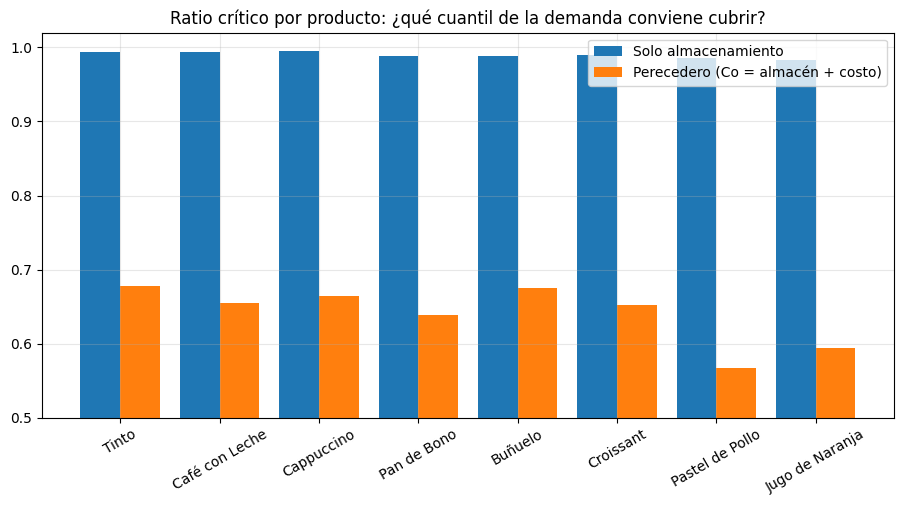

In [29]:
x = np.arange(len(cat)); w = 0.4
fig, ax = plt.subplots()
ax.bar(x - w/2, cat["ratio_critico_solo_almacen"], w, label="Solo almacenamiento")
ax.bar(x + w/2, cat["ratio_critico_perecedero"], w, label="Perecedero (Co = almacén + costo)")
ax.set_xticks(x); ax.set_xticklabels(cat["nombre"], rotation=30)
ax.set_ylim(0.5, 1.02); ax.set_title("Ratio crítico por producto: ¿qué cuantil de la demanda conviene cubrir?"); ax.legend()
plt.show()

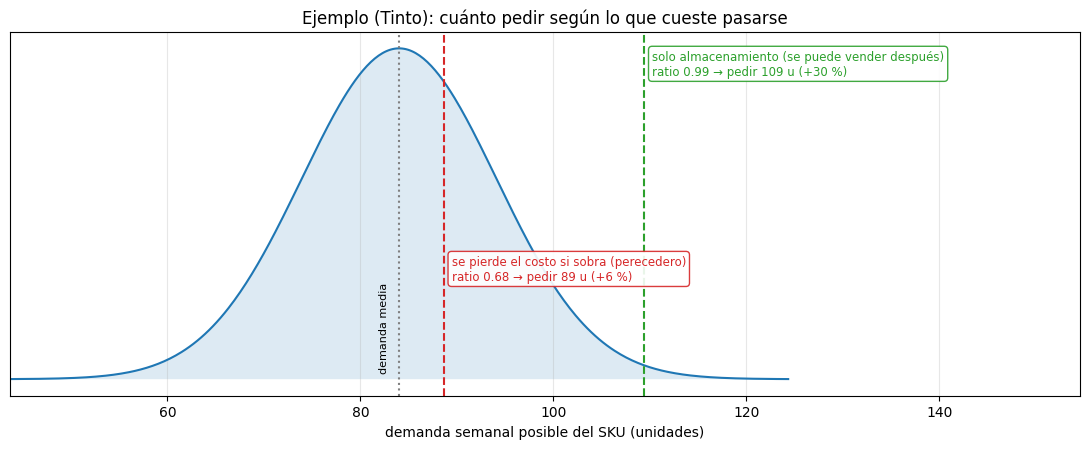

In [35]:
# DIAGRAMA: qué significa el ratio crítico (ejemplo ilustrativo con un SKU de ~12 u/día y CV semanal ≈ 0.12)
from scipy.stats import norm
mu_ej, sd_ej = 84.0, 84.0 * 0.12
x = np.linspace(mu_ej - 4 * sd_ej, mu_ej + 4 * sd_ej, 400)
fila_t = cat[cat["nombre"] == "Tinto"].iloc[0]
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.set_xlim(mu_ej - 4 * sd_ej, mu_ej + 7 * sd_ej); ax.plot(x, norm.pdf(x, mu_ej, sd_ej), color="tab:blue"); ax.fill_between(x, norm.pdf(x, mu_ej, sd_ej), alpha=0.15)
for r, etq, col in [(fila_t["ratio_critico_solo_almacen"], "solo almacenamiento (se puede vender después)", "tab:green"),
                    (fila_t["ratio_critico_perecedero"], "se pierde el costo si sobra (perecedero)", "tab:red")]:
    q = norm.ppf(r, mu_ej, sd_ej)
    ax.axvline(q, color=col, ls="--"); ax.text(q + 0.8, norm.pdf(mu_ej, mu_ej, sd_ej) * (0.92 if col == "tab:green" else 0.30),
                                               f"{etq}\nratio {r:.2f} → pedir {q:.0f} u (+{100 * (q / mu_ej - 1):.0f} %)", color=col, fontsize=8.5,
                                               bbox=dict(boxstyle="round", fc="white", ec=col, alpha=0.9))
ax.axvline(mu_ej, color="gray", ls=":"); ax.text(mu_ej - 1, 0.001, "demanda media", rotation=90, ha="right", fontsize=8)
ax.set_title("Ejemplo (Tinto): cuánto pedir según lo que cueste pasarse"); ax.set_xlabel("demanda semanal posible del SKU (unidades)"); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 🔎 Lectura — El diagrama del ratio crítico
- La campana es la demanda semanal posible de un SKU-tienda de ≈84 unidades, con el CV semanal ≈0.12 que medimos. La línea punteada es la demanda media.
- Si pasarse casi no cuesta (solo almacenamiento, línea verde), conviene cubrir casi todo el rango: pedir ≈109 u (+30 %), el cuantil 99.
- Si lo que sobra se pierde (línea roja), pedir tanto tiene riesgo real y conviene quedarse cerca de la media: ≈89 u (+6 %), el cuantil 68.
- La distancia entre las dos líneas es la decisión del ejercicio. Depende de cuánto se pierde de lo que sobra (α) (ver H10).

### 🔎 Lectura — Economía del producto: el hallazgo más importante del caso
- Con solo el costo de almacenamiento, el ratio crítico es 0.98–1.00 para todos los productos (margen 1,700–3,000 frente a almacenamiento 10–50). Eso equivale a pedir siempre el cuantil 99 de la demanda, una política poco razonable que vuelve trivial al optimizador.
- Si el sobrante se pierde (pan, buñuelo, jugo, pastel…), el costo de sobrestock pasa a ser almacenamiento más costo unitario y el ratio crítico baja a 0.57–0.68 (hay que pedir el cuantil 57–68). Ahí sí hay un trade-off real.
- La realidad está entre los dos extremos y depende de un supuesto que el enunciado no da. Por eso se trata como un parámetro, α = fracción del costo unitario que se pierde si sobra (0, 25, 50 y 100 %).
- Para dimensionar la decisión: con CV semanal ≈0.12, pedir el cuantil 99 en vez del 62 significa ≈+28 % frente a ≈+4 % sobre la demanda media.
- Los productos con menor ratio crítico (Pastel de Pollo 0.57, Jugo 0.59) son los más caros de perder, así que conviene ser más conservador con ellos; Tinto y Buñuelo (0.67–0.68) toleran pedir más.
- Falta un componente: quedarse corto también pierde la venta cruzada (lo que el cliente compra junto). Se estima en H9 y sube Cu, lo que empuja a pedir más de los productos gancho.

**Ejemplo con el Tinto** (SKU-tienda típico de ≈84 u por semana, CV semanal ≈0.12):
- Si sobra una unidad y solo cuesta almacenarla (10), pasarse casi no duele. Quedarse corto pierde el margen (1,700), 170 veces más. Lo racional es pedir bastante de más: cuantil 99, ≈109 u (+30 %).
- Si lo que sobra se tira, pasarse cuesta 810 (800 de la unidad más 10 de almacenar), y quedarse corto sigue costando 1,700, solo 2.1 veces más. Ahora conviene quedarse cerca de la media: cuantil 68, ≈89 u (+6 %).
- Mismo producto y mismos datos de venta: cambia un supuesto (¿se pierde lo que sobra?) y el pedido pasa de 109 a 89 u. En toda la red, pasar de α = 0 a α = 1 mueve el pedido total ≈22 % (≈3,300 u por semana, H13).

**Para qué sirve saberlo.**
- Con el mismo pronóstico, el supuesto de merma mueve el pedido más que cualquier otro parámetro operativo (H13). Por eso es el primer dato que hay que conseguir del negocio: cuánto se bota realmente por producto.
- Sin este análisis el optimizador pediría siempre el cuantil 99 y parecería funcionar, sin reflejar el riesgo de merma.
- Justifica entregar un análisis de sensibilidad en lugar de una sola cifra de pedido.

> **Sigue:** ¿con qué stock se parte? (1.6)

## 1.6 El inventario: una foto sin contexto
<sup><a href="#Contenido">↑ Contenido</a></sup>
*Pregunta: ¿con qué stock se parte y qué nos dice una sola foto?*
- `ventas_historicas` es una película de 91 días consecutivos. `inventario_actual` es una foto: un solo valor de stock por SKU-tienda, sin fecha.
- Supuesto: es el stock al cierre del 31-mar-2024, es decir, el que hay al empezar la semana a pronosticar. El enunciado no lo dice; se declara y conviene confirmarlo.
- Consecuencias:
  1. No hay stock histórico: no se puede reconstruir cuándo hubo quiebres ni evaluar el pedido neto en el backtest. Se evalúa el nivel de cobertura (`Q*`), suponiendo que cada semana empieza sin stock.
  2. Las ventas equivalen a la demanda solo si no hubo quiebres. Se verifica en 2.3 (rachas de ceros en SKU-tienda de venta alta): no hay evidencia de demanda censurada.
  3. El stock no entra al modelo de demanda. Se usa solo al final: `pedido = max(0, Q* − stock)`.
  4. No sabemos si la foto es antes o después de recibir un pedido, ni cuál es el lead time. Por eso lo que se diga del stock es una observación de una foto, no un diagnóstico de la política de reposición.

### Cobertura del inventario
Cobertura (días) = `stock_actual` ÷ venta media diaria. Como se pide para la próxima semana, un SKU-tienda con menos de 7 días de cobertura necesita reposición.

In [36]:
dem = (ventas.groupby(["id_tienda", "id_producto"])["unidades_vendidas"]
       .agg(venta_media_dia="mean", venta_std_dia="std").reset_index())
# venta de las últimas 2 semanas (más cercana al "hoy" del inventario)
ult = ventas[ventas["fecha"] > ventas["fecha"].max() - pd.Timedelta(days=14)]
dem = dem.merge(ult.groupby(["id_tienda", "id_producto"])["unidades_vendidas"].mean().rename("venta_media_dia_14d").reset_index(),
                on=["id_tienda", "id_producto"], how="left")

inv = (inventario.merge(dem, on=["id_tienda", "id_producto"], how="left")
       .merge(catalogo, on="id_producto", how="left")
       .merge(tiendas, on="id_tienda", how="left"))
inv["demanda_semana_esperada"] = inv["venta_media_dia"] * 7
inv["cobertura_dias"] = inv["stock_actual"] / inv["venta_media_dia"].replace(0, np.nan)
inv["riesgo_quiebre"] = inv["stock_actual"] < inv["demanda_semana_esperada"]
inv["sobrestock"] = inv["cobertura_dias"] > 14
inv["costo_almacen_stock"] = inv["stock_actual"] * inv["costo_almacenamiento_semanal"]

print(f"SKU-Tienda con stock < demanda esperada de la semana: {inv['riesgo_quiebre'].mean():.1%}")
print(f"SKU-Tienda con cobertura > 14 días (sobrestock):       {inv['sobrestock'].mean():.1%}")
print(f"Stock en 0: {(inv['stock_actual']==0).sum()}")
display(inv["cobertura_dias"].describe())

SKU-Tienda con stock < demanda esperada de la semana: 96.9%
SKU-Tienda con cobertura > 14 días (sobrestock):       0.6%
Stock en 0: 5


count   160.00
mean      1.98
std       2.17
min       0.00
25%       0.60
50%       1.38
75%       2.47
max      15.54
Name: cobertura_dias, dtype: float64

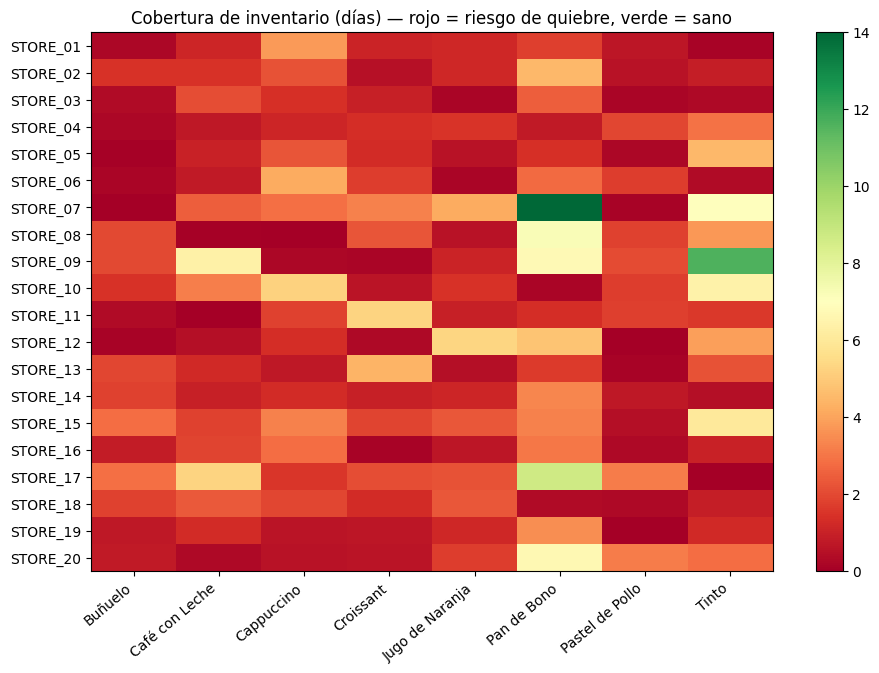

In [37]:
cob = inv.pivot(index="id_tienda", columns="nombre", values="cobertura_dias")
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(cob.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=14); ax.grid(False)
ax.set_xticks(range(cob.shape[1])); ax.set_xticklabels(cob.columns, rotation=40, ha="right")
ax.set_yticks(range(cob.shape[0])); ax.set_yticklabels(cob.index)
ax.set_title("Cobertura de inventario (días) — rojo = riesgo de quiebre, verde = sano"); plt.colorbar(im); plt.show()

### 🔎 Lectura — Cobertura: el stock actual es muy bajo
- El stock cubre en mediana solo 1.4 días de venta (promedio 2.0). El 96.9 % de los SKU-tienda tiene menos stock que la demanda esperada de una semana, y solo 1 SKU-tienda (0.6 %) pasa los 14 días de cobertura.
- Casi toda la demanda de la semana habrá que pedirla: la cantidad a pedir es `Q*` − stock, con un stock pequeño. Por eso el resultado del optimizador depende sobre todo de cuánta demanda se pronostique y de qué cuantil se elija, y poco del inventario actual.
- Los focos rojos (cobertura menor a 1 día) dominan el mapa de calor. Las pocas celdas verdes son `STORE_07 / Pan de Bono` (≈15 días, el único sobrestock claro), `STORE_09 / Tinto` (≈12) y `STORE_17 / Pan de Bono` (≈9): productos de baja rotación en tiendas pequeñas, donde casi no hay que pedir.

### ¿El stock guarda relación con la venta?
Se mide la correlación entre el stock y la venta media diaria de cada SKU-tienda. Hay que leerla con cuidado: si la foto es de cierre y la reposición llega después, una buena política también dejaría poco stock y parecido en todas partes.

Corr(stock, venta media diaria): 0.047


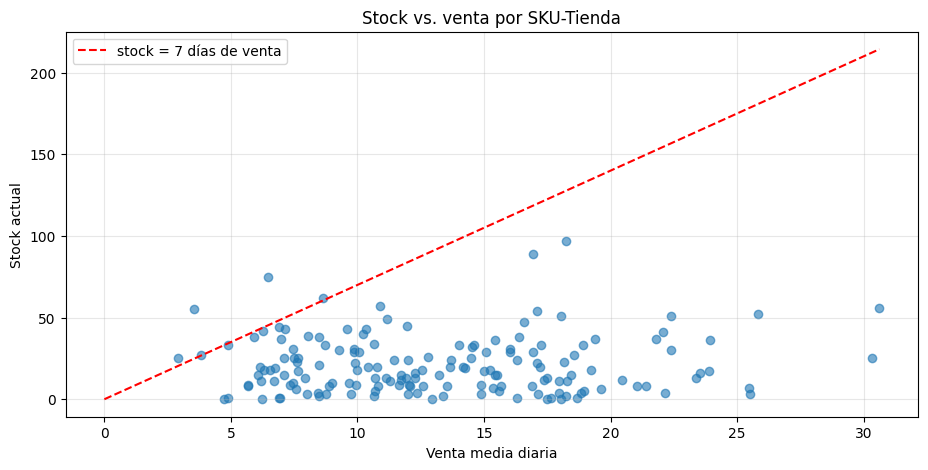

In [38]:
# ¿El stock está alineado con la venta? (correlación a nivel SKU-Tienda)
print("Corr(stock, venta media diaria):", round(inv["stock_actual"].corr(inv["venta_media_dia"]), 3))
fig, ax = plt.subplots()
ax.scatter(inv["venta_media_dia"], inv["stock_actual"], alpha=.6)
ax.plot([0, inv["venta_media_dia"].max()], [0, 7 * inv["venta_media_dia"].max()], "r--", label="stock = 7 días de venta")
ax.set_xlabel("Venta media diaria"); ax.set_ylabel("Stock actual"); ax.legend(); ax.set_title("Stock vs. venta por SKU-Tienda"); plt.show()

### 🔎 Lectura — Correlación baja, pero no concluyente
- La correlación entre el stock y la venta media diaria es 0.047, prácticamente nula. Las tiendas que venden 25–30 u/día tienen casi lo mismo (20–50 u) que otras que venden 5–10, y casi todos los puntos quedan muy por debajo de la línea de 7 días.
- **Esto no prueba que la reposición esté mal alineada.** Si la tienda A vende ≈1,000 buñuelos por semana y la B ≈500, y se les repone en proporción, al cierre pueden quedar 1 y 1: stock bajo, igual y sin correlación con la venta, con una política perfecta. Una política desalineada daría el mismo resultado, y una foto no distingue entre las dos.
- Lo que sí se observa: stock bajo (mediana 1.4 días), muy disperso (de 0 a 15 días), 5 SKU-tienda en cero con ventas de 4.7 a 18 u/día y uno solo con 15 días. Sirve para priorizar el pedido (2.4), no para comparar los resultados del modelo la política actual.

**Qué haría falta.** Historial diario de stock, pedidos recibidos y mermas. Con eso se medirían quiebres, nivel de servicio y merma de la política actual, que es la línea base real para cuantificar una mejora. Mientras tanto, el valor del modelo se mide en el backtest, contra reglas simples.

### Qué más se exploró del stock (detalle en el <a href="#ANEXO-—-Exploración-del-stock-(movida-desde-1.6)">Anexo</a>)
- El stock tampoco responde al costo de almacenar: correlación de Spearman de −0.17 con la cobertura en días (débil) y ≈0 con las unidades.
- Cuadrantes por tienda: riesgo de quiebre en `STORE_03` y `STORE_19` (≈0.8–0.9 días de cobertura); riesgo de sobrestock en `STORE_15`, `STORE_09` y `STORE_10`.

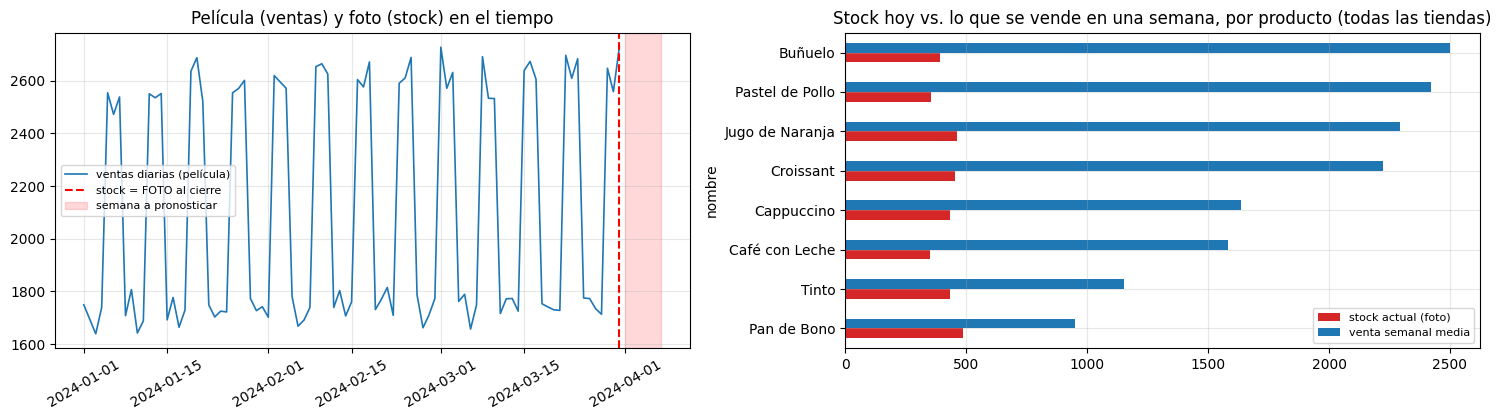

In [39]:
# FOTO vs PELÍCULA en un gráfico
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
d_tot = ventas.groupby("fecha")["unidades_vendidas"].sum()
axes[0].plot(d_tot.index, d_tot.values, color="tab:blue", lw=1.2, label="ventas diarias (película)")
axes[0].axvline(d_tot.index.max(), color="red", ls="--", label="stock = FOTO al cierre")
axes[0].axvspan(d_tot.index.max() + pd.Timedelta(days=1), d_tot.index.max() + pd.Timedelta(days=7), color="red", alpha=0.15, label="semana a pronosticar")
axes[0].set_title("Película (ventas) y foto (stock) en el tiempo"); axes[0].legend(fontsize=8); axes[0].tick_params(axis="x", rotation=30)
st = inventario.merge(catalogo[["id_producto", "nombre"]], on="id_producto").groupby("nombre")["stock_actual"].sum()
dm = ventas.merge(catalogo[["id_producto", "nombre"]], on="id_producto").groupby("nombre")["unidades_vendidas"].sum() / 13
cmp_ = pd.DataFrame({"stock actual (foto)": st, "venta semanal media": dm}).sort_values("venta semanal media")
cmp_.plot.barh(ax=axes[1], color=["tab:red", "tab:blue"]); axes[1].set_title("Stock hoy vs. lo que se vende en una semana, por producto (todas las tiendas)"); axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 🔎 Lectura — Foto vs. película
- Izquierda: la película son 91 días con el patrón semanal de siempre (valles de ≈1,700 de lunes a jueves, cumbres de ≈2,600 de viernes a domingo). El stock es un único punto (línea roja), al cierre y justo antes de la semana a pronosticar (franja roja). No hay forma de saber cómo llegó a ese valor.
- Derecha: el stock de cada producto en toda la red es de ≈350–490 unidades, casi sin importar cuánto se venda. El Buñuelo vende ≈2,500 por semana y tiene ≈390 de stock (≈16 % de la semana); el Pan de Bono vende ≈950 y tiene ≈490 (≈50 %). En los 8 productos el stock cubre menos de una semana de venta; solo el Pan de Bono se acerca a la mitad.
- Casi todo el pedido depende del cuantil elegido y casi nada del stock actual. El producto con más riesgo de sobrestock es el Pan de Bono, que además es el de menor rotación.

> **Sigue:** los supuestos y límites que quedan declarados.

## 1.7 Supuestos y límites de los datos
<sup><a href="#Contenido">↑ Contenido</a></sup>
*Pregunta: ¿qué no sabemos y cómo lo tratamos?*
| # | Supuesto / límite | Por qué importa |
|---|---|---|
| 1 | El stock es el de cierre del 31-mar-2024 (inicio de la semana a pronosticar) | Define cuánto se pide: `Q* − stock` |
| 2 | Ventas ≈ demanda (sin quiebres evidentes) | Si hubiera quiebres, la demanda real sería mayor (2.3 no los encuentra) |
| 3 | Solo 13 semanas de historia | No hay estacionalidad mensual ni anual; el backtest tiene ≈8 pliegues |
| 4 | Precio constante por producto | No se puede medir elasticidad al precio |
| 5 | Lead time, mínimo de pedido, capacidad y stock en tránsito no vienen en los datos | No se asumen en cero: se parametrizan con un valor base y un rango, y se mide su efecto (tabla de parámetros abajo y H13) |
| 6 | Costo de almacenamiento no incluye merma | El supuesto de pérdida por vencimiento (α) es la palanca principal (1.5 y H10) |
| 7 | Los códigos de producto no coinciden entre carpetas | Se cruzan por nombre (1.1); el Croissant es un análogo |
| 8 | Las tablas de B y C no cubren las 20 tiendas del Caso A (exógenas, promos y transacciones: 10) | Cualquier variable de allí solo existiría para la mitad de los SKU |
| 9 | `ground_truth_trends` es la clave de respuestas del dato sintético | No se usa como variable (fuga), solo para validar |

### Parametrización del problema: lo que no viene en los datos no se asume en cero, se parametriza
Un dato que no está en la tabla no desaparece del problema real. Para cada uno se declara un valor base (supuesto explícito), un rango a probar y el dato que se pediría al negocio. H13 mide cuánto cambia el pedido al mover cada uno, para saber cuáles conseguir primero.

| Parámetro | Qué es | Valor base (supuesto) | Rango a probar | Qué dato pedir / quién lo sabe |
|---|---|---|---|---|
| Lead time (L) | Días entre hacer el pedido y recibirlo | 1 día | 0, 1, 2, 3, 7 | Contrato y registro de entregas del proveedor |
| Período de revisión (R) | Cuántos días cubre cada pedido (cada cuánto se pide) | 7 días (el enunciado pide pronóstico semanal) | 3 a 7 | Política de compras |
| Stock en tránsito | Pedidos ya hechos que aún no llegan | 0 | 0 a 2 días de venta | Tabla de órdenes abiertas |
| MOQ y múltiplo de empaque | Mínimo y múltiplo en que vende el proveedor | 1 (sin restricción) | 6, 12, 24 | Ficha del proveedor |
| Capacidad de la tienda | Máximo de unidades que caben (vitrina, nevera, bodega) | Sin límite | 90 % y 70 % del pedido sin límite | Operaciones de tienda |
| Vida útil y α | Fracción del costo que se pierde si sobra | Por producto (H10) | 0 a 1 | Merma real registrada |
| Venta cruzada perdida (β) | Fracción de la canasta que se pierde si falta el producto | 25 % (H9) | 0 a 100 % | Tickets de días con quiebre |
| Piso y techo del nivel de servicio (τ) | Límites de la disponibilidad que se acepta | entre 0.50 y 0.99 | — | Política comercial (p. ej. productos gancho) |
| Venta perdida o pedido pendiente | Si el cliente que no encuentra producto se va o espera | Se va (venta perdida) | — | Observación en tienda |
| Costo fijo por pedido o transporte | Costo de hacer un pedido, sin importar el tamaño | 0 (no se modela) | — | Logística. Si existe, el problema deja de ser Newsvendor y pasa a (s, Q) |
| Distribución y variabilidad de la demanda | Forma del ruido y su tamaño | Normal, CV diario 0.31 (medido en el EDA) | Poisson / binomial negativa | Ya medido |
| Stock vendible vs. total | Parte del stock que realmente se puede vender (sin merma, reservado o bloqueado) | Todo el stock es vendible | — | Sistema de inventario |
| Demanda censurada | Ventas que no se registraron por estar sin stock | Sin evidencia (2.3) | — | Registro de disponibilidad por hora |

Todos estos valores viven en una sola clase de parámetros (`ParametrosPedido`, definida en H13): cambiar un supuesto es cambiar un número, no la lógica.

**¿Quién abastece?** El caso base supone un proveedor externo. Si el proveedor fuera la propia Tostao (producción central), el enfoque sería el mismo pero cambiarían los valores: el costo unitario sería costo de producción, el lead time sería producción más distribución, el MOQ sería el tamaño de lote, la capacidad sería la de la planta (compartida entre las 20 tiendas) y la merma sería un dato interno medible. Además, producir para todas las tiendas a la vez permite cubrir el total con menos colchón que la suma por tienda (H5 muestra que no hay choques comunes).

---
# PARTE 2 — Anomalías
<sup><a href="#Contenido">↑ Contenido</a></sup>
¿Qué hay de raro en los datos y qué se hace con eso? Cada sección termina con una decisión.

## 2.1 Ceros
<sup><a href="#Contenido">↑ Contenido</a></sup>

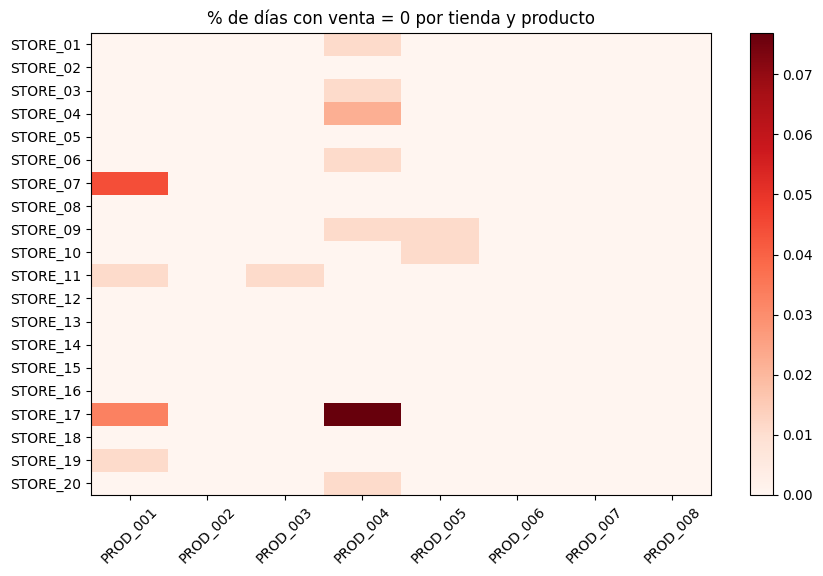

In [40]:
# Ceros por SKU-Tienda: ¿están concentrados en algunos SKUs (producto de baja rotación / quiebres)?
ceros = (ventas.assign(es_cero=ventas["unidades_vendidas"].eq(0))
         .groupby(["id_tienda", "id_producto"])["es_cero"].mean().unstack())
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(ceros.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(ceros.shape[1])); ax.set_xticklabels(ceros.columns, rotation=45)
ax.set_yticks(range(ceros.shape[0])); ax.set_yticklabels(ceros.index)
ax.set_title("% de días con venta = 0 por tienda y producto"); ax.grid(False)
plt.colorbar(im); plt.show()

## 2.2 Outliers
<sup><a href="#Contenido">↑ Contenido</a></sup>

### Outliers (z-score robusto con mediana/MAD por SKU-Tienda)

In [41]:
g = ventas.groupby(["id_tienda", "id_producto"])["unidades_vendidas"]
ventas["mediana"] = g.transform("median")
ventas["mad"] = g.transform(lambda s: (s - s.median()).abs().median())
ventas["z_rob"] = 0.6745 * (ventas["unidades_vendidas"] - ventas["mediana"]) / ventas["mad"].replace(0, np.nan)

outliers = ventas[ventas["z_rob"].abs() > 3.5]
print(f"Outliers (|z|>3.5): {len(outliers):,} ({len(outliers)/len(ventas):.2%})")
print("Altos:", (outliers["z_rob"] > 0).sum(), "| Bajos:", (outliers["z_rob"] < 0).sum())
display(outliers.sort_values("z_rob", key=abs, ascending=False).head(10))

Outliers (|z|>3.5): 57 (0.39%)
Altos: 56 | Bajos: 1


,fecha,id_tienda,id_producto,unidades_vendidas,mediana,mad,z_rob
4687,2024-02-16,STORE_07,PROD_004,13,3.00,1.00,6.75
6123,2024-01-27,STORE_09,PROD_004,14,4.00,1.00,6.75
396,2024-02-02,STORE_01,PROD_005,29,12.00,2.00,5.73
370,2024-01-07,STORE_01,PROD_005,28,12.00,2.00,5.40
6115,2024-01-19,STORE_09,PROD_004,11,4.00,1.00,4.72
4430,2024-03-03,STORE_07,PROD_001,11,4.00,1.00,4.72
6131,2024-02-04,STORE_09,PROD_004,11,4.00,1.00,4.72
13999,2024-03-17,STORE_20,PROD_002,23,9.00,2.00,4.72
11093,2024-03-23,STORE_16,PROD_002,40,19.00,3.00,4.72
13971,2024-02-18,STORE_20,PROD_002,23,9.00,2.00,4.72


### 🔎 Lectura — Outliers
- Solo 57 puntos (0.39 %) superan |z robusto| > 3.5, y 56 de los 57 son picos hacia arriba: la demanda tiene cola derecha, con días de venta muy superiores a lo normal y casi nunca muy inferiores.
- Varios casos están en SKU-tienda de baja rotación, donde la MAD es 1 y un día de 13 unidades contra una mediana de 3 ya cuenta como outlier. Parte de esto es sobredispersión y no error.
- `STORE_20` concentra 9 de los 57 picos (16 %), bastante más que cualquier otra tienda. Se cruzó con `promociones_activas` en H8.

**Decisión:** no eliminarlos. La cola derecha es justo lo que el pedido necesita cubrir; se mantienen y el modelo de cuantiles los absorbe.

> Los picos se mantienen: nada indica que sean errores (no coinciden con promociones, H8) y el modelo de cuantiles los cubre.

## 2.3 Demanda censurada y picos
<sup><a href="#Contenido">↑ Contenido</a></sup>

### ¿Ceros por quiebre de stock? ¿Picos concentrados?
Un cero de ventas puede ser falta de demanda o falta de stock. Si un SKU-tienda normalmente vende y de pronto tiene días en cero, probablemente fue un quiebre, y la venta observada subestima la demanda real.

In [42]:
def rachas_cero(s: pd.Series) -> int:
    z = (s.values == 0).astype(int); mx = cur = 0
    for v in z:
        cur = cur + 1 if v else 0; mx = max(mx, cur)
    return mx

ventas_o = ventas.sort_values(["id_tienda", "id_producto", "fecha"])
racha = ventas_o.groupby(["id_tienda", "id_producto"])["unidades_vendidas"].apply(rachas_cero).rename("racha_max_ceros").reset_index()
sospechosos = racha.merge(sku[["id_tienda", "id_producto", "media", "nombre"]], on=["id_tienda", "id_producto"])
sospechosos = sospechosos[(sospechosos["media"] >= 5) & (sospechosos["racha_max_ceros"] >= 2)].sort_values("racha_max_ceros", ascending=False)
print(f"SKU-Tienda con media >= 5 u/día y racha de >=2 ceros seguidos (posible quiebre): {len(sospechosos)}")
display(sospechosos.head(10))

SKU-Tienda con media >= 5 u/día y racha de >=2 ceros seguidos (posible quiebre): 0


,id_tienda,id_producto,racha_max_ceros,media,nombre


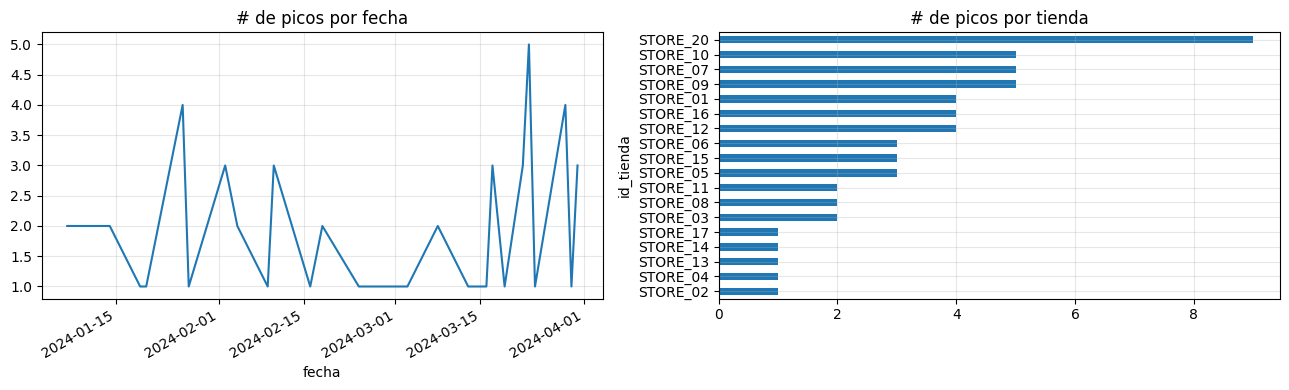

In [43]:
# Picos: días con z robusto muy alto, ¿se concentran en fechas o tiendas concretas?
picos = outliers[outliers["z_rob"] > 3.5]
if len(picos):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    picos.groupby("fecha").size().plot(ax=axes[0], title="# de picos por fecha")
    picos.groupby("id_tienda").size().sort_values().plot.barh(ax=axes[1], title="# de picos por tienda")
    plt.tight_layout(); plt.show()
else:
    print("No se detectaron picos con |z|>3.5")

### 🔎 Lectura — Demanda censurada y picos
- Ningún SKU-tienda con venta media de 5 u/día o más tiene 2 o más ceros seguidos: no hay evidencia de quiebres que contaminen la demanda (demanda censurada). Se pueden modelar las ventas como si fueran la demanda real, lo que simplifica el modelo.
- Los picos no se concentran en una fecha (1–5 por día, sin un día dominante, con algo más de actividad a fines de marzo). Por tienda destaca `STORE_20` con 9. Si fueran promociones se verían en bloques de fechas por producto; eso se revisó en H8.

## 2.4 Anomalías de inventario
<sup><a href="#Contenido">↑ Contenido</a></sup>

In [44]:
# Anomalías de la foto de inventario: stock en cero y sobrestock
cols_inv = [c for c in ["id_tienda", "nombre", "stock_actual", "venta_media_dia", "cobertura_dias", "costo_almacen_stock"] if c in inv.columns]
print("SKU-tienda con stock en 0 (quiebre inmediato):"); display(inv.loc[inv["stock_actual"] == 0, cols_inv])
print("SKU-tienda con más de 14 días de cobertura (sobrestock):"); display(inv.loc[inv["cobertura_dias"] > 14, cols_inv])
print("Los 10 SKU-tienda con menor cobertura (más urgentes de reponer):"); display(inv.nsmallest(10, "cobertura_dias")[cols_inv])

SKU-tienda con stock en 0 (quiebre inmediato):


,id_tienda,nombre,stock_actual,venta_media_dia,cobertura_dias,costo_almacen_stock
52,STORE_07,Buñuelo,0,6.23,0.00,0
58,STORE_08,Cappuccino,0,17.48,0.00,0
81,STORE_11,Café con Leche,0,12.93,0.00,0
128,STORE_17,Tinto,0,4.71,0.00,0
150,STORE_19,Pastel de Pollo,0,18.04,0.00,0


SKU-tienda con más de 14 días de cobertura (sobrestock):


,id_tienda,nombre,stock_actual,venta_media_dia,cobertura_dias,costo_almacen_stock
51,STORE_07,Pan de Bono,55,3.54,15.54,1100


Los 10 SKU-tienda con menor cobertura (más urgentes de reponer):


,id_tienda,nombre,stock_actual,venta_media_dia,cobertura_dias,costo_almacen_stock
52,STORE_07,Buñuelo,0,6.23,0.00,0
58,STORE_08,Cappuccino,0,17.48,0.00,0
81,STORE_11,Café con Leche,0,12.93,0.00,0
128,STORE_17,Tinto,0,4.71,0.00,0
150,STORE_19,Pastel de Pollo,0,18.04,0.00,0
94,STORE_12,Pastel de Pollo,1,18.67,0.05,30
36,STORE_05,Buñuelo,1,17.65,0.06,20
57,STORE_08,Café con Leche,1,16.30,0.06,15
92,STORE_12,Buñuelo,2,18.23,0.11,40
125,STORE_16,Croissant,3,25.51,0.12,75


**Lectura (con los resultados):**
- **5 SKU-tienda abren la semana sin stock**: `STORE_07 / Buñuelo`, `STORE_08 / Cappuccino`, `STORE_11 / Café con Leche`, `STORE_17 / Tinto` y `STORE_19 / Pastel de Pollo`, con ventas de 4.7 a 18 u/día: quiebres inmediatos.
- **El único sobrestock** es `STORE_07 / Pan de Bono`: 55 u con ≈3.5 u/día (15.5 días de cobertura). No hay que pedir.
- **Los 10 más urgentes** tienen 0 a 3 unidades frente a 6–25 u/día (cobertura ≤ 0.12 días); `STORE_08` aparece dos veces (Cappuccino y Café con Leche).
- **Límite:** la foto no distingue un quiebre real de un pedido por llegar (ver H13, stock en tránsito).

## 2.5 Inconsistencias entre tablas
<sup><a href="#Contenido">↑ Contenido</a></sup>

Qué no cuadra entre tablas, y su explicación. El primer chequeo compara el precio de cada código de producto en los tickets con el catálogo del Caso A: solo coinciden `PROD_001` a `PROD_003`. La explicación es que la numeración de productos es distinta entre carpetas, y se resuelve cruzando por nombre (ver 1.1).

In [45]:
chk = (det.groupby("id_producto")["precio_unitario"].agg(["median", "nunique", "count"])
          .reset_index().merge(catalogo[["id_producto", "nombre", "precio_venta"]], on="id_producto"))
chk["coincide"] = chk["median"] == chk["precio_venta"]
display(chk)

,id_producto,median,nunique,count,nombre,precio_venta,coincide
0,PROD_001,"2,500.00",1,1419,Tinto,2500,True
1,PROD_002,"3,500.00",1,938,Café con Leche,3500,True
2,PROD_003,"4,500.00",1,1247,Cappuccino,4500,True
3,PROD_004,"4,800.00",1,301,Pan de Bono,2800,False
4,PROD_005,"4,000.00",1,168,Buñuelo,2500,False
5,PROD_006,"2,500.00",1,789,Croissant,3500,False
6,PROD_007,"4,500.00",1,167,Pastel de Pollo,3500,False
7,PROD_008,"3,200.00",1,356,Jugo de Naranja,5000,False


### Horas pico y ticket promedio (transacciones_resumen): ¿es consistente con las ventas?

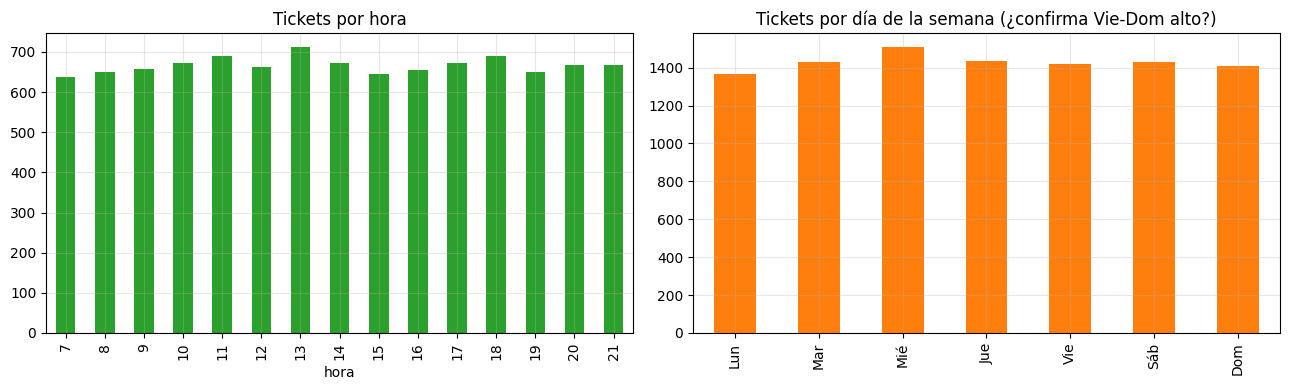

Ticket promedio por tienda:


,tickets,ticket_prom
id_tienda,,
STORE_06,998,21.19
STORE_07,1005,21.16
STORE_05,1026,20.77
STORE_02,991,17.71
STORE_03,976,17.69
STORE_10,1006,17.51
STORE_09,960,17.50
STORE_08,998,17.33
STORE_01,1014,14.30


In [46]:
if trx is None:
    print("Sin transacciones_resumen.")
else:
    trx = trx.assign(hora=trx["timestamp"].dt.hour, dow=trx["timestamp"].dt.dayofweek)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    trx.groupby("hora").size().plot.bar(ax=axes[0], color="tab:green"); axes[0].set_title("Tickets por hora")
    d = trx.groupby("dow").size(); d.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"][: len(d)]
    d.plot.bar(ax=axes[1], color="tab:orange"); axes[1].set_title("Tickets por día de la semana (¿confirma Vie-Dom alto?)")
    plt.tight_layout(); plt.show()
    tp = trx.groupby("id_tienda").agg(tickets=("id_ticket", "count"), ticket_prom=("total_venta", "mean")).round(2)
    print("Ticket promedio por tienda:"); display(tp.sort_values("ticket_prom", ascending=False).head(10))

### 🔎 Lectura — Horas pico y días: esta tabla no es consistente con las ventas
- No hay hora pico: de 7 a 21 h hay entre ≈640 y ≈710 tickets por hora, casi plano.
- Tampoco hay patrón semanal: los tickets por día van de ≈1,370 a ≈1,510, con el miércoles más alto y sin salto de viernes a domingo. En `ventas_historicas` esos días venden ≈50 % más. La tabla no lo confirma; lo contradice.
- La escala es distinta: el ticket promedio por tienda es de 14–21, mientras que los productos cuestan 2,500–5,000. Las magnitudes no cuadran con el catálogo.

**Conclusión:** `transacciones_resumen` parece generada de forma independiente (distribución uniforme en horas y días). No se usa para explicar la demanda del Caso A; si se menciona, es como contexto y con esta salvedad.

Resumen de inconsistencias
| Inconsistencia | Evidencia | Qué hacemos |
|---|---|---|
| Códigos de producto distintos entre carpetas | solo 3 de 8 precios coinciden en tickets | Cruzar por nombre y validar con precio (1.1) |
| `transacciones_resumen` no replica el patrón semanal | tickets por día planos; sin hora pico | No usarla para explicar la demanda |
| Transacciones_resumen trae importes en una escala que no cuadra con los precios del catálogo; no se usa para calcular ingresos ni para explicar la demanda. | ticket promedio 14–21 vs. precios de 2,500–5,000 | No mezclar importes con ventas |
| 55–60 % de los tickets son de clientes sin registro de lealtad | `clientes_loyalty` tiene 1,000 clientes y los tickets traen 2,455 clientes distintos | Mix de segmentos poco confiable (H11) |
| `tickets` cubre todo 2024 y otras tiendas (`TOSTAO_nn`) | solo ≈25 % en ene–mar | Solo contexto |
| Exógenas, promos y transacciones cubren 10 de 20 tiendas | chequeo de llaves (1.1) | Cualquier variable de allí cubriría la mitad de los SKU |

---
# PARTE 3 — Generación de hipótesis: ¿qué sirve para pronosticar y para decidir el pedido?
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Enfoque de pronóstico.** Un solo modelo global de cuantiles para los 160 SKU-tienda, con rezagos, medias móviles y día de la semana, validado con backtest de origen móvil. Los modelos clásicos por serie (ETS, ARIMA estacional) entran solo como comparación: con 91 puntos por serie rinden menos que aprender entre series.

**Festivos.** El historial tiene 5 festivos (1-ene, 8-ene, 25-mar, 28-mar, 29-mar) y la semana a pronosticar (1–7 abr) no tiene ninguno; su utilidad sería limpiar el historial, no predecir esa semana. La ventana de pago (días 15–16 y 30–1) sí podría importar, porque el 1-abr cae justo después de fin de mes.

**Cómo está organizada la parte.** Cada hipótesis sigue el mismo orden: pregunta, cómo se prueba, qué vimos y qué decidimos. Al final, una ablación con backtest (H12) compara los conjuntos de variables con un mismo modelo. Los términos técnicos están definidos en el glosario del final.

### Regla para las variables externas
Las tablas de los casos B y C pueden explicar la demanda del Caso A solo si comparten llaves; cada bloque avisa si el cruce no existe. Además, una variable entra al pronóstico solo si se conoce antes de la semana a pronosticar: una promoción planeada sirve; el clima observado de esa misma semana no, porque habría que pronosticarlo.

### Veredicto de variables
Resumen de las hipótesis: qué variable entra al modelo y cuál no.

| Variable | Hipótesis | Resultado | ¿Entra al modelo? |
|---|---|---|---|
| Día de la semana | H3 y 1.4 | Vie–Dom ≈ +50 % en todos los productos y tiendas; explica R² = 0.25 | ✅ **Sí** |
| Producto y tienda | H3, H12 | Perfil común, pero el nivel difiere (escala m²) | ✅ **Sí** |
| Tamaño de tienda (m²) | 1.4, H3 | r = 0.97 con ingreso; día × tamaño aporta +1 pt de R² | ⚠️ Marginal (útil para normalizar o comparar tiendas) |
| Ciudad | H3 | día × ciudad no aporta (p = 0.23); Cali tiene 1 tienda | ❌ No |
| Rezagos (7/14/21/28) y media 4 semanas del mismo día | H4, H12 | WAPE 0.27 vs 0.34 del naive | ✅ **Sí** |
| Medias móviles 7 y 28 días | H4, H12 | mejora ≈0.01 de WAPE | ✅ Sí (aporta poco) |
| Tendencia por SKU / `trend_type` | H6 | la etiqueta no predice dirección; 39 % de SKU tienen tendencia propia | ❌ `trend_type` no · ✅ el nivel reciente la captura |
| Festivos, Semana Santa, puentes | H1 | 2 de 13 días fuera de ±2σ y en sentidos opuestos; la ablación no mejora | ❌ No |
| Ventana de pago (quincena) | H2 | p = 0.37 | ❌ No |
| Clima | H7 | ±2 %, dentro del ruido | ❌ No |
| Tráfico y precio de la competencia | H7 | ρ ≈ 0 | ❌ No |
| Promociones | H8 | con el cruce por nombre (91 promos, 799 días): 2x1 1.01, porcentaje 1.01, monto fijo 0.94; 4 % de los picos en promo vs 5.5 % base; ninguna promo conocida para la semana a pronosticar | ❌ No |
| Venta cruzada (β) | H9 | margen cruzado general ≈2,834 por unidad (1,961 Tinto a 3,749 Croissant); parejas marcadas Pan de Bono→Tinto 0.74, Croissant→Cappuccino 0.69, Pastel↔Jugo; bebidas calientes y frías son sustitutas (lift 0.50); no co-mueve en las ventas | ✅ Entra a Cu como supuesto (β) |
| Perecedero (α) | H10 | supuesto por vida útil; es la palanca principal del pedido | ✅ Entra a Co como supuesto |
| Lealtad / clientes por tienda | H11 | sin diferencias entre tiendas | ❌ No |
| Horas pico / transacciones | 2.5 | inconsistentes con las ventas | ❌ No |
| Stock actual | 1.6 | foto; ρ = 0.05 con la venta, no concluyente; no explica la demanda | ✅ Solo en el paso final del pedido |
| Parámetros operativos (lead time, MOQ, capacidad, en tránsito) | 1.7 y H13 | tránsito 14 % por día, lead time 12 % por día (y ventas perdidas inevitables 2.5 % con L=1), empaque ≈6 %; el orden se mantiene en 9 casos base | ✅ Entran como parámetros del optimizador (no del pronóstico) |

## Bloque A — Calendario, patrón semanal, memoria y tendencias (H1 a H6)
<sup><a href="#Contenido">↑ Contenido</a></sup>

## H1 · El calendario (festivos, Semana Santa, puentes) mueve las ventas
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** ¿Los festivos, los puentes y la Semana Santa alteran las ventas respecto de lo normal para su día de la semana?

**Cómo se prueba.** Para cada SKU-tienda y día de la semana se calcula la venta esperada usando solo días normales. Se suman las esperadas de todo Tostao y se divide la venta real del día entre ese total: es la venta relativa del día (1.00 = día normal). En los días normales promedia 1.000 con una desviación de 0.023. Un día de evento se marca como atípico si se aleja más de 2 desviaciones (±4.6 %). El umbral de 2σ es una convención: deja fuera por azar cerca del 5 % de los días normales. No es una prueba formal, sino un filtro para ver si algún evento sobresale.

#### Calendario colombiano

In [47]:
# Calendario del periodo + semana a pronosticar. Festivos de Colombia en el periodo (ley Emiliani incluida).
FESTIVOS = pd.to_datetime(["2024-01-01", "2024-01-08", "2024-03-25", "2024-03-28", "2024-03-29"])
SEM_SANTA = pd.date_range("2024-03-24", "2024-03-31")        # Domingo de Ramos -> Domingo de Pascua
PUENTES = pd.to_datetime(["2024-01-06", "2024-01-07", "2024-03-23"])   # fin de semana previo a lunes festivo (sin Semana Santa)

def calendario(fechas) -> pd.DataFrame:
    c = pd.DataFrame({"fecha": pd.to_datetime(fechas)})
    c["dow"] = c["fecha"].dt.dayofweek
    c["dia_mes"] = c["fecha"].dt.day
    c["festivo"] = c["fecha"].isin(FESTIVOS).astype(int)
    c["semana_santa"] = c["fecha"].isin(SEM_SANTA).astype(int)
    c["puente"] = c["fecha"].isin(PUENTES).astype(int)
    c["ventana_pago"] = c["dia_mes"].isin([1, 15, 16, 30, 31]).astype(int)    # quincena / fin de mes y día siguiente
    return c

cal = calendario(pd.date_range(ventas["fecha"].min(), ventas["fecha"].max() + pd.Timedelta(days=14)))
print("Semana a pronosticar (1-7 abr):")
display(cal[cal["fecha"] >= ventas["fecha"].max() + pd.Timedelta(days=1)].head(7).assign(dia=lambda d: d["fecha"].dt.day_name()).set_index("fecha"))

Semana a pronosticar (1-7 abr):


,dow,dia_mes,festivo,semana_santa,puente,ventana_pago,dia
fecha,,,,,,,
2024-04-01,0,1,0,0,0,1,Monday
2024-04-02,1,2,0,0,0,0,Tuesday
2024-04-03,2,3,0,0,0,0,Wednesday
2024-04-04,3,4,0,0,0,0,Thursday
2024-04-05,4,5,0,0,0,0,Friday
2024-04-06,5,6,0,0,0,0,Saturday
2024-04-07,6,7,0,0,0,0,Sunday


#### Prueba: ¿los festivos y la Semana Santa mueven las ventas?

Días normales: ratio medio 1.000, desviación 0.023  (1.00 = igual al patrón de su día de la semana)


,dia,tipo,unidades,esperado,ratio,z
fecha,,,,,,
2024-01-01,Mon,festivo,1749,"1,748.20",1.00,0.02
2024-01-06,Sat,puente,2472,"2,601.40",0.95,-2.21
2024-01-07,Sun,puente,2538,"2,599.50",0.98,-1.05
2024-01-08,Mon,festivo,1708,"1,748.20",0.98,-1.02
2024-03-23,Sat,puente,2609,"2,601.40",1.00,0.13
2024-03-24,Sun,Semana Santa,2683,"2,599.50",1.03,1.43
2024-03-25,Mon,festivo + Semana Santa,1775,"1,748.20",1.01,0.68
2024-03-26,Tue,Semana Santa,1773,"1,742.75",1.02,0.77
2024-03-27,Wed,Semana Santa,1735,"1,707.92",1.02,0.70


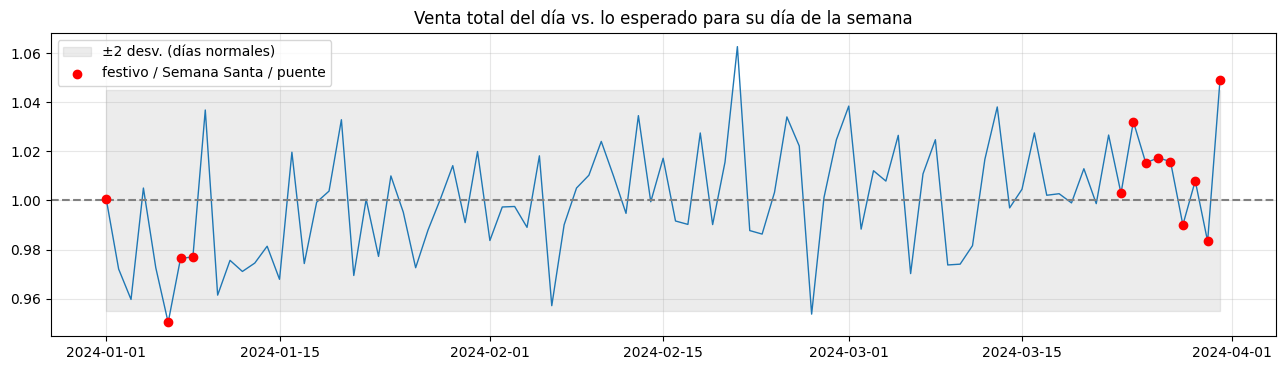

In [48]:
vv = ventas[["fecha", "id_tienda", "id_producto", "unidades_vendidas"]].merge(cal, on="fecha")
evento = (vv["festivo"] == 1) | (vv["semana_santa"] == 1) | (vv["puente"] == 1)
# Venta esperada por SKU-tienda y día de la semana, calculada SOLO con días normales
esperado = vv[~evento].groupby(["id_tienda", "id_producto", "dow"])["unidades_vendidas"].mean().rename("esperado")
vv = vv.join(esperado, on=["id_tienda", "id_producto", "dow"])
dia = (vv.groupby("fecha").agg(unidades=("unidades_vendidas", "sum"), esperado=("esperado", "sum")).reset_index()
         .merge(cal, on="fecha"))
dia["ratio"] = dia["unidades"] / dia["esperado"]
normal = dia[(dia[["festivo", "semana_santa", "puente"]].sum(axis=1) == 0)]
mu, sd = normal["ratio"].mean(), normal["ratio"].std()
print(f"Días normales: ratio medio {mu:.3f}, desviación {sd:.3f}  (1.00 = igual al patrón de su día de la semana)")

ev = dia[(dia[["festivo", "semana_santa", "puente"]].sum(axis=1) > 0)].copy()
ev["dia"] = ev["fecha"].dt.day_name().str[:3]
ev["tipo"] = np.select([(ev["festivo"] == 1) & (ev["semana_santa"] == 1), ev["festivo"] == 1, ev["semana_santa"] == 1],
                       ["festivo + Semana Santa", "festivo", "Semana Santa"], "puente")
ev["z"] = (ev["ratio"] - mu) / sd
display(ev[["fecha", "dia", "tipo", "unidades", "esperado", "ratio", "z"]].round(3).set_index("fecha"))

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(dia["fecha"], dia["ratio"], color="tab:blue", lw=1)
ax.axhline(1, color="gray", ls="--")
ax.fill_between(dia["fecha"], mu - 2 * sd, mu + 2 * sd, color="gray", alpha=0.15, label="±2 desv. (días normales)")
ax.scatter(ev["fecha"], ev["ratio"], color="red", zorder=3, label="festivo / Semana Santa / puente")
ax.set_title("Venta total del día vs. lo esperado para su día de la semana"); ax.legend(); plt.tight_layout(); plt.show()

### 🔎 Lectura — Calendario: sin efecto consistente
- De los 13 días de evento, solo 2 quedan fuera de la banda: el sábado 6-ene (puente, −5 %, z = −2.2) y el domingo 31-mar (Domingo de Pascua, +5 %, z = +2.2). Por azar se esperarían ≈0.6 días fuera; 2, en sentidos opuestos, no alcanzan para concluir.
- Los lunes festivos (1-ene, 8-ene, 25-mar) y los días santos quedan entre 0.98 y 1.01. La Semana Santa completa (24–31 mar) se mueve entre 0.99 y 1.03, salvo el último domingo.
- Un efecto de 2–5 % sobre el total de Tostao es pequeño frente al ruido diario de un SKU-tienda (CV residual ≈ 0.31); a ese nivel no se distingue.
- La Semana Santa, que es la semana más reciente, no distorsiona el nivel que alimenta los rezagos de la semana a pronosticar, y esa semana no tiene festivos.

**Decisión:** el calendario no entra al modelo. Salvedad: con solo 5 festivos, la prueba detecta poco.

## H2 · La quincena y el fin de mes (ventana de pago) mueven las ventas
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** ¿Se vende más alrededor de los días de pago (15–16 y 30–1)?

**Cómo se prueba.** Con la venta relativa del día (ver H1) en días normales, se comparan los días de la ventana de pago (10 días) contra el resto (68) con una prueba t de Welch, que compara dos promedios sin suponer varianzas iguales. Con p < 0.05 se tomaría como evidencia de diferencia. El gráfico muestra, para cada día del mes, cuánto se aleja su venta relativa promedio de 1.00 (eje vertical); las barras rojas son los días de pago.

#### Prueba: quincena y fin de mes (ventana de pago)

Ventana de pago (días 1, 15, 16, 30, 31): ratio 1.006 (n=10) vs resto 0.999 (n=68) | t=0.94, p=0.367


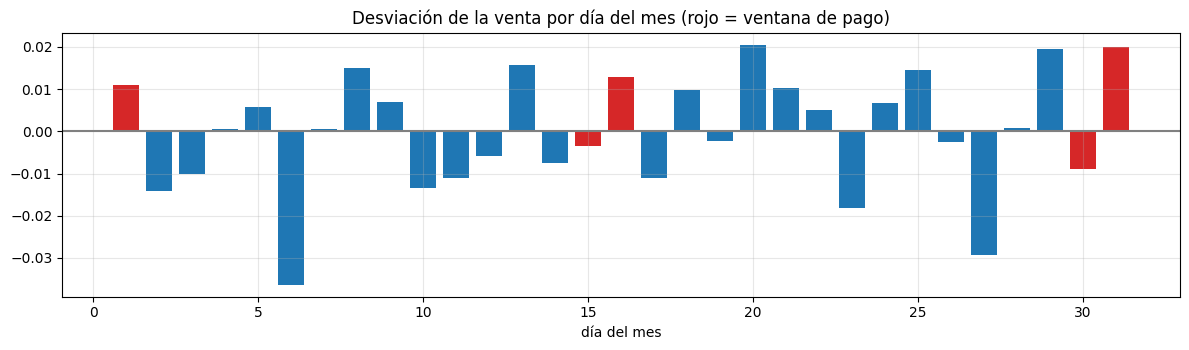

In [49]:
from scipy.stats import ttest_ind
nd = normal.copy()
a, b = nd.loc[nd["ventana_pago"] == 1, "ratio"], nd.loc[nd["ventana_pago"] == 0, "ratio"]
t_, p_ = ttest_ind(a, b, equal_var=False)
print(f"Ventana de pago (días 1, 15, 16, 30, 31): ratio {a.mean():.3f} (n={len(a)}) vs resto {b.mean():.3f} (n={len(b)}) | t={t_:.2f}, p={p_:.3f}")
por_dia = nd.groupby("dia_mes")["ratio"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(por_dia.index, por_dia["mean"] - 1, color=np.where(por_dia.index.isin([1, 15, 16, 30, 31]), "tab:red", "tab:blue"))
ax.axhline(0, color="gray"); ax.set_title("Desviación de la venta por día del mes (rojo = ventana de pago)"); ax.set_xlabel("día del mes")
plt.tight_layout(); plt.show()

### 🔎 Lectura — Ventana de pago: sin efecto
- Venta relativa de 1.006 en la ventana de pago contra 0.999 en el resto (p = 0.37): una diferencia de 0.7 %, indistinguible de cero.
- El gráfico oscila ±2–3 % sin patrón; los días más bajos (6 y 27) no son de pago. Cada día del mes tiene solo 3 observaciones, así que ninguna barra se interpreta por separado: vale el contraste agrupado.

**Decisión:** `ventana_pago` no entra al modelo. Con solo 10 días en la ventana, un efecto pequeño podría pasar inadvertido.

## H3 · El patrón semanal es distinto según producto o tamaño de tienda
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** ¿El fin de semana sube igual para todos los productos y todas las tiendas, o el perfil semanal cambia según el producto, el tamaño o la ciudad?

**Cómo se prueba.** Primero, mapas de calor del índice semanal (venta de ese día ÷ promedio diario del SKU-tienda) por producto y por tamaño de tienda. Después, una prueba formal: se ajusta un modelo donde cada SKU-tienda tiene su propio nivel y el día de la semana tiene un efecto común, y se mide cuánto de la variación diaria explica (R²). Luego se permite un perfil distinto por producto, por tamaño o por ciudad y se ve si el R² mejora; la estadística F indica si esa mejora se distingue de cero.

#### Prueba: día de la semana × producto / tamaño de tienda

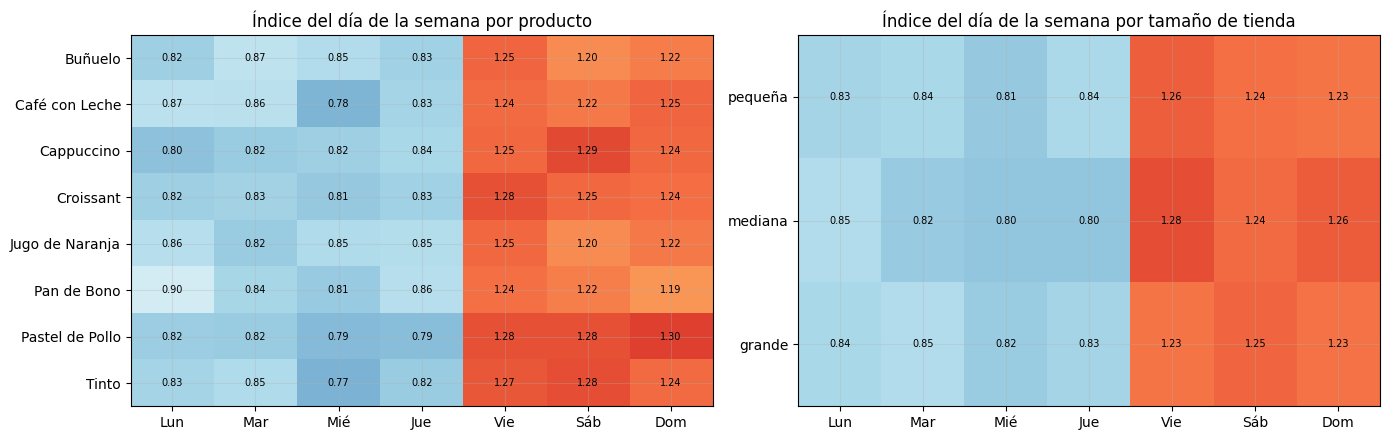

,R2_within,F,p
modelo,,,
solo día de la semana,0.25,NaN,NaN
+ día × producto,0.28,10.95,0.00
+ día × tamaño de tienda,0.26,12.91,0.00
+ día × ciudad,0.26,1.27,0.23


In [50]:
nv = vv[~evento].copy()
nv = nv.merge(tiendas[["id_tienda", "tamaño_m2"]], on="id_tienda").merge(catalogo[["id_producto", "nombre"]], on="id_producto")
nv["tamano"] = pd.qcut(nv["tamaño_m2"], 3, labels=["pequeña", "mediana", "grande"])

# Índice del día de la semana (1.00 = promedio del SKU-tienda) por producto y por tamaño de tienda
nv["idx"] = nv["unidades_vendidas"] / nv.groupby(["id_tienda", "id_producto"])["unidades_vendidas"].transform("mean")
dias_n = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["nombre", "tamano"]):
    h = nv.pivot_table(index=col, columns="dow", values="idx", aggfunc="mean", observed=True); h.columns = dias_n
    im = ax.imshow(h.values, cmap="RdYlBu_r", aspect="auto", vmin=0.6, vmax=1.4)
    ax.set_xticks(range(7)); ax.set_xticklabels(dias_n); ax.set_yticks(range(len(h))); ax.set_yticklabels(h.index)
    for i in range(h.shape[0]):
        for j in range(7): ax.text(j, i, f"{h.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"Índice del día de la semana por {'producto' if col == 'nombre' else 'tamaño de tienda'}")
plt.tight_layout(); plt.show()

# Prueba formal: ¿agregar día×producto (o día×tamaño) mejora el ajuste, con efectos fijos por SKU-tienda?
from scipy.stats import f as f_dist
key = (nv["id_tienda"] + "|" + nv["id_producto"]).values
y = nv["unidades_vendidas"].astype(float).values
def within(X: pd.DataFrame) -> np.ndarray:
    return (X - X.groupby(key).transform("mean")).values
def ajuste(X):
    Xd = within(X); yd = y - pd.Series(y).groupby(key).transform("mean").values
    beta, *_ = np.linalg.lstsq(Xd, yd, rcond=None); r = yd - Xd @ beta
    return float(r @ r), int(np.linalg.matrix_rank(Xd)), float(yd @ yd)
dow_d = pd.get_dummies(nv["dow"]).astype(float).reset_index(drop=True)
def inter(col):
    return pd.get_dummies(nv["dow"].astype(str) + "|" + nv[col].astype(str)).astype(float).reset_index(drop=True)
n_fe = len(set(key)); N_ = len(y)
rss0, k0, tss = ajuste(dow_d)
filas = [{"modelo": "solo día de la semana", "R2_within": 1 - rss0 / tss, "F": np.nan, "p": np.nan}]
for nombre, col in [("+ día × producto", "id_producto"), ("+ día × tamaño de tienda", "tamano"), ("+ día × ciudad", "id_tienda")]:
    if col == "id_tienda":
        nv["_ciudad"] = nv["id_tienda"].map(tiendas.set_index("id_tienda")["ciudad"]); col = "_ciudad"; 
    rss1, k1, _ = ajuste(inter(col))
    F_ = ((rss0 - rss1) / max(k1 - k0, 1)) / (rss1 / (N_ - n_fe - k1))
    filas.append({"modelo": nombre, "R2_within": 1 - rss1 / tss, "F": F_, "p": 1 - f_dist.cdf(F_, max(k1 - k0, 1), N_ - n_fe - k1)})
display(pd.DataFrame(filas).set_index("modelo").round(4))

### 🔎 Lectura — Día de la semana × producto y tienda: casi el mismo patrón para todos
- En todos los productos y tamaños de tienda, el índice semanal va de 0.77 a 0.90 de lunes a jueves y de 1.19 a 1.30 de viernes a domingo: el fin de semana vende cerca de 50 % más. Hay matices: Tinto, Croissant y Pastel de Pollo suben un poco más (1.24–1.30); Pan de Bono, Buñuelo y Jugo, un poco menos (1.19–1.25).
- El día de la semana explica R² = 0.25 de la variación diaria dentro de cada SKU-tienda; el 75 % restante es ruido diario. Un perfil distinto por producto sube el R² a 0.28 (F = 10.95), por tamaño de tienda a 0.26 (F = 12.91), y por ciudad no aporta (F = 1.27, p = 0.23).
- Con ≈13,000 observaciones los p-valores salen minúsculos aunque el efecto sea chico. Lo que cuenta es el tamaño: +3 puntos de R² por producto y +1 por tamaño. Un perfil semanal común explica casi todo.

**Decisión:** perfil semanal común, con el producto como variable (un modelo de árboles recoge el matiz). La ciudad no hace falta y el tamaño aporta poco.

## H4 · Hay memoria: un día atípico anticipa los siguientes
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** Si un SKU-tienda vendió más de lo esperado hoy, ¿vende más de lo esperado mañana, o la semana siguiente?

**Cómo se prueba.** Se calcula el residuo diario (venta relativa − 1) y su **autocorrelación**: la correlación entre el residuo de un día y el de k días después, promediada sobre los 160 SKU-tienda. Si hubiera memoria, las barras de los primeros rezagos serían altas. Las líneas rojas marcan hasta dónde llegaría la correlación solo por azar (±2σ). Además se mide la **persistencia semanal**: la correlación entre el residuo promedio de una semana y el de la siguiente.

#### Prueba: memoria del residuo

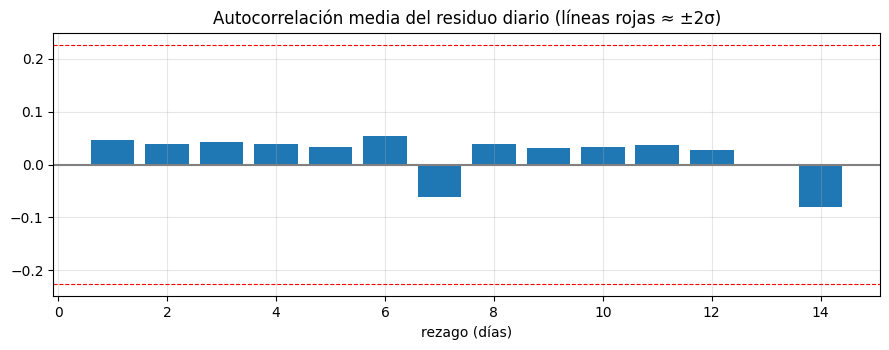

Persistencia media del nivel semanal (corr. entre semana t y t+1, por SKU-tienda): 0.10


In [51]:
# Residuo = venta / venta esperada de su día de la semana (días normales) - 1. Si hay memoria, hay autocorrelación.
vv["res"] = np.where(evento, np.nan, vv["unidades_vendidas"] / vv["esperado"] - 1)
piv = vv.pivot_table(index="fecha", columns=["id_tienda", "id_producto"], values="res")
lags = range(1, 15)
acf = pd.Series({L: np.nanmean([piv[c].autocorr(L) for c in piv.columns]) for L in lags})
n_ef = piv.notna().sum().mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(acf.index, acf.values, color="tab:blue"); ax.axhline(0, color="gray")
ax.axhline(2 / np.sqrt(n_ef), color="red", ls="--", lw=0.8); ax.axhline(-2 / np.sqrt(n_ef), color="red", ls="--", lw=0.8)
ax.set_title("Autocorrelación media del residuo diario (líneas rojas ≈ ±2σ)"); ax.set_xlabel("rezago (días)")
plt.tight_layout(); plt.show()

# Persistencia del nivel semanal: ¿una semana alta anticipa otra alta?
sem = vv.assign(sem=(vv["fecha"] - vv["fecha"].min()).dt.days // 7).groupby(["id_tienda", "id_producto", "sem"])["res"].mean().unstack()
pers = np.nanmean([sem.loc[i].iloc[:-1].corr(sem.loc[i].iloc[1:].reset_index(drop=True).set_axis(sem.loc[i].iloc[:-1].index)) for i in sem.index])
print(f"Persistencia media del nivel semanal (corr. entre semana t y t+1, por SKU-tienda): {pers:.2f}")

### 🔎 Lectura — Memoria: el residuo se comporta como ruido
- Todas las barras de autocorrelación quedan dentro de las líneas rojas. En los rezagos 1 a 12 valen entre +0.03 y +0.05: una persistencia mínima, coherente con el 39 % de SKU-tienda que tienen tendencia propia (H6).
- Los valores negativos de los rezagos 7 (−0.06) y 14 (−0.08) son un efecto mecánico del cálculo: la venta esperada sale de la misma muestra, lo que fuerza una correlación negativa entre observaciones del mismo día de la semana (≈ −1/11 ≈ −0.09). No son un hallazgo.
- La persistencia semanal es 0.10: una semana alta anticipa apenas un poco a la siguiente.

**Decisión:** una vez conocidos el perfil semanal y el nivel del SKU-tienda, lo que vendió ayer aporta poco. Los rezagos y las medias de varias semanas se usan para estimar mejor el nivel (promediar baja el ruido), no para capturar dinámica. Por eso entran al modelo.

## H5 · Hay choques comunes (de tienda, de día o entre productos) que ningún SKU explica
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** ¿Hay eventos que muevan varios productos a la vez (una tienda con un día raro, o un día raro para toda la cadena)? Si los hubiera, los errores de pronóstico irían juntos y harían falta más colchón.

**Cómo se prueba.** De forma descriptiva, sin p-valor, con dos comparaciones sobre el residuo diario:
1. **Cociente de varianzas.** Si los 8 productos de una tienda fluctuaran de forma independiente, la varianza de su promedio diario sería la varianza individual dividida entre 8. Se divide lo observado entre lo esperado: cerca de 1 indica independencia; bastante mayor que 1, choques comunes. Se repite para el promedio de todas las tiendas en un día.
2. **Correlación entre productos** de la misma tienda y día: cerca de 0 significa que no se mueven juntos.

#### Prueba: choques comunes

In [52]:
r = vv.dropna(subset=["res"])[["fecha", "id_tienda", "id_producto", "res"]]
n_prod_ = r["id_producto"].nunique(); n_tien_ = r["id_tienda"].nunique()
v_tot = r["res"].var()
v_td = r.groupby(["id_tienda", "fecha"])["res"].mean().var()          # media de los productos de una tienda en un día
v_d = r.groupby("fecha")["res"].mean().var()                         # media de todo Tostao en un día
print(f"Varianza del residuo: {v_tot:.4f}")
print(f"  Si los productos fueran independientes dentro de una tienda-día, var(media tienda-día) ≈ {v_tot / n_prod_:.4f} | observada: {v_td:.4f}  (razón {v_td / (v_tot / n_prod_):.2f})")
print(f"  Si las tiendas fueran independientes en un día,                var(media del día)      ≈ {v_tot / (n_prod_ * n_tien_):.5f} | observada: {v_d:.5f}  (razón {v_d / (v_tot / (n_prod_ * n_tien_)):.2f})")
cc = r.pivot_table(index=["id_tienda", "fecha"], columns="id_producto", values="res").corr()
cc.index = cc.columns = [catalogo.set_index("id_producto")["nombre"].get(c, c) for c in cc.columns]
print("Correlación entre productos dentro de la misma tienda-día (residuos):"); display(cc.round(2))

Varianza del residuo: 0.1189
  Si los productos fueran independientes dentro de una tienda-día, var(media tienda-día) ≈ 0.0149 | observada: 0.0146  (razón 0.98)
  Si las tiendas fueran independientes en un día,                var(media del día)      ≈ 0.00074 | observada: 0.00055  (razón 0.75)
Correlación entre productos dentro de la misma tienda-día (residuos):


,Tinto,Café con Leche,Cappuccino,Pan de Bono,Buñuelo,Croissant,Pastel de Pollo,Jugo de Naranja
Tinto,1.00,-0.02,-0.02,-0.01,-0.03,0.01,-0.03,-0.02
Café con Leche,-0.02,1.00,-0.00,0.06,-0.00,0.05,-0.02,-0.02
Cappuccino,-0.02,-0.00,1.00,0.01,0.05,0.04,-0.06,0.06
Pan de Bono,-0.01,0.06,0.01,1.00,-0.02,-0.02,-0.06,0.00
Buñuelo,-0.03,-0.00,0.05,-0.02,1.00,0.00,-0.04,-0.02
Croissant,0.01,0.05,0.04,-0.02,0.00,1.00,-0.02,0.03
Pastel de Pollo,-0.03,-0.02,-0.06,-0.06,-0.04,-0.02,1.00,0.02
Jugo de Naranja,-0.02,-0.02,0.06,0.00,-0.02,0.03,0.02,1.00


### 🔎 Lectura — Choques comunes: no hay
- **Tienda-día:** cociente de 0.98. Los productos de una tienda fluctúan de forma independiente; no hay eventos locales que muevan todo a la vez.
- **Día global:** cociente de 0.75, menor que 1. Tampoco hay choques compartidos entre tiendas (el valor bajo se debe a usar el promedio de la misma muestra).
- **Correlaciones entre productos:** entre −0.07 y +0.06. No hay arrastre entre productos en las ventas diarias, lo que coincide con el lift menor que 1 de H9.

**Implicación:** cada SKU-tienda tiene un ruido diario propio (CV residual ≈ 0.31) que ninguna variable explica. Es el piso de error: por mucho que se refine el modelo, no se pronostica mejor que eso.

## H6 · Cada SKU tiene una tendencia propia, y `ground_truth_trends` la describe
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** ¿Cada SKU-tienda tiene su propia tendencia, y las etiquetas de `ground_truth_trends` (`up`, `down`, `seasonal`, `random`) la describen?

**Cómo se prueba.** Primero con métricas simples por SKU-tienda. Después, con una regresión que controla el día de la semana y mide la pendiente por semana, con su estadístico t (|t| > 2 se toma como tendencia). Por último, se compara el tipo sembrado en la etiqueta con el tipo detectado.

#### Prueba: validación con `ground_truth_trends`: ¿nuestras métricas detectan lo que se sembró?

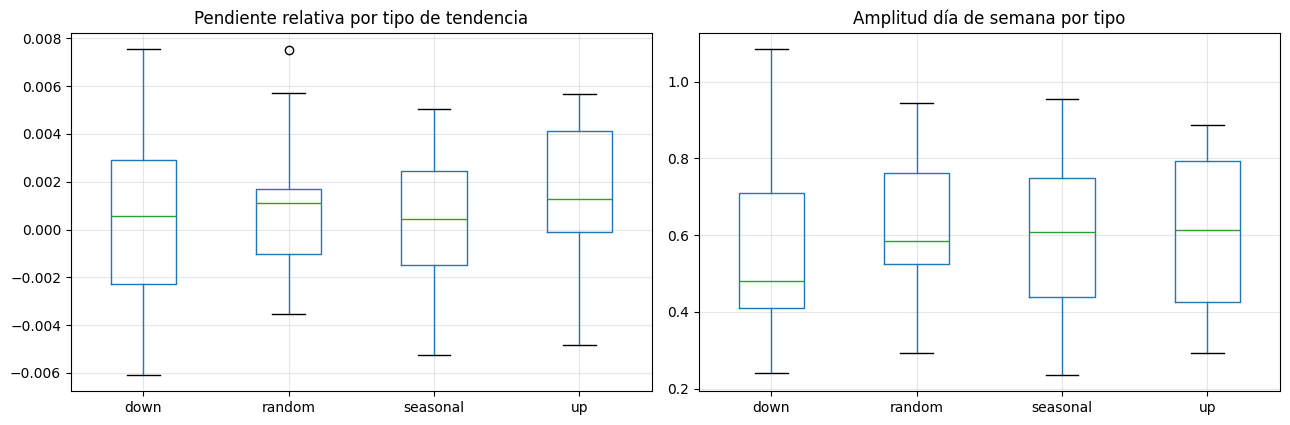

,tendencia_rel_dia,amp_dow,cv,pct_ceros
trend_type,,,,
down,0.00,0.56,0.40,0.00
random,0.00,0.62,0.45,0.00
seasonal,0.00,0.60,0.41,0.00
up,0.00,0.61,0.40,0.00


patron,Smooth
trend_type,
down,44
random,32
seasonal,57
up,27


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sku.boxplot(column="tendencia_rel_dia", by="trend_type", ax=axes[0]); axes[0].set_title("Pendiente relativa por tipo de tendencia"); axes[0].set_xlabel("")
sku.boxplot(column="amp_dow", by="trend_type", ax=axes[1]); axes[1].set_title("Amplitud día de semana por tipo"); axes[1].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()
display(sku.groupby("trend_type")[["tendencia_rel_dia", "amp_dow", "cv", "pct_ceros"]].mean())
display(pd.crosstab(sku["trend_type"], sku["patron"]))

### 🔎 Lectura — Validación con `ground_truth_trends`: las métricas simples no separan los tipos
- La pendiente relativa mediana por tipo es muy parecida y se solapa mucho (down ≈ 0.0006, random ≈ 0.0011, seasonal ≈ 0.0005, up ≈ 0.0013). La amplitud semanal es ≈ 0.6 en todos los tipos, incluidos `random` y `up`.
- Dos razones: el patrón de fin de semana es global (no exclusivo de `seasonal`) y las tendencias sembradas son pequeñas frente al ruido diario (CV ≈ 0.4) en solo 13 semanas.
- La pendiente cruda no controla el día de la semana y es ruidosa; la celda siguiente la reemplaza por una regresión que sí lo controla.

**Decisión:** no usar `trend_type` como variable (no tiene señal clara y no existiría en producción). Se usa solo para validar.

> Lo que se esperaría ver si las etiquetas fueran fiables: pendiente positiva en `up`, negativa en `down` y mayor amplitud semanal en `seasonal`.

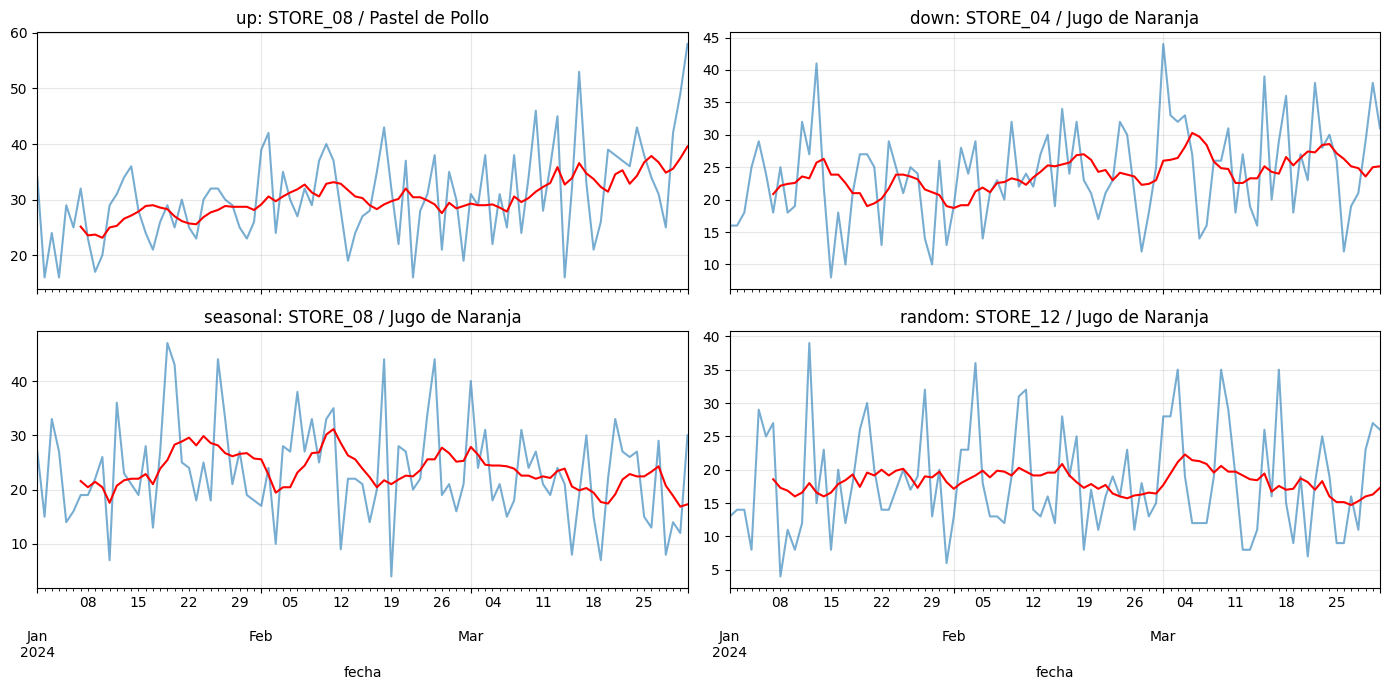

In [54]:
# Ejemplo visual: una serie por tipo de tendencia
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, tp in zip(axes.ravel(), ["up", "down", "seasonal", "random"]):
    fila = sku[sku["trend_type"] == tp].iloc[0]
    s = ventas[(ventas.id_tienda == fila.id_tienda) & (ventas.id_producto == fila.id_producto)].set_index("fecha")["unidades_vendidas"]
    s.plot(ax=ax, alpha=.6); s.rolling(7).mean().plot(ax=ax, color="red")
    ax.set_title(f"{tp}: {fila.id_tienda} / {fila['nombre']}")
plt.tight_layout(); plt.show()

### 🔎 Lectura — Series de ejemplo
Las series de ejemplo confirman lo mismo: `up` (STORE_08 / Pastel) sí sube, pero `down` (STORE_04 / Jugo) parece subir, y `seasonal` (STORE_08 / Jugo) no se distingue de `random`. O las etiquetas no coinciden con lo que se ve, o el efecto es demasiado pequeño para verlo en 13 semanas. Se reporta así, sin forzar la conclusión.

In [55]:
# Tendencia justa: regresión por SKU-tienda con dummies de día de la semana + pendiente (en semanas)
def tendencia_ctrl_dow(s: pd.DataFrame) -> pd.Series:
    s = s.sort_values("fecha")
    y = s["unidades_vendidas"].values.astype(float)
    t_ = np.arange(len(y)) / 7.0
    D = pd.get_dummies(s["fecha"].dt.dayofweek).values.astype(float)
    X = np.column_stack([D, t_])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ beta
    s2 = res @ res / (len(y) - X.shape[1])
    se = np.sqrt(s2 * np.linalg.inv(X.T @ X)[-1, -1])
    return pd.Series({"pend_rel_sem": beta[-1] / y.mean(), "t_stat": beta[-1] / se,
                      "cv_residual": res.std() / y.mean(), "cv_crudo": y.std() / y.mean()})

tr = (ventas.groupby(["id_tienda", "id_producto"]).apply(tendencia_ctrl_dow).reset_index()
      .merge(tendencias, on=["id_tienda", "id_producto"]))
tr["detectada"] = np.select([tr["t_stat"] > 2, tr["t_stat"] < -2], ["up", "down"], "sin tendencia")

print("Pendiente relativa semanal y t-stat por tipo sembrado:")
display(tr.groupby("trend_type")[["pend_rel_sem", "t_stat"]].agg(["mean", "median"]).round(3))
print("Tipo sembrado vs. tipo detectado (|t|>2):")
display(pd.crosstab(tr["trend_type"], tr["detectada"]))
print(f"CV diario crudo (mediana): {tr['cv_crudo'].median():.2f} | CV residual tras quitar día de semana + tendencia: {tr['cv_residual'].median():.2f}")

Pendiente relativa semanal y t-stat por tipo sembrado:


pend_rel_sem        t_stat       
                   mean median   mean median
trend_type                                  
down              -0.00  -0.00   0.09  -0.06
random             0.00   0.00   0.16   0.24
seasonal          -0.00  -0.00  -0.03  -0.22
up                 0.01   0.00   0.96   0.43

Tipo sembrado vs. tipo detectado (|t|>2):


detectada,down,sin tendencia,up
trend_type,,,
down,10,23,11
random,2,26,4
seasonal,11,35,11
up,5,13,9


CV diario crudo (mediana): 0.41 | CV residual tras quitar día de semana + tendencia: 0.31


### 🔎 Lectura — Tendencias con el día de la semana controlado
- Sí hay tendencias: 63 de 160 SKU-tienda (39 %) tienen una pendiente claramente distinta de cero. Con puro ruido se esperaría cerca de 5 %.
- La dirección no coincide con la etiqueta: entre los `down`, 10 bajan y 11 suben; entre los `up`, 9 suben y 5 bajan. Es casi un empate en ambos (p ≈ 0.7).
- Los `random` tienen menos SKU-tienda con tendencia (19 %) que el resto (≈40–50 %), y esa diferencia parece real (p ≈ 0.008). Posible lectura: la etiqueta distingue "tiene algún patrón" de "no lo tiene", pero no la dirección. Con pocos SKU es una hipótesis, no una conclusión.

**Decisión.** No usar `trend_type`: no predice la dirección y en producción no existiría. Tampoco asumir un nivel plano: con 39 % de SKU-tienda con tendencia propia, el modelo debe aprender el nivel reciente de cada uno con rezagos y medias móviles. En la presentación: la etiqueta del dataset no recupera la tendencia observada, y el modelo la aprende de los datos recientes.

## Bloque B — Variables externas y de negocio (H7 a H11)
<sup><a href="#Contenido">↑ Contenido</a></sup>

## H7 · El clima, el tráfico y el precio de la competencia mueven la demanda
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** ¿La lluvia, el tráfico o el precio de la competencia explican parte de las ventas? (Solo hay datos de 10 de las 20 tiendas.)

**Cómo se prueba.** Para cada SKU-tienda y día se calcula la venta relativa (venta real ÷ venta esperada para ese día de la semana; 1.00 = normal) y se promedia por tienda-día. Con el clima se compara el promedio por tipo de clima con su intervalo de confianza al 95 %: si los intervalos no se solapan, hay efecto. Con el tráfico y el precio de la competencia se usa la correlación de Spearman con la venta relativa (0 = sin relación).

#### Prueba: clima, tráfico y precio de la competencia

Filas de ventas con exógenas: 7,280 de 14,560 (50 %) | tiendas cubiertas: 10 de 20
Venta relativa por clima (1.00 = normal para ese día de la semana):


,mean,count,std,ic95_±
clima,,,,
Cloudy,0.99,310,0.12,0.01
Rainy,0.99,180,0.12,0.02
Sunny,1.01,420,0.13,0.01


Spearman venta relativa vs índice de tráfico: rho=-0.025 (p=0.457)
Spearman venta relativa vs índice de precio de la competencia: rho=0.012 (p=0.711)


clima,Cloudy,Rainy,Sunny
nombre,,,
Buñuelo,1.01,0.97,1.00
Café con Leche,1.00,0.97,1.01
Cappuccino,1.00,0.96,1.02
Croissant,0.98,1.02,1.01
Jugo de Naranja,1.00,0.99,1.01
Pan de Bono,0.99,0.99,1.01
Pastel de Pollo,1.00,0.99,1.00
Tinto,0.98,1.01,1.01


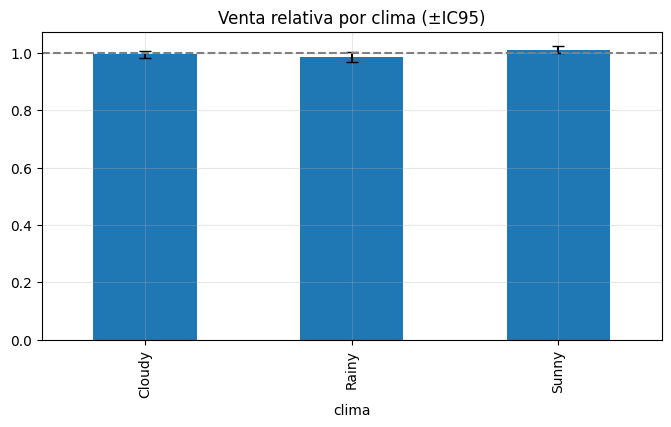

In [56]:
# Ratio = venta del día / venta típica de ese SKU-tienda en ese día de la semana  (1.0 = normal; controla el patrón semanal)
base = ventas[["fecha", "id_tienda", "id_producto", "unidades_vendidas"]].copy()
base["dow"] = base["fecha"].dt.dayofweek
base["esperado"] = base.groupby(["id_tienda", "id_producto", "dow"])["unidades_vendidas"].transform("mean")
base["ratio"] = base["unidades_vendidas"] / base["esperado"]

if exo is None:
    print("Sin variables_exogenas.")
else:
    m_ex = base.merge(exo, on=["fecha", "id_tienda"], how="inner")
    print(f"Filas de ventas con exógenas: {len(m_ex):,} de {len(base):,} ({100*len(m_ex)/len(base):.0f} %) | "
          f"tiendas cubiertas: {m_ex['id_tienda'].nunique()} de {base['id_tienda'].nunique()}")
    if len(m_ex) == 0:
        print("⚠ No hay cruce por (fecha, id_tienda): no se pueden usar para el Caso A.")
    else:
        sd = (m_ex.groupby(["fecha", "id_tienda", "clima"])
                  .agg(ratio=("ratio", "mean"), trafico=("indice_trafico", "first"),
                       comp=("competitor_price_index", "first")).reset_index())
        res = sd.groupby("clima")["ratio"].agg(["mean", "count", "std"])
        res["ic95_±"] = 1.96 * res["std"] / np.sqrt(res["count"])
        print("Venta relativa por clima (1.00 = normal para ese día de la semana):")
        display(res.round(3))
        from scipy.stats import spearmanr
        for c, nom in [("trafico", "índice de tráfico"), ("comp", "índice de precio de la competencia")]:
            r = spearmanr(sd["ratio"], sd[c], nan_policy="omit")
            print(f"Spearman venta relativa vs {nom}: rho={r.correlation:.3f} (p={r.pvalue:.3f})")
        # ¿algún producto es más sensible al clima?
        pm = (m_ex.merge(catalogo[["id_producto", "nombre"]], on="id_producto")
                  .pivot_table(index="nombre", columns="clima", values="ratio", aggfunc="mean"))
        display(pm.round(3))
        fig, ax = plt.subplots(figsize=(8, 4))
        res["mean"].plot.bar(yerr=res["ic95_±"], ax=ax, color="tab:blue", capsize=4)
        ax.axhline(1, color="gray", ls="--"); ax.set_title("Venta relativa por clima (±IC95)"); plt.show()

### 🔎 Lectura — Clima, tráfico y competencia: sin efecto utilizable
- **Clima:** venta relativa de 1.01 con sol (±0.01), 0.99 nublado (±0.01) y 0.99 con lluvia (±0.02). Entre soleado y lluvioso hay ≈2 puntos y los intervalos casi se tocan: efecto mínimo.
- **Tráfico:** ρ = −0.025 (p = 0.46). **Precio de la competencia:** ρ = 0.012 (p = 0.71). Ninguno se distingue de cero.
- **Por producto** (Cappuccino 0.96 con lluvia contra 1.02 con sol; Café con Leche 0.97 contra 1.01; Croissant al revés): diferencias de 3–6 % con ≈180 días-tienda lluviosos por celda y ruido diario de ≈35 %. Con 8 productos × 3 climas se esperan "efectos" por azar, y además van contra la intuición (menos bebida caliente con lluvia).

**Decisión:** no entran al modelo. Solo cubren 10 de las 20 tiendas y, en producción, el clima de la semana no se conocería de antemano.

## H8 · Las promociones mueven las unidades vendidas
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** ¿Una promoción (2x1, monto fijo o porcentaje) sube las unidades del producto y explica los picos de demanda?

**Cruce por nombre.** Las promociones usan la numeración de productos de la carpeta 02, no la del Caso A; un cruce por código compararía productos equivocados. Por eso se cruzan por nombre con el catálogo de la carpeta 02 (ver 1.1).

**Cómo se prueba.**
1. Cada promoción se expande en sus días (de inicio a fin) y se marcan los días SKU-tienda en promo.
2. Se compara la venta relativa (venta real ÷ venta esperada; 1.00 = normal) en esos días contra los días sin promo, por tipo de promoción. El criterio es si el intervalo de confianza al 95 % excluye 1.00.
3. Se revisa si los picos de demanda caen en promo más seguido que el resto de los días.

In [57]:
# PROMOCIONES con el cruce por NOMBRE (el id_producto de la tabla de promos es el de la carpeta 02)
if promos is None or not CROSSWALK:
    print("Faltan promociones o el cruce de productos (ver 1.1).")
else:
    inv_cw = {v: k for k, v in CROSSWALK.items()}                  # id carpeta 02 -> id Caso A
    pr = promos.assign(id_producto_caso_a=promos["id_producto"].map(inv_cw))
    cruza = pr[pr["id_tienda"].isin(sup_t) & pr["id_producto_caso_a"].notna()]
    print(f"Promociones totales: {len(promos)} | que cruzan por NOMBRE con productos y tiendas del Caso A: {len(cruza)}  (el cruce por código daba 84, con productos equivocados)")
    if len(cruza) == 0:
        print("⚠ Ninguna promoción cruza con los productos del Caso A.")
    else:
        filas = []
        for r in cruza.itertuples():
            for dd in pd.date_range(r.fecha_inicio, r.fecha_fin):
                filas.append((dd, r.id_tienda, r.id_producto_caso_a, r.tipo_descuento))
        pe = (pd.DataFrame(filas, columns=["fecha", "id_tienda", "id_producto", "tipo_descuento"])
                .drop_duplicates(["fecha", "id_tienda", "id_producto"]))
        m_pr = base.merge(pe, on=["fecha", "id_tienda", "id_producto"], how="left")
        m_pr["en_promo"] = m_pr["tipo_descuento"].notna()
        print(f"Días SKU-tienda en promo: {m_pr['en_promo'].sum():,} ({100*m_pr['en_promo'].mean():.1f} %)")
        up = m_pr.groupby(m_pr["tipo_descuento"].fillna("Sin promo"))["ratio"].agg(["mean", "count", "std"])
        up["ic95_±"] = 1.96 * up["std"] / np.sqrt(up["count"])
        print("Venta relativa según tipo de promo (1.00 = normal para ese SKU-tienda y día de la semana):"); display(up.round(3))
        pp = (m_pr.merge(catalogo[["id_producto", "nombre"]], on="id_producto")
                  .groupby(["nombre", "en_promo"])["ratio"].agg(["mean", "count"]).unstack("en_promo").round(3))
        print("Venta relativa por producto (sin promo vs. con promo):"); display(pp)
        pk = outliers[outliers["z_rob"] > 3.5][["fecha", "id_tienda", "id_producto"]].merge(
            m_pr[["fecha", "id_tienda", "id_producto", "en_promo"]], on=["fecha", "id_tienda", "id_producto"], how="left")
        print(f"Picos en promo: {100*pk['en_promo'].mean():.0f} % (base: {100*m_pr['en_promo'].mean():.1f} % de los días están en promo)")
        print("Picos por tienda, en promo vs. total:"); display(pk.groupby("id_tienda")["en_promo"].agg(["sum", "count"]).sort_values("count", ascending=False).head(6))

Promociones totales: 493 | que cruzan por NOMBRE con productos y tiendas del Caso A: 91  (el cruce por código daba 84, con productos equivocados)
Días SKU-tienda en promo: 799 (5.5 %)
Venta relativa según tipo de promo (1.00 = normal para ese SKU-tienda y día de la semana):


,mean,count,std,ic95_±
tipo_descuento,,,,
2x1,1.01,259,0.36,0.04
Fixed_Amount,0.94,177,0.36,0.05
Percentage,1.01,363,0.34,0.04
Sin promo,1.00,13761,0.35,0.01


Venta relativa por producto (sin promo vs. con promo):


mean       count      
en_promo        False True  False True 
nombre                                 
Buñuelo          1.00  0.94  1756    64
Café con Leche   1.00  0.87  1764    56
Cappuccino       1.00  1.03  1647   173
Croissant        1.00  0.97  1701   119
Jugo de Naranja  1.00  1.01  1795    25
Pan de Bono      0.99  1.05  1627   193
Pastel de Pollo  1.00  0.99  1724    96
Tinto            1.00  0.96  1747    73

Picos en promo: 4 % (base: 5.5 % de los días están en promo)
Picos por tienda, en promo vs. total:


,sum,count
id_tienda,,
STORE_20,0,9
STORE_09,1,5
STORE_07,0,5
STORE_10,0,5
STORE_12,0,4
STORE_01,0,4


### 🔎 Lectura — Promociones: sin efecto
- 91 promociones cruzan con productos y tiendas del Caso A, lo que da 799 días SKU-tienda en promo (5.5 %).
- Venta relativa en promo: 2x1 → 1.01 (±0.04); porcentaje → 1.01 (±0.04); monto fijo → 0.94 (±0.05). Los dos primeros son indistinguibles de 1.00. El tercero queda por debajo, con un intervalo (0.89–0.99) que apenas excluye 1.00. Ningún tipo sube las unidades.
- Por producto, Café con Leche (0.87, 56 días), Buñuelo (0.94), Tinto (0.96), Croissant (0.97) y Pastel (0.99) quedan por debajo; Pan de Bono (1.05) y Cappuccino (1.03), por encima. Con 8 productos × 3 tipos de promoción y pocos días por celda, es normal que algunas se alejen de 1.00 por azar; no lo leemos como un efecto real.
- Los picos no son promociones: solo 4 % de los picos cae en promo, frente a 5.5 % de todos los días. Los 9 picos de `STORE_20` quedan fuera de promo.
- Con el cruce por código (equivocado) el resultado era el mismo (2x1 1.02, monto fijo 0.98, porcentaje 1.02), así que la conclusión no cambió.

**Decisión:** las promociones no entran al modelo. La última promo termina el 31-mar, por lo que no hay ninguna conocida para la semana a pronosticar. Los picos se tratan como ruido y se cubren con cuantiles altos. Que un 2x1 no mueva unidades es raro en un negocio real, lo que sugiere que estas tablas se generaron sin relación con las ventas.

## H9 · La venta cruzada cambia el costo de quedarse corto
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** Si falta un producto, el cliente también deja de comprar lo que habría llevado con él. ¿Cuánto cambia eso el costo de quedarse corto? `Cu ajustado = margen + β × margen del resto de la canasta`.

**Cruce por nombre.** Cada producto del Caso A se cruza por nombre con la carpeta 02 (un cruce por código asignaría la canasta de otro producto a 5 de los 8). Además, la venta cruzada se calcula por grupos (subcategorías: bebidas calientes y frías, panadería salada y dulce, sandwiches).

**Cómo se calcula.**
- β es la fracción de esa venta cruzada que realmente se pierde. Es un supuesto y se muestra de 0 a 100 %.
- El margen del resto de la canasta se valora con el margen promedio del catálogo (≈64 %), porque los tickets no traen costos.
- `MODO = "general"` usa la cifra de todas las canastas para los 8 productos; `MODO = "propio"` usa la de cada producto, y la general donde no hay cruce.
- El **lift** entre dos productos o grupos mide cuánto más probable es comprar uno si se compra el otro, frente a su probabilidad base. Cerca de 1, no hay relación; mayor que 1.1, se complementan; menor que 0.9, se sustituyen.

In [58]:
MODO = "general"   # "general" (caso base) o "propio" (cifra del producto vía cruce por nombre)

if det is None or not CROSSWALK:
    print("Faltan detalle_tickets o el cruce de productos (ver 1.1).")
else:
    dv = det.assign(valor=det["cantidad"] * det["precio_unitario"])        # no se modifica `det`
    margen_pct_prom = cat["margen_unit"].sum() / catalogo["precio_venta"].sum()      # margen % promedio del catálogo
    tot_ticket = dv.groupby("id_ticket")["valor"].sum()

    # (A) Cifra GENERAL: para cada línea de ticket, lo que lleva el cliente además de esa línea
    lineas = dv.assign(resto=dv["id_ticket"].map(tot_ticket) - dv["valor"])
    general = {"prob_lleva_algo_mas": (lineas["resto"] > 0).mean(),
               "valor_resto_por_linea": lineas["resto"].mean(),
               "margen_cruzado_por_unidad": (lineas["resto"] * margen_pct_prom).sum() / lineas["cantidad"].sum()}
    print("Cifra general (todas las canastas):", {k: round(v, 2) for k, v in general.items()})
    print(f"Líneas por ticket: {len(dv)/dv['id_ticket'].nunique():.2f} | unidades por ticket: {dv['cantidad'].sum()/dv['id_ticket'].nunique():.2f}")

    # (B) Cifra PROPIA por producto, usando el equivalente en la carpeta 02
    filas = []
    for pid, nom in catalogo.set_index("id_producto")["nombre"].items():
        pid_t = CROSSWALK.get(pid)
        dx = dv[dv["id_producto"] == pid_t] if pid_t else dv.iloc[0:0]
        if dx.empty:
            filas.append({"id_producto": pid, "nombre": nom, "id_en_carpeta02": pid_t, "tickets_con_prod": 0}); continue
        por_t = dx.groupby("id_ticket").agg(uni_x=("cantidad", "sum"), val_x=("valor", "sum"))
        resto = tot_ticket.reindex(por_t.index) - por_t["val_x"]
        filas.append({"id_producto": pid, "nombre": nom, "id_en_carpeta02": pid_t, "tickets_con_prod": len(por_t),
                      "prob_lleva_algo_mas": (resto > 0).mean(), "valor_resto_por_ticket": resto.mean(),
                      "margen_cruzado_propio": resto.mean() * margen_pct_prom / por_t["uni_x"].mean()})
    vc = pd.DataFrame(filas).merge(cat[["id_producto", "margen_unit", "costo_unitario", "costo_almacenamiento_semanal"]], on="id_producto")
    vc["tipo_match"] = vc["id_producto"].map(cw.set_index("id_producto")["tipo_match"])
    vc["mismo_producto"] = vc["tipo_match"].isin(["exacto", "análogo (alias)"]) & (vc["tickets_con_prod"] > 0)
    vc["margen_cruzado_general"] = general["margen_cruzado_por_unidad"]
    vc["margen_cruzado_usado"] = (vc["margen_cruzado_general"] if MODO == "general"
                                  else vc["margen_cruzado_propio"].fillna(vc["margen_cruzado_general"]))
    display(vc.round(2))
    if (vc.loc[vc["mismo_producto"], "tickets_con_prod"] < 100).any():
        print("⚠ Hay productos con menos de 100 tickets: su cifra propia es poco confiable.")

Cifra general (todas las canastas): {'prob_lleva_algo_mas': np.float64(0.76), 'valor_resto_por_linea': np.float64(4550.68), 'margen_cruzado_por_unidad': np.float64(2833.86)}
Líneas por ticket: 1.84 | unidades por ticket: 1.89


,id_producto,nombre,id_en_carpeta02,tickets_con_prod,prob_lleva_algo_mas,valor_resto_por_ticket,margen_cruzado_propio,margen_unit,costo_unitario,costo_almacenamiento_semanal,tipo_match,mismo_producto,margen_cruzado_general,margen_cruzado_usado
0,PROD_001,Tinto,PROD_001,1419,0.69,"3,660.18","1,960.81",1700,800,10,exacto,True,"2,833.86","2,833.86"
1,PROD_002,Café con Leche,PROD_002,938,0.83,"4,742.96","2,951.89",2300,1200,15,exacto,True,"2,833.86","2,833.86"
2,PROD_003,Cappuccino,PROD_003,1247,0.85,"5,209.78","3,267.63",3000,1500,15,exacto,True,"2,833.86","2,833.86"
3,PROD_004,Pan de Bono,PROD_015,691,0.89,"4,541.68","2,878.82",1800,1000,20,exacto,True,"2,833.86","2,833.86"
4,PROD_005,Buñuelo,PROD_016,636,0.86,"5,249.06","3,334.69",1700,800,20,exacto,True,"2,833.86","2,833.86"
5,PROD_006,Croissant,PROD_023,645,0.89,"5,927.13","3,748.58",2300,1200,25,análogo (alias),True,"2,833.86","2,833.86"
6,PROD_007,Pastel de Pollo,PROD_021,896,0.76,"5,136.72","3,234.82",2000,1500,30,exacto,True,"2,833.86","2,833.86"
7,PROD_008,Jugo de Naranja,PROD_009,684,0.88,"5,305.85","3,357.99",3000,2000,50,exacto,True,"2,833.86","2,833.86"



Ratio crítico (cuantil a pedir) con α=50 % de pérdida del costo unitario si sobra  [MODO=general]:


,β=0%,β=25%,β=50%,β=100%
nombre,,,,
Tinto,0.81,0.85,0.88,0.92
Café con Leche,0.79,0.83,0.86,0.89
Cappuccino,0.80,0.83,0.85,0.88
Pan de Bono,0.78,0.83,0.86,0.90
Buñuelo,0.80,0.85,0.88,0.92
Croissant,0.79,0.83,0.86,0.89
Pastel de Pollo,0.72,0.78,0.81,0.86
Jugo de Naranja,0.74,0.78,0.81,0.85



Ratio crítico (cuantil a pedir) con α=100 % de pérdida del costo unitario si sobra  [MODO=general]:


,β=0%,β=25%,β=50%,β=100%
nombre,,,,
Tinto,0.68,0.75,0.79,0.85
Café con Leche,0.65,0.71,0.75,0.81
Cappuccino,0.66,0.71,0.74,0.79
Pan de Bono,0.64,0.71,0.76,0.82
Buñuelo,0.67,0.75,0.79,0.85
Croissant,0.65,0.71,0.75,0.81
Pastel de Pollo,0.57,0.64,0.69,0.76
Jugo de Naranja,0.59,0.64,0.68,0.74


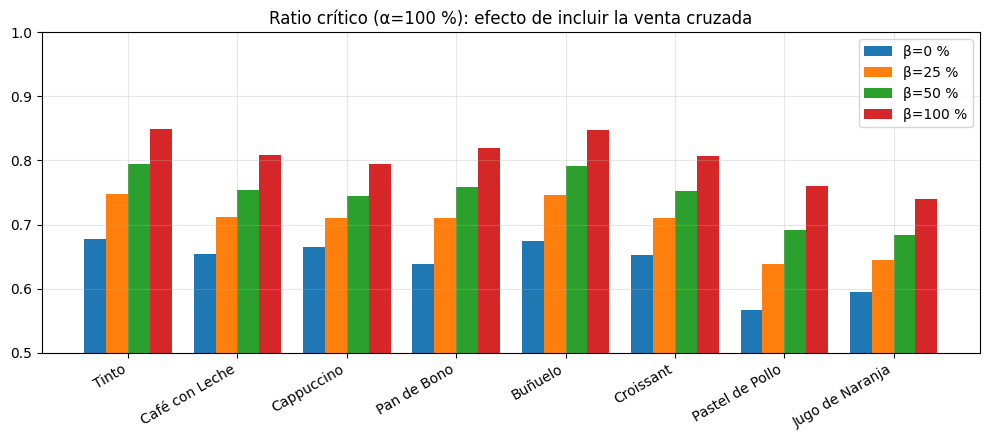


Pedido sobre la demanda media (promedio de los 8 productos; CV semanal supuesto 0.12):


,cuantil,sobre_la_media_pct
"Solo almacenamiento (α=0, β=0)",0.99,27.80
"Perecedero (α=100 %, β=0)",0.64,4.30
"Central (α=50 %, β=25 %)",0.82,11.10
"Perecedero + cruzada (α=100 %, β=100 %)",0.80,10.20



Comparación general vs propio para los productos que sí coinciden:


,nombre,margen_cruzado_general,margen_cruzado_propio,"ratio_general(α=100%,β=50%)","ratio_propio(α=100%,β=50%)"
0,Tinto,"2,833.86","1,960.81",0.79,0.77
1,Café con Leche,"2,833.86","2,951.89",0.75,0.76
2,Cappuccino,"2,833.86","3,267.63",0.74,0.75
3,Pan de Bono,"2,833.86","2,878.82",0.76,0.76
4,Buñuelo,"2,833.86","3,334.69",0.79,0.80
5,Croissant,"2,833.86","3,748.58",0.75,0.77
6,Pastel de Pollo,"2,833.86","3,234.82",0.69,0.70
7,Jugo de Naranja,"2,833.86","3,357.99",0.68,0.70


In [59]:
# Ratio crítico ajustado: β (venta cruzada que se pierde) × α (fracción del costo unitario que se pierde si sobra)
if det is not None:
    v = vc.copy()
    def ratio(beta, alfa, col="margen_cruzado_usado"):
        cu = v["margen_unit"] + beta * v[col]
        co = v["costo_almacenamiento_semanal"] + alfa * v["costo_unitario"]
        return cu / (cu + co)
    for alfa in [0.5, 1.0]:
        tabla = pd.DataFrame({f"β={int(b*100)}%": ratio(b, alfa) for b in [0, 0.25, 0.5, 1.0]})
        tabla.insert(0, "nombre", v["nombre"].values)
        print(f"\nRatio crítico (cuantil a pedir) con α={int(alfa*100)} % de pérdida del costo unitario si sobra  [MODO={MODO}]:")
        display(tabla.set_index("nombre").round(2))
    fig, ax = plt.subplots(figsize=(10, 4.5)); x = np.arange(len(v)); w = 0.2
    for k, b in enumerate([0, 0.25, 0.5, 1.0]):
        ax.bar(x + (k - 1.5) * w, ratio(b, 1.0), w, label=f"β={int(b*100)} %")
    ax.set_xticks(x); ax.set_xticklabels(v["nombre"], rotation=30, ha="right"); ax.set_ylim(0.5, 1.0)
    ax.set_title("Ratio crítico (α=100 %): efecto de incluir la venta cruzada"); ax.legend(); plt.tight_layout(); plt.show()

    # Tamaño del efecto en cantidad: cuánto por encima de la demanda media hay que pedir, con CV semanal ≈ 0.12 (orden de magnitud)
    from scipy.stats import norm
    CV_SEM = 0.12
    esc = {"Solo almacenamiento (α=0, β=0)": ratio(0, 0).mean(), "Perecedero (α=100 %, β=0)": ratio(0, 1.0).mean(),
           "Central (α=50 %, β=25 %)": ratio(0.25, 0.5).mean(), "Perecedero + cruzada (α=100 %, β=100 %)": ratio(1.0, 1.0).mean()}
    print("\nPedido sobre la demanda media (promedio de los 8 productos; CV semanal supuesto 0.12):")
    display(pd.DataFrame({"cuantil": esc}).assign(sobre_la_media_pct=lambda d: (norm.ppf(d["cuantil"]) * CV_SEM * 100).round(1)).round(2))

    if MODO == "general" and vc["mismo_producto"].any():
        c3 = vc.loc[vc["mismo_producto"], ["nombre", "margen_cruzado_general", "margen_cruzado_propio"]].copy()
        c3["ratio_general(α=100%,β=50%)"] = ratio(0.5, 1.0)[vc["mismo_producto"]].round(2).values
        c3["ratio_propio(α=100%,β=50%)"] = ratio(0.5, 1.0, "margen_cruzado_propio")[vc["mismo_producto"]].round(2).values
        print("\nComparación general vs propio para los productos que sí coinciden:"); display(c3.round(2))

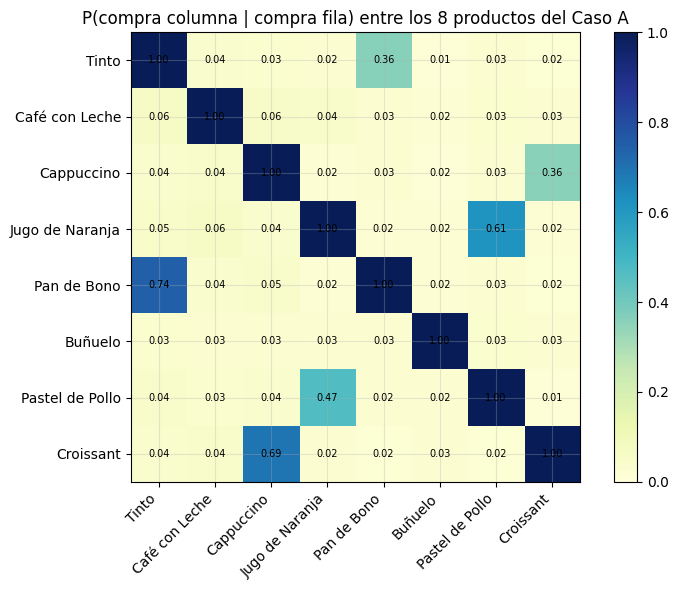

In [60]:
# ¿Qué productos de nuestro Caso A se compran juntos? P(compra columna | compra fila), vía el cruce por nombre
if det is not None and CROSSWALK:
    inv_cw2 = {v: k for k, v in CROSSWALK.items()}
    nombres_a = catalogo.set_index("id_producto")["nombre"]
    sel = det[det["id_producto"].isin(CROSSWALK.values())]
    pres = (sel.assign(v=1).pivot_table(index="id_ticket", columns="id_producto", values="v", aggfunc="max", fill_value=0))
    co = pres.T.dot(pres)
    prob = co.div(np.diag(co), axis=0)
    prob.index = prob.columns = [nombres_a[inv_cw2[c]] for c in prob.columns]
    fig, ax = plt.subplots(figsize=(8, 6)); im = ax.imshow(prob.values, cmap="YlGnBu", vmin=0)
    ax.set_xticks(range(len(prob))); ax.set_xticklabels(prob.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(prob))); ax.set_yticklabels(prob.index)
    for i in range(len(prob)):
        for j in range(len(prob)): ax.text(j, i, f"{prob.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title("P(compra columna | compra fila) entre los 8 productos del Caso A"); plt.colorbar(im); plt.tight_layout(); plt.show()

Líneas de ticket con producto clasificado: 18,376 de 18,376

=== CATEGORÍA (Bebidas / Alimentos): P(el ticket tiene el grupo de la COLUMNA | tiene el grupo de la FILA) ===


,Alimentos,Bebidas
Alimentos,1.00,0.65
Bebidas,0.64,1.00


Lift = P(col | fila) / P(col): > 1 se compran juntos más de lo normal; ≈ 1 independientes; < 1 se evitan:


,Alimentos,Bebidas
Alimentos,1.36,0.88
Bebidas,0.88,1.35


Probabilidad base (todos los tickets):


categ,Alimentos,Bebidas
P(ticket tiene el grupo),0.74,0.74


... (2 outputs left out)

Lift = P(col | fila) / P(col): > 1 se compran juntos más de lo normal; ≈ 1 independientes; < 1 se evitan:


,Calientes,Frías,Panadería Dulce,Panadería Sal,Sandwiches
Calientes,2.06,0.50,0.97,0.86,0.70
Frías,0.50,2.96,0.57,1.16,0.72
Panadería Dulce,0.97,0.57,3.91,0.58,0.68
Panadería Sal,0.86,1.16,0.58,1.93,0.74
Sandwiches,0.70,0.72,0.68,0.74,12.80


Probabilidad base (todos los tickets):


subcat,Calientes,Frías,Panadería Dulce,Panadería Sal,Sandwiches
P(ticket tiene el grupo),0.49,0.34,0.26,0.52,0.08


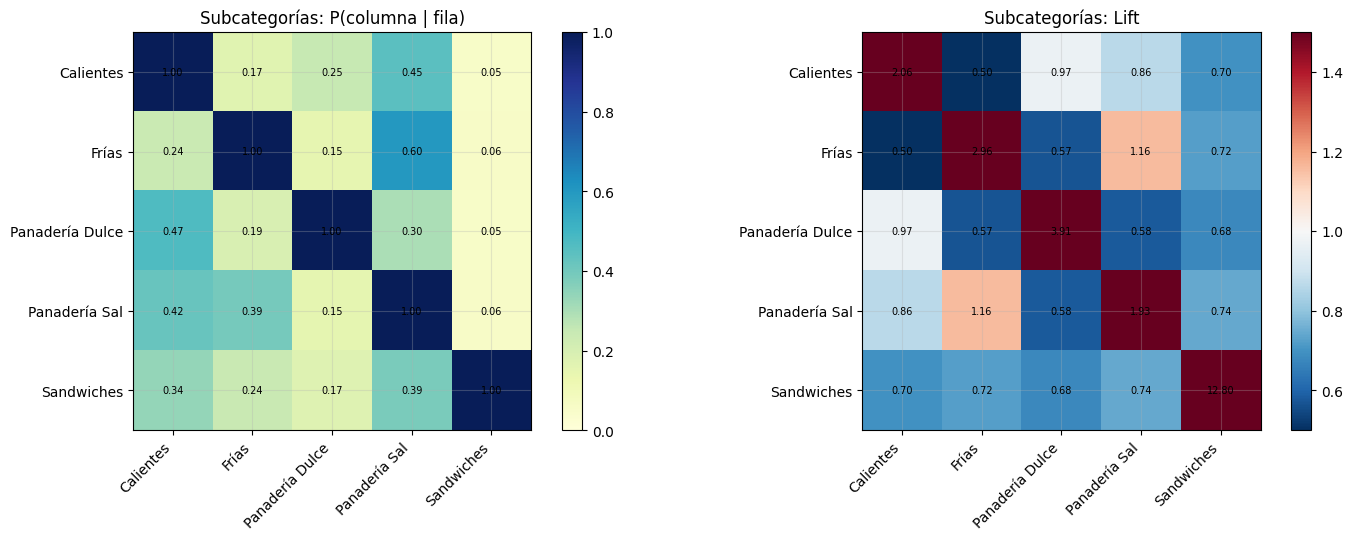


Desde cada producto de nuestro Caso A: ¿qué grupos acompañan?


,subcategoría,tickets,P(lleva Alimentos),P(lleva Bebidas),P(lleva Calientes),P(lleva Frías),P(lleva Panadería Dulce),P(lleva Panadería Sal),P(lleva Sandwiches)
producto (Caso A),,,,,,,,,
Tinto,Calientes,1419,0.58,0.27,0.15,0.14,0.14,0.48,0.07
Café con Leche,Calientes,938,0.75,0.35,0.19,0.18,0.17,0.67,0.05
Cappuccino,Calientes,1247,0.79,0.29,0.16,0.15,0.38,0.50,0.06
Pan de Bono,Panadería Sal,691,0.34,0.84,0.80,0.13,0.14,0.19,0.06
Buñuelo,Panadería Sal,636,0.36,0.82,0.17,0.76,0.16,0.19,0.05
Croissant,Panadería Sal,645,0.33,0.83,0.77,0.17,0.13,0.18,0.06
Pastel de Pollo,Panadería Sal,896,0.35,0.67,0.21,0.55,0.13,0.20,0.05
Jugo de Naranja,Frías,684,0.80,0.37,0.24,0.16,0.14,0.75,0.05


In [61]:
# VENTA CRUZADA POR GRUPOS (categoría y subcategoría del catálogo de la carpeta 02)
if det is None or catalogo_b is None:
    print("Faltan detalle_tickets o el catálogo de la carpeta 02.")
else:
    sub_map = catalogo_b.set_index("id_producto")["subcategoria"]; cat_map = catalogo_b.set_index("id_producto")["categoria"]
    d2 = det.assign(subcat=det["id_producto"].map(sub_map), categ=det["id_producto"].map(cat_map)).dropna(subset=["subcat"])
    print(f"Líneas de ticket con producto clasificado: {len(d2):,} de {len(det):,}")

    def matrices(col):
        pres_ = pd.crosstab(d2["id_ticket"], d2[col]) > 0
        pm_ = pd.DataFrame({B: {A: (pres_[A] & pres_[B]).sum() / pres_[A].sum() for A in pres_.columns} for B in pres_.columns})
        return pres_, pm_, pm_.div(pres_.mean(), axis=1)

    for col, etq in [("categ", "CATEGORÍA (Bebidas / Alimentos)"), ("subcat", "SUBCATEGORÍA")]:
        pres_, pm_, lift_ = matrices(col)
        print(f"\n=== {etq}: P(el ticket tiene el grupo de la COLUMNA | tiene el grupo de la FILA) ===")
        display(pm_.round(2))
        print(f"Lift = P(col | fila) / P(col): > 1 se compran juntos más de lo normal; ≈ 1 independientes; < 1 se evitan:")
        display(lift_.round(2))
        print("Probabilidad base (todos los tickets):"); display(pres_.mean().round(2).to_frame("P(ticket tiene el grupo)").T)

    pres_s, pm_s, lift_s = matrices("subcat")
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, m_, tit, vm in [(axes[0], pm_s, "P(columna | fila)", None), (axes[1], lift_s, "Lift", 1.0)]:
        im = ax.imshow(m_.values, cmap="YlGnBu" if vm is None else "RdBu_r", vmin=0 if vm is None else 0.5, vmax=None if vm is None else 1.5)
        ax.set_xticks(range(len(m_))); ax.set_xticklabels(m_.columns, rotation=45, ha="right"); ax.set_yticks(range(len(m_))); ax.set_yticklabels(m_.index)
        for i in range(len(m_)):
            for j in range(len(m_)): ax.text(j, i, f"{m_.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
        ax.set_title(f"Subcategorías: {tit}"); plt.colorbar(im, ax=ax)
    plt.tight_layout(); plt.show()

    # Desde cada producto del Caso A: ¿qué grupos acompañan?  (excluyendo la propia línea del producto)
    filas = []
    for pid, pid_t in CROSSWALK.items():
        tk = d2.loc[d2["id_producto"] == pid_t, "id_ticket"].unique()
        if len(tk) == 0: continue
        otras = d2[d2["id_ticket"].isin(tk) & (d2["id_producto"] != pid_t)]
        f_ = {"producto (Caso A)": catalogo.set_index("id_producto").loc[pid, "nombre"], "subcategoría": sub_map.get(pid_t), "tickets": len(tk)}
        for col, pref in [("categ", "P(lleva ")]:
            for gname in sorted(d2[col].unique()): f_[f"{pref}{gname})"] = otras.loc[otras[col] == gname, "id_ticket"].nunique() / len(tk)
        for gname in sorted(d2["subcat"].unique()): f_[f"P(lleva {gname})"] = otras.loc[otras["subcat"] == gname, "id_ticket"].nunique() / len(tk)
        filas.append(f_)
    print("\nDesde cada producto de nuestro Caso A: ¿qué grupos acompañan?")
    display(pd.DataFrame(filas).set_index("producto (Caso A)").round(2))

### 🔎 Lectura — Venta cruzada (H9, cruce por nombre)
**1. Cifra general y por producto**
- En promedio, 76 % de las líneas de ticket vienen con algo más en la canasta. Ese resto vale ≈4,551 por línea y, al margen promedio (≈64 %), ≈2,834 de margen por unidad: la cifra general que ya usábamos. Los tickets traen 1.84 líneas y 1.89 unidades.
- Por producto (margen cruzado propio, por unidad): Tinto 1,961; Café con Leche 2,952; Cappuccino 3,268; Pan de Bono 2,879; Buñuelo 3,335; Croissant 3,749; Pastel de Pollo 3,235; Jugo 3,358. Cada uno tiene entre 636 y 1,419 tickets, así que las cifras son confiables. El Tinto, el producto de más volumen, es el que menos arrastra; el Croissant, el que más.

**2. Importa poco para la decisión**
- Con α = 100 % y β = 50 %, el ratio crítico cambia como máximo 0.02 entre la cifra general y la propia (Tinto 0.79 → 0.77; Buñuelo 0.79 → 0.80; Pastel 0.69 → 0.70). `MODO = "general"` es una base razonable.
- El efecto de β es moderado: para el Tinto con α = 50 %, el ratio crítico va de 0.81 (β = 0) a 0.92 (β = 100 %). En el escenario central (α = 50 %, β = 25 %) el pedido queda ≈11 % sobre la demanda media; con α = 100 % y β = 100 %, ≈10 %. Ambos están muy por debajo del ≈28 % del caso "solo almacenamiento". Una vez aceptado que sobrar cuesta, β mueve el pedido unos pocos puntos.

**3. Parejas concretas de productos**
- Pan de Bono → Tinto: 0.74. Quien compra Pan de Bono lleva Tinto el 74 % de las veces (la base del Tinto es ≈14 %, lift ≈ 5). A la inversa, quien compra Tinto lleva Pan de Bono solo el 36 %: la relación no es simétrica.
- Croissant → Cappuccino: 0.69 (a la inversa, 0.36). Pastel de Pollo ↔ Jugo de Naranja: 0.47 y 0.61. Son tres parejas muy marcadas (lift de 5 a 7); el resto de los pares está en ≈0.02–0.06, sin relación.
- Implicación: quedarse sin Pan de Bono, Croissant, Pastel o Jugo pone en riesgo también la venta de su pareja; la inversa pesa menos. Es el argumento para un β algo más alto en esos cuatro productos que en Tinto, Café con Leche o Buñuelo.

**4. Por grupos (subcategorías)**
- Entre categorías (bebidas ↔ alimentos) el lift es 0.88 (probabilidad de llevar alimentos si se lleva bebida: 0.64, frente a la base de 0.74). No hay complementariedad a nivel de categoría; está en pares específicos.
- Bebidas calientes ↔ frías: lift 0.50. Son sustitutas: si falta una caliente, parte de la venta puede pasar a otra bebida, por eso β debe ser bajo para las calientes. Calientes ↔ panadería dulce: 0.97; calientes → panadería salada: 0.86.
- La única pareja de grupos con lift mayor que 1.1 es frías → panadería salada (1.16), consistente con Jugo ↔ Pastel de Pollo.
- Las diagonales (lift de 2 a 13) no se interpretan: es el grupo contra sí mismo, y el 12.8 de sandwiches se debe a que son solo 2 productos y el 8 % de los tickets.
- Desde cada producto: el Jugo lleva panadería salada en el 75 % de los casos; Café con Leche, 67 %; Tinto, 48 %. Pan de Bono, Buñuelo, Croissant y Pastel llevan bebida en el 67–84 %.

**5. Decisión para el modelo**
- β es un supuesto, ahora con respaldo: escenario central de 25 %, más alto para los productos con pareja marcada (Pan de Bono, Croissant, Pastel, Jugo) y más bajo para Tinto y las bebidas calientes (sustitutas entre sí). Se reporta la sensibilidad (0, 25, 50 y 100 %).
- Esta venta cruzada sale de `tickets`, que es otro universo de datos. En las ventas del Caso A no hay co-movimiento entre productos (correlaciones ≈ 0 en H5): las parejas existen en los tickets pero no se ven en la demanda. Se usan solo para valorar el costo de quedarse corto, no como variable del pronóstico.

## H10 · El producto perecedero cambia el costo de sobrar (α)
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** Lo que sobra se pierde en parte. ¿Qué fracción del costo unitario se pierde (α) según la vida útil de cada producto, y cuánto cambia el pedido?

**Cómo se prueba.** No hay dato de merma, así que α se estima a partir de la vida útil publicada en fuentes públicas, y se calcula el ratio crítico resultante por producto.

#### Vida útil y α por producto
α es la fracción del costo unitario que se pierde si el producto sobra, y debería salir de la vida útil. Las fuentes son blogs de consumo; para la presentación conviene respaldarlas con la guía USDA FoodKeeper o la norma sanitaria colombiana. Los productos de masa con queso se aproximan con su análogo más cercano.

| Producto | Referencia de vida útil | Fuente | α por defecto (supuesto) |
|---|---|---|---|
| Jugo de Naranja (natural) | 2–3 días en nevera; ≈2 h a temperatura ambiente | [Goodnature](https://www.goodnature.com/juice-archives/does-orange-juice-go-bad-how-long-does-it-last) | 1.0 |
| Croissant | 1–2 días ambiente; hasta ≈5 en nevera | [Texas Real Food](https://discover.texasrealfood.com/food-shelf-life/croissants) | 1.0 |
| Pastel de Pollo | 3–5 días en nevera (referencia: pastel de pollo horneado) | [Texas Real Food](https://discover.texasrealfood.com/food-shelf-life/how-long-does-chicken-pot-pie-last) | 0.5 |
| Pan de Bono (análogo: pão de queijo) | 1 día ambiente; 7 días en nevera | [Tasting Table](https://tastingtable.com/1833118/how-to-store-brazilian-cheese-bread) | 0.75 |
| Buñuelo | mejor caliente; sobrante "un par de días" en nevera | [My Colombian Recipes](https://www.mycolombianrecipes.com/bunuelos-colombianos-colombian-bunuelos/) | 1.0 |
| Tinto, Café con Leche, Cappuccino | se preparan al momento: se pierden los insumos, no la bebida | supuesto | 0.25 |

Son supuestos editables, no datos de la empresa; si el evaluador aclara cómo opera el inventario, se reemplazan.

**Importante.** Este α es una estimación a partir de la vida útil, no una merma medida. Lo correcto es calcularlo con la merma real del ciclo completo (compra o producción, venta y descarte, por producto y tienda), incluyendo si lo sobrante se vende con descuento o se mueve a otra tienda. Como α mueve el pedido hasta ≈22 % (H13), es el segundo dato que conviene conseguir.

In [62]:
# Ratio crítico con α por producto (vida útil) y β central. Requiere la tabla `vc` de la sección 7.5.
ALFA_PROD = {"PROD_001": 0.25, "PROD_002": 0.25, "PROD_003": 0.25, "PROD_004": 0.75,
             "PROD_005": 1.0, "PROD_006": 1.0, "PROD_007": 0.5, "PROD_008": 1.0}
BETA_CENTRAL = 0.25
if "vc" not in globals():
    print("Ejecuta antes la sección 7.5 (tabla `vc`).")
else:
    v2 = vc.copy()
    v2["alfa"] = v2["id_producto"].map(ALFA_PROD)
    xc = v2["margen_cruzado_usado"] if "margen_cruzado_usado" in v2 else 0
    v2["Cu"] = v2["margen_unit"] + BETA_CENTRAL * xc
    v2["Co"] = v2["costo_almacenamiento_semanal"] + v2["alfa"] * v2["costo_unitario"]
    v2["ratio_critico"] = v2["Cu"] / (v2["Cu"] + v2["Co"])
    from scipy.stats import norm
    v2["pedido_sobre_media_%"] = (norm.ppf(v2["ratio_critico"]) * 0.12 * 100).round(1)       # CV semanal ≈ 0.12 (orden de magnitud)
    display(v2[["nombre", "alfa", "Cu", "Co", "ratio_critico", "pedido_sobre_media_%"]].round(2).set_index("nombre"))

,alfa,Cu,Co,ratio_critico,pedido_sobre_media_%
nombre,,,,,
Tinto,0.25,"2,408.47",210.00,0.92,16.80
Café con Leche,0.25,"3,008.47",315.00,0.91,15.70
Cappuccino,0.25,"3,708.47",390.00,0.90,15.70
Pan de Bono,0.75,"2,508.47",770.00,0.77,8.70
Buñuelo,1.00,"2,408.47",820.00,0.75,7.90
Croissant,1.00,"3,008.47","1,225.00",0.71,6.70
Pastel de Pollo,0.50,"2,708.47",780.00,0.78,9.10
Jugo de Naranja,1.00,"3,708.47","2,050.00",0.64,4.40


### 🔎 Lectura — Pedido con α por producto
- Con los supuestos de vida útil, el cuantil a pedir va de 0.64 (Jugo de Naranja) a 0.92 (Tinto), es decir, de +4.4 % a +16.8 % sobre la demanda media (con CV semanal ≈ 0.12).
- Esa diferencia entre productos viene casi por completo del α supuesto, no de los datos. Las bebidas calientes tienen α = 0.25 (solo se pierden insumos), por eso se pide más; Jugo, Croissant y Buñuelo tienen α = 1.0 y se piden más cerca de la media.
- La venta cruzada general es ≈2,834 por unidad (Cu del Tinto = 1,700 + 0.25 × 2,834). Con el cruce por nombre (H9), el Tinto arrastra menos (1,961) y los demás más (2,879–3,749); las bebidas calientes son sustitutas entre sí (lift 0.50 con las frías), lo que justifica un β bajo para ellas.

La tabla es un escenario, no un resultado. α es lo que más mueve la decisión y lo que hay que validar con el negocio.

## H11 · Hay tiendas con clientes más fieles
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** ¿Hay tiendas con más clientes recurrentes o de segmento premium?

**Cómo se prueba.** Con `tickets` y `clientes_loyalty` se mide, por tienda, cuántos tickets tiene cada cliente y qué mezcla de segmentos aparece. Salvedad: los tickets usan códigos `TOSTAO_nn` y no se pudo confirmar que equivalgan a `STORE_nn`.

#### Prueba: tickets y clientes fieles

In [63]:
if tkt is None:
    print("Sin tickets.")
else:
    print(f"Tickets: {len(tkt):,} | fechas {tkt['fecha'].min().date()} -> {tkt['fecha'].max().date()} | códigos de tienda: {sorted(tkt['id_tienda'].unique())[:3]}...")
    # Hipótesis (NO verificada): TOSTAO_xx == STORE_xx. Solo validamos que los números existan en el maestro de tiendas.
    num = tkt["id_tienda"].str.extract(r"(\d+)")[0].str.zfill(2)
    tkt = tkt.assign(tienda_sup="STORE_" + num)
    print(f"Si TOSTAO_nn == STORE_nn, cruzan {tkt['tienda_sup'].isin(sup_t).mean()*100:.0f} % de los tickets (hipótesis, no confirmada).")
    por_cli = tkt.groupby("id_cliente").size()
    print(f"Clientes únicos: {por_cli.size:,} | tickets por cliente (mediana): {por_cli.median():.0f} | % clientes con >=2 compras: {100*(por_cli>=2).mean():.0f} %")
    if loy is not None:
        tl = tkt.merge(loy, on="id_cliente", how="left")
        print("Mix de segmentos por tienda (% de tickets):")
        mixseg = pd.crosstab(tl["id_tienda"], tl["segmento"].fillna("Sin dato"), normalize="index").mul(100).round(1)
        display(mixseg.sort_values(mixseg.columns[0], ascending=False).head(10))
        rec = tl.groupby("id_tienda").agg(tickets=("id_ticket", "count"), clientes=("id_cliente", "nunique"))
        rec["tickets_por_cliente"] = (rec["tickets"] / rec["clientes"]).round(2)
        print("Tiendas con clientes más recurrentes:"); display(rec.sort_values("tickets_por_cliente", ascending=False).head(5))
    if det is not None:
        cesta = det.groupby("id_ticket")["cantidad"].sum()
        print(f"Unidades por ticket (mediana): {cesta.median():.0f} | media: {cesta.mean():.2f}")

Tickets: 10,000 | fechas 2024-01-01 -> 2024-12-30 | códigos de tienda: ['TOSTAO_01', 'TOSTAO_02', 'TOSTAO_03']...
Si TOSTAO_nn == STORE_nn, cruzan 100 % de los tickets (hipótesis, no confirmada).
Clientes únicos: 2,455 | tickets por cliente (mediana): 4 | % clientes con >=2 compras: 92 %
Mix de segmentos por tienda (% de tickets):


segmento,Budget,Premium,Regular,Sin dato
id_tienda,,,,
TOSTAO_17,15.50,8.60,20.30,55.60
TOSTAO_16,14.90,8.00,18.00,59.10
TOSTAO_03,14.70,8.90,20.40,56.00
TOSTAO_05,14.10,6.60,19.90,59.30
TOSTAO_10,14.10,9.80,20.90,55.20
TOSTAO_12,14.00,7.20,22.60,56.20
TOSTAO_04,13.30,7.50,20.40,58.90
TOSTAO_02,12.90,7.40,19.50,60.20
TOSTAO_14,12.80,8.60,20.70,57.90


Tiendas con clientes más recurrentes:


,tickets,clientes,tickets_por_cliente
id_tienda,,,
TOSTAO_02,498,431,1.16
TOSTAO_05,482,422,1.14
TOSTAO_11,515,457,1.13
TOSTAO_03,529,468,1.13
TOSTAO_19,514,457,1.12


Unidades por ticket (mediana): 2 | media: 1.89


Esta prueba solo vale si `TOSTAO_nn` equivale a `STORE_nn` y los productos coinciden, y esa equivalencia es una hipótesis: los tickets cubren todo 2024 y tienen 35 productos, mientras que abastecimiento cubre 3 meses y 8 productos, lo que apunta a otro universo de datos. Por eso se usan como contexto (perfil del cliente) y no como variable del modelo.

### 🔎 Lectura — Clientes fieles: no hay tiendas con clientes más fieles
- Hay 10,000 tickets de 2,455 clientes, con mediana de 4 tickets por cliente y 92 % con dos o más compras. Los clientes sí repiten, pero repartidos entre tiendas: por tienda, cada cliente tiene solo 1.12–1.16 tickets, con diferencias mínimas. Los clientes no son "de una tienda".
- El mix de segmentos es poco confiable: entre 55 % y 60 % de los tickets de cada tienda son de clientes sin registro en `clientes_loyalty` (solo hay 1,000 clientes allí contra 2,455 en los tickets). El segmento premium oscila entre 6.6 % y 10.1 % sin patrón.
- La canasta tiene mediana de 2 unidades por ticket (media 1.89).

**Conclusión:** la idea de una tienda con más clientes fieles no se sostiene con estos datos, y el código `TOSTAO_nn` no se pudo confirmar contra `STORE_nn`. Se reporta como "explorado, sin diferencias".

## Bloque C — Prueba conjunta
<sup><a href="#Contenido">↑ Contenido</a></sup>

## H12 · Ninguna variable adicional mejora de forma consistente el pronóstico a una semana
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** Cuando las variables se ponen todas en el mismo modelo, ¿alguna mejora de forma consistente el pronóstico de la semana siguiente?

**Cómo se prueba.** Con una **ablación con backtest**:
- **Backtest:** se simula estar al final de una semana, pronosticar la siguiente con lo que se sabía entonces y comparar con lo que pasó. Se repite para las semanas 6 a 13 (origen móvil, *rolling origin*).
- **Ablación:** se usa el mismo modelo y solo se cambia el conjunto de variables (A: día, tienda y producto; B: más rezagos; C: más nivel reciente; D: calendario; E: atributos; F: nivel de tienda) para ver cuál baja el error.
- **Por qué:** H1 a H11 evalúan cada variable por separado. Una variable puede verse relacionada con las ventas y aun así no ayudar a pronosticar una semana nueva; esta es la prueba que decide qué entra al modelo.
- **WAPE** (error porcentual absoluto ponderado) = suma de |real − pronóstico| ÷ suma de lo vendido. Si se vendió 100, 50 y 150 y se pronosticó 110, 40 y 140, los errores suman 30 sobre 300: WAPE = 10 %. Pondera por volumen, así que los SKU pequeños no lo distorsionan.

#### Ablación con backtest: ¿qué variables mejoran el pronóstico a una semana?
Mismo modelo (gradient boosting con pérdida de Poisson), mismo origen móvil (pronosticar cada semana de la 6 a la 13 con lo anterior); solo cambia el conjunto de variables. Todas se arman sin mirar el futuro: rezagos de al menos 7 días y medias móviles calculadas hasta el domingo previo. Se compara contra dos referencias simples: el naive (el mismo día de la semana pasada) y la media de las últimas 4 semanas del mismo día.

,naive (lag 7),media 4 sem. mismo día,A: día + tienda + producto,B: + rezagos,C: + nivel reciente,D: + calendario,E: + atributos,F: + nivel de tienda
semana,,,,,,,,
6,0.36,0.28,0.26,0.26,0.26,0.26,0.26,0.26
7,0.34,0.27,0.26,0.26,0.26,0.26,0.26,0.26
8,0.33,0.28,0.26,0.26,0.26,0.26,0.26,0.26
9,0.34,0.26,0.26,0.26,0.26,0.26,0.26,0.26
10,0.34,0.27,0.27,0.27,0.26,0.26,0.26,0.27
11,0.34,0.28,0.28,0.27,0.26,0.26,0.26,0.27
12,0.34,0.28,0.28,0.27,0.26,0.26,0.26,0.26
13,0.34,0.28,0.28,0.27,0.26,0.26,0.26,0.26


WAPE promedio de las semanas 6-13 (menor es mejor):


,mean,std,mejora vs naive (%)
naive (lag 7),0.34,0.01,0.00
media 4 sem. mismo día,0.27,0.01,19.90
A: día + tienda + producto,0.27,0.01,21.60
B: + rezagos,0.27,0.01,22.20
C: + nivel reciente,0.26,0.00,23.70
D: + calendario,0.26,0.00,23.70
E: + atributos,0.26,0.00,23.70
F: + nivel de tienda,0.26,0.00,23.40


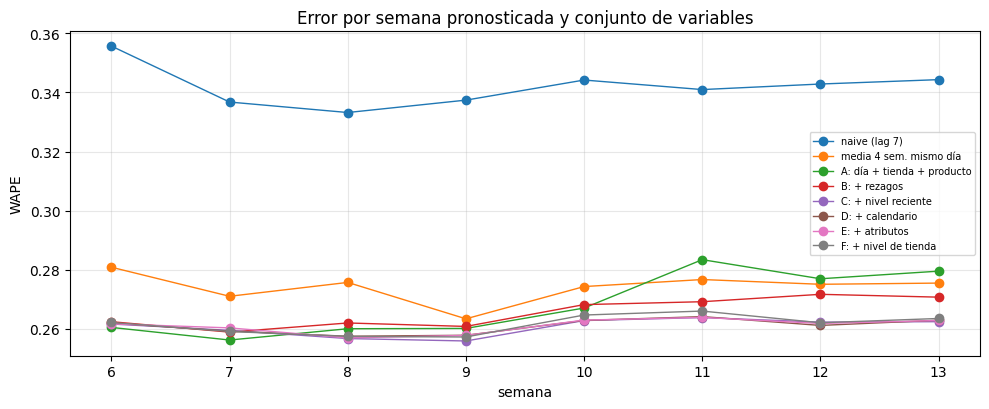

In [64]:
from sklearn.ensemble import HistGradientBoostingRegressor

F = (ventas[["fecha", "id_tienda", "id_producto", "unidades_vendidas"]]
     .merge(cal, on="fecha")
     .merge(tiendas[["id_tienda", "ciudad", "tamaño_m2"]], on="id_tienda")
     .merge(catalogo[["id_producto", "categoria", "precio_venta", "costo_unitario"]], on="id_producto")
     .sort_values(["id_tienda", "id_producto", "fecha"]).reset_index(drop=True))
F["margen"] = F["precio_venta"] - F["costo_unitario"]
F["es_bebida"] = (F["categoria"] == "Bebidas").astype(int)
F["tienda_cod"] = F["id_tienda"].astype("category").cat.codes
F["producto_cod"] = F["id_producto"].astype("category").cat.codes
F["ciudad_cod"] = F["ciudad"].astype("category").cat.codes
F["semana"] = (F["fecha"] - F["fecha"].min()).dt.days // 7 + 1

g = F.groupby(["id_tienda", "id_producto"])["unidades_vendidas"]
for L in (7, 14, 21, 28):
    F[f"lag_{L}"] = g.shift(L)
F["dow_mean4"] = F[["lag_7", "lag_14", "lag_21", "lag_28"]].mean(axis=1)
F["rm7_dia"] = g.transform(lambda s: s.rolling(7).mean())
F["rm28_dia"] = g.transform(lambda s: s.rolling(28, min_periods=14).mean())
# nivel "hasta el domingo previo al lunes de la semana de cada fila" (lo que se sabe al hacer el pedido)
F["fecha_asof"] = F["fecha"] - pd.to_timedelta(F["dow"] + 1, unit="D")
ref = F[["id_tienda", "id_producto", "fecha", "rm7_dia", "rm28_dia"]].rename(columns={"fecha": "fecha_asof", "rm7_dia": "rm7", "rm28_dia": "rm28"})
F = F.merge(ref, on=["id_tienda", "id_producto", "fecha_asof"], how="left")
# nivel de la tienda (todos los productos) de hace 7 días: efecto cruzado entre productos
tot = F.groupby(["id_tienda", "fecha"])["unidades_vendidas"].sum().rename("tienda_lag7").reset_index()
tot["fecha"] = tot["fecha"] + pd.Timedelta(days=7)
F = F.merge(tot, on=["id_tienda", "fecha"], how="left")

A = ["dow", "tienda_cod", "producto_cod"]
B = A + ["lag_7", "lag_14", "lag_21", "lag_28", "dow_mean4"]
C = B + ["rm7", "rm28"]
D = C + ["festivo", "semana_santa", "puente", "dia_mes", "ventana_pago"]
E = D + ["tamaño_m2", "ciudad_cod", "es_bebida", "precio_venta", "margen"]
Fx = E + ["tienda_lag7"]
CONJUNTOS = {"A: día + tienda + producto": A, "B: + rezagos": B, "C: + nivel reciente": C, "D: + calendario": D,
             "E: + atributos": E, "F: + nivel de tienda": Fx}
CATEG = {"dow", "tienda_cod", "producto_cod", "ciudad_cod"}

def wape(y, p): return float(np.abs(y - p).sum() / y.sum())
res = []
for w in range(6, int(F["semana"].max()) + 1):
    tr_, te_ = F[F["semana"] < w], F[F["semana"] == w]
    fila = {"semana": w, "naive (lag 7)": wape(te_["unidades_vendidas"].values, te_["lag_7"].fillna(te_["unidades_vendidas"].mean()).values),
            "media 4 sem. mismo día": wape(te_["unidades_vendidas"].values, te_["dow_mean4"].fillna(te_["unidades_vendidas"].mean()).values)}
    for nombre, cols in CONJUNTOS.items():
        m = HistGradientBoostingRegressor(loss="poisson", max_iter=200, learning_rate=0.05, max_depth=4, min_samples_leaf=20,
                                          categorical_features=[c in CATEG for c in cols], random_state=0)
        m.fit(tr_[cols].astype(float), tr_["unidades_vendidas"])
        fila[nombre] = wape(te_["unidades_vendidas"].values, np.clip(m.predict(te_[cols].astype(float)), 0, None))
    res.append(fila)
res = pd.DataFrame(res).set_index("semana")
display(res.round(3))
resumen = res.agg(["mean", "std"]).T.round(3)
resumen["mejora vs naive (%)"] = ((resumen.loc["naive (lag 7)", "mean"] - resumen["mean"]) / resumen.loc["naive (lag 7)", "mean"] * 100).round(1)
print("WAPE promedio de las semanas 6-13 (menor es mejor):"); display(resumen)
fig, ax = plt.subplots(figsize=(10, 4.2))
res.plot(ax=ax, marker="o", lw=1); ax.set_ylabel("WAPE"); ax.set_title("Error por semana pronosticada y conjunto de variables"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Regla de decisión.** Una variable (o grupo) entra al modelo final si baja el WAPE promedio de forma consistente (en la mayoría de las semanas, no solo en promedio) y por un margen mayor que la desviación entre semanas. Mejoras de milésimas son ruido. La semana 13 es la de Semana Santa: si el calendario (D) la mejorara, sería evidencia directa de que importa. Con solo 8 semanas de prueba se reporta siempre la desviación entre semanas.

### 🔎 Lectura — Ablación: un modelo simple ya queda cerca del mejor posible
| Modelo | WAPE medio (semanas 6–13) | Mejora vs naive |
|---|---|---|
| Naive (mismo día, semana pasada) | 0.34 | — |
| Media 4 semanas del mismo día | 0.27 | 19.9 % |
| A: día + tienda + producto | 0.27 | 21.6 % |
| B: + rezagos | 0.27 | 22.2 % |
| C: + nivel reciente | **0.26** | 23.7 % |
| D: + calendario | 0.26 | 23.7 % |
| E: + atributos | 0.26 | 23.7 % |
| F: + nivel de tienda | 0.26 | 23.4 % |

- **El salto grande es dejar de usar un solo dato.** El naive usa una sola observación (la de hace 7 días), que arrastra todo su ruido; promediar baja el error de 0.34 a 0.27. Es la mejora más importante.
- **Lo demás aporta ≈0.01 de WAPE.** Los rezagos y el nivel reciente (B y C) ayudan un poco; calendario, atributos y nivel de tienda (D, E, F) no cambian nada (F empeora marginalmente). Coincide con las pruebas anteriores.
- **La semana 13 (Semana Santa) tiene el mismo error (0.26) que las demás**, otra evidencia de que el calendario no importa aquí.
- **Piso de error.** Con ruido diario de CV residual ≈ 0.31, el WAPE mínimo esperable es ≈ 0.8 × 0.31 ≈ 0.25 (suponiendo ruido aproximadamente normal). Estamos en 0.26, muy cerca del límite.
- **Entre semanas** la desviación es de 0.00–0.01: estable, aunque son solo 8 semanas de prueba.

**Decisión de variables.** Entran: día de la semana, tienda, producto, rezagos (7/14/21/28), media del mismo día de las últimas 4 semanas y medias móviles de 7 y 28 días. Se descartan: calendario, ventana de pago, atributos, nivel de tienda, clima, promociones y `trend_type`.

**Qué implica para la prueba.** El valor no está en bajar el WAPE: un baseline fuerte queda a ≈4 % del mejor modelo. Está en (1) cuantificar la incertidumbre con cuantiles calibrados y (2) decidir cuánto pedir con el costo asimétrico. En el modelado se compara también un modelo estadístico simple (perfil por día × nivel del SKU, con distribución de conteos) contra LightGBM, porque la parsimonia también cuenta al elegir.

## Bloque D — Parámetros operativos
<sup><a href="#Contenido">↑ Contenido</a></sup>
## H13 · Los parámetros que no vienen en los datos (lead time, MOQ, capacidad, stock en tránsito) cambian cuánto hay que pedir
<sup><a href="#Contenido">↑ Contenido</a></sup>
**Pregunta.** El lead time, el mínimo de pedido, la capacidad y lo que está en tránsito no vienen en los datos, pero en la vida real mueven el pedido. ¿Cuánto? No se asumen en cero: se parametrizan.

**Cómo se prueba.** Con la clase `ParametrosPedido` se calcula el pedido de los 160 SKU-tienda para la semana del 1 al 7 de abril, moviendo un parámetro a la vez respecto del valor base. La demanda del horizonte `L + R` días se arma con el nivel reciente de cada SKU-tienda (últimas 4 semanas), el perfil semanal común (H3) y el ruido diario medido (CV residual 0.31, independiente entre días).

**Cómo se calcula el pedido.**
1. Horizonte a cubrir: `L + R` días desde el lunes 1-abr (lo que llega con el pedido solo se vende después de `L`).
2. Cuantil objetivo: `τ = Cu / (Cu + Co)` con `Cu = margen + β × margen cruzado` y `Co = almacenamiento + α × costo`, acotado entre `τ_min` y `τ_max`.
3. Pedido bruto = cuantil `τ` de la demanda del horizonte − stock − en tránsito (nunca negativo).
4. MOQ y empaque: si el bruto es positivo, se sube al mínimo y se redondea hacia arriba. Si hay capacidad, se reduce de forma proporcional (aproximación; el óptimo repartiría por valor marginal).
5. Ventas perdidas inevitables: durante los `L` días de espera, el stock actual tiene que cubrir la venta; lo que falte se pierde sin importar cuánto se pida. Se mide aparte porque el pedido no lo corrige.

Demanda media semanal total estimada (nivel reciente): 14,871 u | stock actual total: 3,367 u


,pedido_total_u,venta_perdida_inevitable_u,SKU con piso MOQ,SKU sin pedido,cambio_vs_base_%
escenario,,,,,
"Base (L=1, R=7, sin MOQ ni capacidad)","14,916.00",375.30,0,4,0.00
Lead time 0,"13,101.00",0.00,0,4,-12.20
Lead time 2,"16,724.00","1,278.70",0,3,12.10
Lead time 3,"18,502.00","2,568.70",0,3,24.00
Lead time 7,"28,515.00","11,582.00",0,0,91.20
Revisión cada 3 días (R=3),"4,928.00",375.30,0,23,-67.00
En tránsito: 1 día de venta,"12,804.00",0.00,0,4,-14.20
En tránsito: 2 días de venta,"10,717.00",0.00,2,7,-28.20
MOQ y empaque de 6,"15,294.00",375.30,1,4,2.50


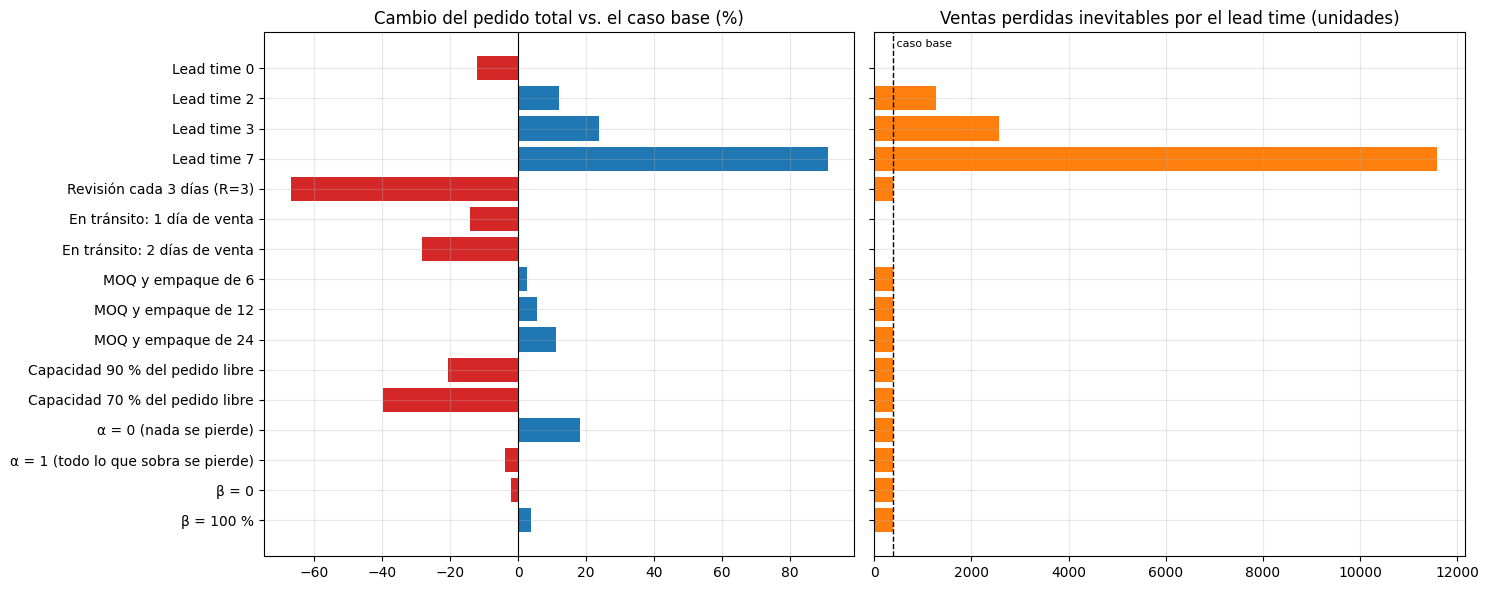

In [65]:
from dataclasses import dataclass, field
from typing import Dict, Optional
from scipy.stats import norm


@dataclass
class ParametrosPedido:
    """Parámetros del problema de pedido. Los valores base son supuestos declarados, no datos.

    Attributes:
        lead_time_dias: días entre hacer el pedido y recibirlo.
        revision_dias: días que cubre cada pedido (cada cuánto se pide).
        en_transito_dias: unidades ya pedidas que no han llegado, en días de venta del SKU.
        moq: mínimo de unidades por pedido por SKU (si se pide algo).
        multiplo: múltiplo de empaque en que vende el proveedor.
        beta: fracción de la venta cruzada que se pierde si falta el producto.
        alfa: fracción del costo unitario que se pierde si sobra, por id_producto.
        tau_min, tau_max: piso y techo del nivel de servicio (cuantil de pedido).
        capacidad_tienda: máximo de unidades (stock + pedido) por tienda; None = sin límite.
        cv_diario: variabilidad diaria propia del SKU (medida en el EDA).
    """
    lead_time_dias: int = 1
    revision_dias: int = 7
    en_transito_dias: float = 0.0
    moq: int = 1
    multiplo: int = 1
    beta: float = 0.25
    alfa: Dict[str, float] = field(default_factory=lambda: dict(ALFA_PROD))
    tau_min: float = 0.50
    tau_max: float = 0.99
    capacidad_tienda: Optional[float] = None
    cv_diario: float = 0.31


def perfil_semanal(ventas_df: pd.DataFrame) -> pd.Series:
    """Índice de venta por día de la semana (0 = lunes), con media 1."""
    m = ventas_df.groupby(ventas_df["fecha"].dt.dayofweek)["unidades_vendidas"].mean()
    return m / m.mean()


def nivel_reciente(ventas_df: pd.DataFrame, dias: int = 28) -> pd.DataFrame:
    """Venta media diaria por SKU-tienda en los últimos `dias` (4 semanas completas: el perfil semanal se promedia)."""
    corte = ventas_df["fecha"].max() - pd.Timedelta(days=dias - 1)
    r = ventas_df[ventas_df["fecha"] >= corte]
    return r.groupby(["id_tienda", "id_producto"])["unidades_vendidas"].mean().rename("nivel_dia").reset_index()


def demanda_horizonte(nivel_dia: np.ndarray, perfil: pd.Series, dias: int, dow_inicio: int, cv_diario: float):
    """Media y desviación de la demanda acumulada de `dias` días (ruido diario independiente)."""
    if dias <= 0:
        z = np.zeros(len(nivel_dia)); return z, z
    idx = [(dow_inicio + k) % 7 for k in range(dias)]
    mu_d = nivel_dia[:, None] * perfil.values[idx][None, :]
    return mu_d.sum(axis=1), cv_diario * np.sqrt((mu_d ** 2).sum(axis=1))


def calcular_pedido(ventas_df: pd.DataFrame, inventario_df: pd.DataFrame, econ: pd.DataFrame, p: ParametrosPedido) -> pd.DataFrame:
    """Pedido por SKU-tienda para la semana siguiente al último día de ventas, dado un conjunto de parámetros.

    `econ` trae por producto: margen_unit, costo_unitario, costo_almacenamiento_semanal, margen_cruzado_usado.
    """
    perfil = perfil_semanal(ventas_df)
    dow0 = int((ventas_df["fecha"].max() + pd.Timedelta(days=1)).dayofweek)
    d = (nivel_reciente(ventas_df).merge(inventario_df, on=["id_tienda", "id_producto"])
                                  .merge(econ[["id_producto", "nombre", "margen_unit", "costo_unitario",
                                               "costo_almacenamiento_semanal", "margen_cruzado_usado"]], on="id_producto"))
    cu = d["margen_unit"] + p.beta * d["margen_cruzado_usado"]
    co = d["costo_almacenamiento_semanal"] + d["id_producto"].map(p.alfa) * d["costo_unitario"]
    d["tau"] = (cu / (cu + co)).clip(p.tau_min, p.tau_max)
    mu, sd = demanda_horizonte(d["nivel_dia"].values, perfil, p.lead_time_dias + p.revision_dias, dow0, p.cv_diario)
    d["q_objetivo"] = np.maximum(mu + norm.ppf(d["tau"]) * sd, 0)
    d["en_transito"] = d["nivel_dia"] * p.en_transito_dias
    bruto = np.maximum(d["q_objetivo"] - d["stock_actual"] - d["en_transito"], 0)
    pedido = np.where(bruto > 0, np.maximum(np.ceil(bruto / p.multiplo) * p.multiplo, p.moq), 0.0)
    d["piso_moq_activo"] = (bruto > 0) & (pedido > bruto + 1e-9) & (pedido <= p.moq)
    if p.capacidad_tienda is not None:
        d["pedido"] = pedido
        ocupado = (d["stock_actual"] + d["en_transito"]).groupby(d["id_tienda"]).transform("sum")
        pedir = d["pedido"].groupby(d["id_tienda"]).transform("sum")
        factor = np.clip((p.capacidad_tienda - ocupado) / pedir.replace(0, np.nan), 0, 1).fillna(1)
        pedido = np.floor(pedido * factor / p.multiplo) * p.multiplo
    d["pedido"] = pedido
    mu_L, _ = demanda_horizonte(d["nivel_dia"].values, perfil, p.lead_time_dias, dow0, p.cv_diario)
    d["venta_perdida_inevitable"] = np.maximum(mu_L - d["stock_actual"] - d["en_transito"], 0)
    return d


if "vc" not in globals() or "ALFA_PROD" not in globals():
    print("Ejecuta antes H9 (tabla `vc`) y H10 (`ALFA_PROD`).")
else:
    base_p = ParametrosPedido()
    ped0 = calcular_pedido(ventas, inventario, vc, base_p)
    cap_ref = (ped0["stock_actual"] + ped0["pedido"]).groupby(ped0["id_tienda"]).sum().mean()
    escenarios = {
        "Base (L=1, R=7, sin MOQ ni capacidad)": base_p,
        "Lead time 0": ParametrosPedido(lead_time_dias=0),
        "Lead time 2": ParametrosPedido(lead_time_dias=2),
        "Lead time 3": ParametrosPedido(lead_time_dias=3),
        "Lead time 7": ParametrosPedido(lead_time_dias=7),
        "Revisión cada 3 días (R=3)": ParametrosPedido(revision_dias=3),
        "En tránsito: 1 día de venta": ParametrosPedido(en_transito_dias=1.0),
        "En tránsito: 2 días de venta": ParametrosPedido(en_transito_dias=2.0),
        "MOQ y empaque de 6": ParametrosPedido(moq=6, multiplo=6),
        "MOQ y empaque de 12": ParametrosPedido(moq=12, multiplo=12),
        "MOQ y empaque de 24": ParametrosPedido(moq=24, multiplo=24),
        "Capacidad 90 % del pedido libre": ParametrosPedido(capacidad_tienda=0.9 * cap_ref),
        "Capacidad 70 % del pedido libre": ParametrosPedido(capacidad_tienda=0.7 * cap_ref),
        "α = 0 (nada se pierde)": ParametrosPedido(alfa={k: 0.0 for k in ALFA_PROD}),
        "α = 1 (todo lo que sobra se pierde)": ParametrosPedido(alfa={k: 1.0 for k in ALFA_PROD}),
        "β = 0": ParametrosPedido(beta=0.0),
        "β = 100 %": ParametrosPedido(beta=1.0),
    }
    filas = []
    for nombre, p_ in escenarios.items():
        r = calcular_pedido(ventas, inventario, vc, p_)
        filas.append({"escenario": nombre, "pedido_total_u": r["pedido"].sum(), "venta_perdida_inevitable_u": r["venta_perdida_inevitable"].sum(),
                      "SKU con piso MOQ": int(r["piso_moq_activo"].sum()), "SKU sin pedido": int((r["pedido"] == 0).sum())})
    sens = pd.DataFrame(filas).set_index("escenario")
    sens["cambio_vs_base_%"] = (100 * (sens["pedido_total_u"] / sens.loc[sens.index[0], "pedido_total_u"] - 1)).round(1)
    print(f"Demanda media semanal total estimada (nivel reciente): {ped0['nivel_dia'].sum() * 7:,.0f} u | stock actual total: {inventario['stock_actual'].sum():,.0f} u")
    display(sens.round(1))

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    s_ = sens["cambio_vs_base_%"].iloc[1:]
    axes[0].barh(s_.index, s_.values, color=np.where(s_.values >= 0, "tab:blue", "tab:red")); axes[0].invert_yaxis(); axes[0].axvline(0, color="k", lw=0.8)
    axes[0].set_title("Cambio del pedido total vs. el caso base (%)")
    s2 = sens["venta_perdida_inevitable_u"].iloc[1:]
    axes[1].barh(s2.index, s2.values, color="tab:orange"); axes[1].invert_yaxis(); axes[1].set_yticklabels([])
    axes[1].axvline(sens["venta_perdida_inevitable_u"].iloc[0], color="k", ls="--", lw=1); axes[1].text(sens["venta_perdida_inevitable_u"].iloc[0], -0.7, " caso base", fontsize=8)
    axes[1].set_title("Ventas perdidas inevitables por el lead time (unidades)")
    plt.tight_layout(); plt.show()

### 🔎 Lectura — H13: parámetros operativos
La demanda semanal estimada es de 14,871 u y el stock actual de 3,367 u (23 %, ≈1.6 días de venta), así que el pedido sale casi todo del cuantil elegido y no del stock.
- **Lead time.** Cada día de espera suma un día de demanda al pedido (≈1,800 u; más en fin de semana). Eso no es sobrestock. La pérdida está en las ventas perdidas inevitables, porque el stock no alcanza hasta que llega el pedido:

| Lead time | Venta perdida (u/semana) | % de la demanda semanal |
|---|---|---|
| 0 días | 0 | 0 % |
| 1 día (base) | 375 | 2.5 % |
| 2 días | 1,279 | 8.6 % |
| 3 días | 2,569 | 17.3 % |
| 7 días | 11,582 | 78 % |

- **Stock en tránsito.** Ignorar un día de venta ya pedido lleva a pedir 2,100 u de más (14 %); con dos días, 28 %. Con un día en tránsito, las ventas perdidas inevitables bajan a ≈0.
- **α contra β.** α pesa unas cinco veces más: pasar de α = 0 a 1 mueve el pedido 3,289 u (22 %); de β = 0 a 100 %, 862 u (5.8 %).
- **MOQ y empaque.** El costo está en redondear hacia arriba (≈medio empaque por SKU): un empaque de 24 suma 11.3 % (+1,692 u). El piso del MOQ casi no actúa (1, 4 y 6 SKU de 160).
- **Capacidad.** Las cifras (−20.7 % y −39.7 %) no son una predicción: el tope de referencia es un promedio igual para todas las tiendas. Hay que pedir la capacidad real por tienda.
- **Revisión cada 3 días.** El pedido (−67 %) cubre 4 días y no 7, así que no es comparable con las demás filas.

**Orden para pedir datos:** lead time y órdenes en tránsito, luego merma real, luego capacidad y empaque; β es lo menos urgente.

Efecto de cada parámetro en unidades (denominador fijo: demanda semanal = 14,871 u)


,"Base original (L=1, β=25 %)",Lead time 0,Lead time 2,α = 0.5 en todos,α = 1 en todos,β = 0,β = 50 %,Ruido bajo (CV diario 0.20),Ruido alto (CV diario 0.45)
Lead time +1 día,"1,808.00","1,815.00","1,778.00","1,823.00","1,776.00","1,799.00","1,825.00","1,791.00","1,837.00"
Stock en tránsito 1 día,"-2,112.00","-2,097.00","-2,115.00","-2,107.00","-2,116.00","-2,110.00","-2,104.00","-2,106.00","-2,108.00"
Empaque y MOQ de 12,828.00,915.00,928.00,847.00,883.00,839.00,881.00,812.00,891.00
α: de 0 a 1 (oscilación),"-3,289.00","-3,145.00","-3,442.00","-3,289.00","-3,289.00","-3,521.00","-3,086.00","-2,128.00","-4,787.00"
β: de 0 a 100 % (oscilación),862.00,823.00,890.00,848.00,912.00,862.00,862.00,559.00,"1,255.00"



Mismo efecto como % de la demanda semanal (comparable entre casos base):


,"Base original (L=1, β=25 %)",Lead time 0,Lead time 2,α = 0.5 en todos,α = 1 en todos,β = 0,β = 50 %,Ruido bajo (CV diario 0.20),Ruido alto (CV diario 0.45)
Lead time +1 día,12.20,12.20,12.00,12.30,11.90,12.10,12.30,12.00,12.40
Stock en tránsito 1 día,-14.20,-14.10,-14.20,-14.20,-14.20,-14.20,-14.10,-14.20,-14.20
Empaque y MOQ de 12,5.60,6.20,6.20,5.70,5.90,5.60,5.90,5.50,6.00
α: de 0 a 1 (oscilación),-22.10,-21.10,-23.10,-22.10,-22.10,-23.70,-20.80,-14.30,-32.20
β: de 0 a 100 % (oscilación),5.80,5.50,6.00,5.70,6.10,5.80,5.80,3.80,8.40



Puesto de importancia (1 = el que más mueve el pedido) en cada caso base:


,"Base original (L=1, β=25 %)",Lead time 0,Lead time 2,α = 0.5 en todos,α = 1 en todos,β = 0,β = 50 %,Ruido bajo (CV diario 0.20),Ruido alto (CV diario 0.45)
Lead time +1 día,3,3,3,3,3,3,3,3,3
Stock en tránsito 1 día,2,2,2,2,2,2,2,2,2
Empaque y MOQ de 12,5,4,4,5,5,5,4,4,5
α: de 0 a 1 (oscilación),1,1,1,1,1,1,1,1,1
β: de 0 a 100 % (oscilación),4,5,5,4,4,4,5,5,4



Casos base con el MISMO orden que el original: 5 de 9
α pesa más que β en 9 de 9 casos base


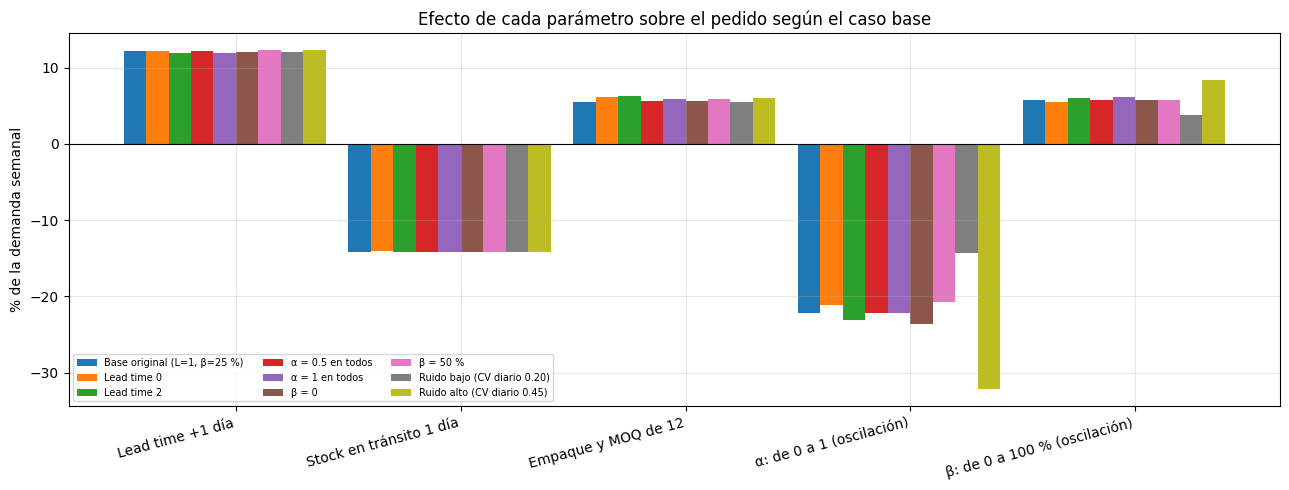

In [66]:
# ROBUSTEZ de H13: ¿el orden de importancia de los parámetros cambia si cambia el caso base?
from dataclasses import replace

def _pedido(p):
    return calcular_pedido(ventas, inventario, vc, p)["pedido"].sum()

def efectos_en_unidades(b):
    """Efecto en unidades sobre el pedido total de mover cada parámetro, partiendo del caso base `b`."""
    todos = lambda v: {k: v for k in ALFA_PROD}
    return {
        "Lead time +1 día":            _pedido(replace(b, lead_time_dias=b.lead_time_dias + 1)) - _pedido(b),
        "Stock en tránsito 1 día":     _pedido(replace(b, en_transito_dias=1.0)) - _pedido(b),
        "Empaque y MOQ de 12":         _pedido(replace(b, moq=12, multiplo=12)) - _pedido(b),
        "α: de 0 a 1 (oscilación)":    _pedido(replace(b, alfa=todos(1.0))) - _pedido(replace(b, alfa=todos(0.0))),
        "β: de 0 a 100 % (oscilación)": _pedido(replace(b, beta=1.0)) - _pedido(replace(b, beta=0.0)),
    }

if "vc" not in globals() or "ALFA_PROD" not in globals():
    print("Ejecuta antes H9, H10 y la celda de H13 (ParametrosPedido y calcular_pedido).")
else:
    bases = {
        "Base original (L=1, β=25 %)":   ParametrosPedido(),
        "Lead time 0":                   ParametrosPedido(lead_time_dias=0),
        "Lead time 2":                   ParametrosPedido(lead_time_dias=2),
        "α = 0.5 en todos":              ParametrosPedido(alfa={k: 0.5 for k in ALFA_PROD}),
        "α = 1 en todos":                ParametrosPedido(alfa={k: 1.0 for k in ALFA_PROD}),
        "β = 0":                         ParametrosPedido(beta=0.0),
        "β = 50 %":                      ParametrosPedido(beta=0.5),
        "Ruido bajo (CV diario 0.20)":   ParametrosPedido(cv_diario=0.20),
        "Ruido alto (CV diario 0.45)":   ParametrosPedido(cv_diario=0.45),
    }
    dem_sem = calcular_pedido(ventas, inventario, vc, ParametrosPedido())["nivel_dia"].sum() * 7   # denominador fijo
    ef = pd.DataFrame({nombre: efectos_en_unidades(b) for nombre, b in bases.items()})
    print(f"Efecto de cada parámetro en unidades (denominador fijo: demanda semanal = {dem_sem:,.0f} u)")
    display(ef.round(0))
    print("\nMismo efecto como % de la demanda semanal (comparable entre casos base):")
    display((100 * ef / dem_sem).round(1))
    rk = ef.abs().rank(ascending=False).astype(int)
    print("\nPuesto de importancia (1 = el que más mueve el pedido) en cada caso base:")
    display(rk)
    orden_ref = rk.iloc[:, 0].sort_values().index.tolist()
    igual = [c for c in rk.columns if rk[c].sort_values().index.tolist() == orden_ref]
    print(f"\nCasos base con el MISMO orden que el original: {len(igual)} de {len(rk.columns)}")
    n_a = int((ef.loc["α: de 0 a 1 (oscilación)"].abs() > ef.loc["β: de 0 a 100 % (oscilación)"].abs()).sum())
    print(f"α pesa más que β en {n_a} de {len(ef.columns)} casos base")

    fig, ax = plt.subplots(figsize=(13, 5)); w = 0.1; x = np.arange(len(ef.index))
    for k, c in enumerate(ef.columns):
        ax.bar(x + (k - len(ef.columns) / 2) * w, 100 * ef[c] / dem_sem, w, label=c)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(ef.index, rotation=15, ha="right")
    ax.set_ylabel("% de la demanda semanal"); ax.set_title("Efecto de cada parámetro sobre el pedido según el caso base")
    ax.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.show()

### 🔎 Lectura — Robustez: ¿cambia el orden si cambia el caso base?
- El orden de los tres primeros no cambia en ninguno de los 9 casos base: α (≈21–24 % de la demanda semanal), luego stock en tránsito (14.2 %), luego lead time +1 día (≈12 %). Empaque y β (≈6 %) intercambian puesto según el caso porque pesan casi lo mismo; por eso solo 5 de 9 casos repiten el orden completo.
- α pesa más que β en los 9 casos. Mover L, α o β en la base casi no cambia el tamaño de los efectos (α entre 20.8 % y 23.7 %).
- Lo que sí cambia es el ruido de la demanda: con CV diario de 0.20, α baja a 14.3 % (empata con el tránsito, 14.2 %); con 0.45 sube a 32.2 %. Lead time y tránsito no dependen del ruido; α y β sí.

Las prioridades son sólidas; los porcentajes exactos son ilustrativos y dependen del caso base y del ruido (el CV 0.31 sí está medido).

---
# PARTE 4 — Conclusiones del EDA y decisiones de modelado
<sup><a href="#Contenido">↑ Contenido</a></sup>

**Punto de partida.** Tenemos una foto del inventario, no su historia (stock, pedidos, mermas). Eso no permite evaluar la política actual: la correlación baja entre stock y venta (0.05) es compatible con una reposición bien o mal alineada. Lo que sí se puede hacer es decidir bien la semana del 1 al 7 de abril, con pronóstico y costo de cada tipo de error, y medir su valor en el backtest contra reglas simples.

### Qué descubrimos (con datos)
| # | Hallazgo | Evidencia | Implicación |
|---|---|---|---|
| 1 | Datos limpios y completos | 14,560 filas, sin nulos/duplicados, llaves cruzan | Sin imputación; pasar a modelar |
| 2 | **El patrón semanal domina**: Vie–Dom ≈ +50 % vs Lun–Jue, igual en todos los productos y tiendas | índice semanal 0.77–0.90 vs 1.19–1.30; día de la semana explica R² = 0.25 | Perfil semanal común; la semana a pronosticar (desde lun 1-abr) es completa |
| 3 | Nivel global plano (+3.5 % en 13 sem), pero **39 % de los SKU tienen tendencia propia** (t > 2 en valor absoluto); 35 suben y 28 bajan | t-stat con día de la semana controlado | Usar el nivel reciente por SKU (medias móviles); aporta poco pero es positivo |
| 4 | Las etiquetas `ground_truth_trends` **no predicen la dirección** | `down`: 10 bajan / 11 suben; `random` tiene menos tendencia (19 % vs ≈40–50 %) | No usarlas como variable; reportarlo |
| 5 | Demanda *Smooth*; sin demanda censurada | ADI≈1; 0 SKU con rachas de ceros | Modelo de cuantiles estándar; sin Croston |
| 6 | **Ruido diario de cada SKU-tienda: CV residual ≈ 0.31 diario, ≈ 0.12 semanal** | residuo sin autocorrelación, sin choques comunes, productos no correlacionados | Es un **piso de error**: ninguna variable lo reduce |
| 7 | Picos: 56 de 57 hacia arriba, **no explicados por promociones** | 4 % en promo vs 5.5 % base (cruce por nombre) | Se mantienen; se cubren con cuantiles altos |
| 8 | **Foto de stock baja y dispersa; no concluyente sobre la política actual** | ρ=0.05 con la venta; cobertura mediana 1.4 d (0–15); 96.9 % < 1 semana | Casi todo hay que pedirlo; stock solo entra en el paso final |
| 9 | **El supuesto de merma (α) es la palanca principal** | ratio crítico 0.99 (solo almacén) → 0.57–0.68 (se pierde); pedido +28 % → +5.6 % | Declarar α y mostrar sensibilidad |
| 10 | **La venta cruzada es palanca secundaria; hay parejas concretas y las bebidas calientes son sustitutas** | margen cruzado ≈2,834 (general), 1,961 (Tinto) a 3,749 (Croissant); Pan de Bono→Tinto 0.74, Croissant→Cappuccino 0.69, Pastel↔Jugo 0.47/0.61; calientes↔frías lift 0.50; ratio crítico general vs propio ≤ 0.02 | β como supuesto: central 25 %, más alto en Pan de Bono/Croissant/Pastel/Jugo, más bajo en Tinto y calientes; usar la cifra general como base |
| 11 | Escala (m²) explica las tiendas, no el mix ni el precio | r(m², ingreso)=0.97; precio prom. ±2 % | Usar tienda y producto; no segmentar por "premium" |
| 12 | Valor concentrado | top 5 tiendas 32.6 %; Jugo 20.7 % del margen; 97 SKU "A" | WAPE ponderado por margen; priorizar SKU A |
| 13 | **Variables externas y de calendario sin efecto** | clima ±2 %; tráfico/competencia ρ≈0; promos 1.01 / 1.01 / 0.94 (por nombre); festivos y Semana Santa dentro del ruido; ventana de pago p=0.37 | No entran al modelo |
| 14 | Las tablas de los casos B y C **usan otra numeración de productos** y otros códigos de tienda | por código solo 3 de 8 precios coinciden; **por nombre, los 8 coinciden**; transacciones sin patrón Vie–Dom; escala distinta | Cruzar por nombre (catálogo de la carpeta 02); `transacciones_resumen` y `tickets` solo como contexto |
| 15 | **Un baseline fuerte ya está cerca del piso** | media 4 sem. del mismo día: WAPE 0.27; mejor modelo: 0.26; piso ≈ 0.25 | El valor está en los **cuantiles y la decisión**, no en bajar el WAPE |
| 16 | **Los parámetros operativos mueven el pedido casi tanto como la merma** | α ≈ 22 %, stock en tránsito 14 % por día, lead time 12 % por día, β y empaque ≈ 6 %; ventas perdidas inevitables 2.5 % (L=1) a 17 % (L=3); orden estable en 9 casos base | Parametrizar y pedir los datos: tránsito y lead time, merma real, capacidad y empaque |

### Decisiones de modelado
1. **Variables:** día de la semana, tienda, producto, rezagos (7/14/21/28), media del mismo día de 4 semanas y medias móviles de 7 y 28 días. **Sin** calendario, ventana de pago, atributos de tienda/producto adicionales, clima, promos, tickets ni `trend_type`.
2. **Modelos a comparar:** (a) baseline media 4 semanas del mismo día, (b) modelo estadístico simple (perfil por día × nivel del SKU, distribución de conteos), (c) LightGBM de cuantiles. La parsimonia es un criterio de selección: si (b) iguala a (c), se justifica el más simple.
3. **Validación:** rolling origin con horizonte de 1 semana y ventana expansiva (semanas 6–13). Variables solo con información hasta el domingo previo. Reportar media ± desviación entre semanas.
4. **Métricas:** WAPE ponderado, sesgo, **pinball loss y cobertura del intervalo** (lo que más importa aquí), y **costo total simulado** del newsvendor.
5. **Optimización:** `pedido = max(0, Q*(τ) − stock)`, con `τ = Cu/(Cu+Co)`; `Cu` = margen + β × margen cruzado; `Co` = almacenamiento + α × costo unitario. **Escenario central: β=25 % y α por producto según vida útil** (supuestos editables), con tabla de sensibilidad (α ∈ {0, 0.5, 1}, β ∈ {0, 25, 50, 100 %}).
6. **Supuesto del stock:** el stock es el de cierre del 31-mar-2024, al inicio de la semana a pronosticar.
7. **Parámetros operativos:** lead time, período de revisión, stock en tránsito, MOQ y empaque, capacidad, α, β y piso/techo de servicio viven en una sola clase (`ParametrosPedido`) con valor base, rango y dato a pedir al negocio (ver 1.7). Se entrega con su análisis de sensibilidad (H13).

### Preguntas abiertas (a declarar como supuestos en la presentación)
- ¿Los productos son perecederos? ¿Qué parte del costo se pierde si sobra (α)? **Es lo que más mueve el resultado.**
- ¿Qué parte de la venta cruzada se pierde realmente (β)?
- **Datos a pedir al negocio** (incluye si el proveedor es externo o la propia Tostao; mientras tanto se parametrizan, no se asumen en cero): lead time y calendario de entrega del proveedor, mínimos y empaques de pedido, capacidad por tienda, órdenes en tránsito, costo fijo de pedido y merma real por producto.
- ¿El stock es previo o posterior a la llegada de pedidos?
- Historial diario de stock, pedidos recibidos y mermas: permitiría medir quiebres y merma de la política actual y cuantificar la mejora frente a una línea base real.

### Veredicto final de variables (resumen)
Ver la tabla de la Parte 3. En una línea: **entran** día de la semana, tienda, producto, rezagos (7/14/21/28), media de 4 semanas del mismo día y medias móviles 7 y 28 días; **α y β** entran como supuestos del costo del pedido. **No entran** calendario, ventana de pago, clima, tráfico, competencia, lealtad, transacciones, atributos extra ni `trend_type`. **Promociones** (H8, con el cruce por nombre): sin efecto, tampoco entran.

---
# ANEXO — Exploración del stock (movida desde 1.6)
<sup><a href="#Contenido">↑ Contenido</a></sup>
Análisis complementarios del inventario que se sacaron de 1.6 para no alargarla: resumen por tienda, cuadrantes, productos caros de almacenar, relación con el costo de almacenar. Las conclusiones quedan resumidas en 1.3.

In [11]:
# Tu resumen de inventario por tienda (exploración original)
df_inventory = inventario
resumen_tiendas = df_inventory.groupby("id_tienda").agg(
    total_productos=("id_producto", "nunique"),
    stock_total=("stock_actual", "sum"),
    stock_promedio=("stock_actual", "mean"),
    stock_maximo=("stock_actual", "max"),
    stock_minimo=("stock_actual", "min")
).reset_index()
resumen_tiendas

,id_tienda,total_productos,stock_total,stock_promedio,stock_maximo,stock_minimo
0,STORE_01,8,92,11.50,33,1
1,STORE_02,8,170,21.25,43,8
2,STORE_03,8,103,12.88,24,4
3,STORE_04,8,161,20.12,36,5
4,STORE_05,8,129,16.12,38,1
5,STORE_06,8,141,17.62,43,3
6,STORE_07,8,167,20.88,55,0
7,STORE_08,8,280,35.00,62,0
8,STORE_09,8,219,27.38,75,2
9,STORE_10,8,210,26.25,57,1


### 🔎 Lectura — El stock por tienda (resumen por tienda)
- El **stock total por tienda va de 92 (`STORE_01`) a 280 unidades (`STORE_08`)**, con 8 productos en cada una: de ≈11 a ≈35 unidades por producto en promedio.
- **El mayor stock lo tienen `STORE_08` (280), `STORE_15` (248) y `STORE_09` (219); el menor, `STORE_01` (92), `STORE_03` (103) y `STORE_19` (105).** `STORE_08` y `STORE_16` son las de mayor venta, pero `STORE_16` tiene solo 170, mientras `STORE_15` y `STORE_09`, de venta baja, tienen mucho. Es la correlación baja (ρ = 0.05) de 1.6: describe la foto, no prueba que la reposición esté mal alineada.
- **Cinco tiendas tienen al menos un SKU en cero** (`stock_minimo = 0` en `STORE_07`, `STORE_08`, `STORE_11`, `STORE_17`, `STORE_19`). Es el origen de la tabla de 2.4.

### Cuadrantes por tienda: ¿mucho stock + mucha venta? ¿poco stock + mucha venta?

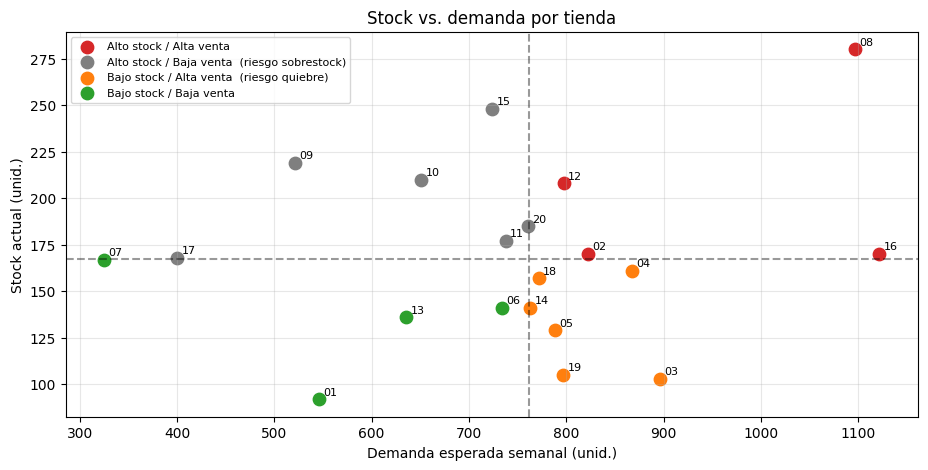

,id_tienda,stock_total,demanda_semana,costo_almacen,cobertura_dias_tienda,cuadrante
2,STORE_03,103,896.77,2050,0.80,Bajo stock / Alta venta (riesgo quiebre)
18,STORE_19,105,796.92,2490,0.92,Bajo stock / Alta venta (riesgo quiebre)
15,STORE_16,170,"1,121.69",3425,1.06,Alto stock / Alta venta
4,STORE_05,129,788.31,2500,1.15,Bajo stock / Alta venta (riesgo quiebre)
0,STORE_01,92,545.77,2150,1.18,Bajo stock / Baja venta
13,STORE_14,141,762.92,3365,1.29,Bajo stock / Alta venta (riesgo quiebre)
3,STORE_04,161,867.77,4350,1.30,Bajo stock / Alta venta (riesgo quiebre)
5,STORE_06,141,734.08,3115,1.34,Bajo stock / Baja venta
17,STORE_18,157,771.77,4045,1.42,Bajo stock / Alta venta (riesgo quiebre)
1,STORE_02,170,822.31,3800,1.45,Alto stock / Alta venta


In [14]:
q = (inv.groupby("id_tienda").agg(stock_total=("stock_actual", "sum"), demanda_semana=("demanda_semana_esperada", "sum"),
                                   costo_almacen=("costo_almacen_stock", "sum")).reset_index())
q["cobertura_dias_tienda"] = q["stock_total"] / (q["demanda_semana"] / 7)
ms, md_ = q["stock_total"].median(), q["demanda_semana"].median()
def cuadrante(r):
    if r["stock_total"] >= ms and r["demanda_semana"] >= md_: return "Alto stock / Alta venta"
    if r["stock_total"] < ms and r["demanda_semana"] >= md_: return "Bajo stock / Alta venta  (riesgo quiebre)"
    if r["stock_total"] >= ms and r["demanda_semana"] < md_: return "Alto stock / Baja venta  (riesgo sobrestock)"
    return "Bajo stock / Baja venta"
q["cuadrante"] = q.apply(cuadrante, axis=1)

colores = {c: col for c, col in zip(q["cuadrante"].unique(), ["tab:green", "tab:red", "tab:orange", "tab:gray"])}
fig, ax = plt.subplots()
for c, s in q.groupby("cuadrante"):
    ax.scatter(s["demanda_semana"], s["stock_total"], label=c, s=80, color=colores[c])
for _, r in q.iterrows():
    ax.annotate(r["id_tienda"].replace("STORE_", ""), (r["demanda_semana"], r["stock_total"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axvline(md_, color="k", ls="--", alpha=.4); ax.axhline(ms, color="k", ls="--", alpha=.4)
ax.set_xlabel("Demanda esperada semanal (unid.)"); ax.set_ylabel("Stock actual (unid.)"); ax.legend(fontsize=8)
ax.set_title("Stock vs. demanda por tienda"); plt.show()
display(q.sort_values("cobertura_dias_tienda"))

### 🔎 Lectura — Cuadrantes por tienda (tiendas con más stock y más venta)
- **Alto stock / alta venta (sano):** `STORE_08` y `STORE_16` (las dos más grandes, que además son las de mayor venta) y `STORE_12`, `STORE_02`. 
- **Bajo stock / alta venta → riesgo de quiebre:** `STORE_03` (0.80 días de cobertura), `STORE_19` (0.92), `STORE_05`, `STORE_14`, `STORE_04`, `STORE_18`. Son las tiendas donde más urge reponer y donde un pedido conservador sale más caro (costo de oportunidad).
- **Alto stock / baja venta → riesgo de sobrestock:** `STORE_15`, `STORE_09`, `STORE_10`, `STORE_17`, `STORE_11`, `STORE_20`. Ahí conviene pedir menos.
- **Bajo stock / baja venta:** `STORE_01`, `STORE_06`, `STORE_07`, `STORE_13` → la cobertura puede estar bien en relación con su venta.
- **Lectura clave:** el stock varía poco con la venta (siguiente gráfico), pero eso solo describe la foto (ver 1.6). `STORE_09`, `STORE_15` y `STORE_10` tienen ≈220–250 u. con demanda semanal de 520–720, mientras `STORE_03` vende ≈900 con solo ≈100 u.

In [15]:
# Productos caros de almacenar (Jugo de Naranja, Pastel...): ¿dónde se acumula stock de ellos?
a = (inv.groupby(["nombre", "costo_almacenamiento_semanal"]).agg(stock=("stock_actual", "sum"), demanda_sem=("demanda_semana_esperada", "sum")).reset_index())
a["cobertura_dias"] = a["stock"] / (a["demanda_sem"] / 7)
display(a.sort_values("costo_almacenamiento_semanal", ascending=False))

top = inv.sort_values("costo_almacen_stock", ascending=False).head(10)[["id_tienda", "nombre", "stock_actual", "cobertura_dias", "costo_almacen_stock"]]
print("Top 10 SKU-Tienda por costo de almacenar su stock actual:"); display(top)

,nombre,costo_almacenamiento_semanal,stock,demanda_sem,cobertura_dias
4,Jugo de Naranja,50,462,"2,294.85",1.41
6,Pastel de Pollo,30,353,"2,420.69",1.02
3,Croissant,25,453,"2,222.69",1.43
0,Buñuelo,20,393,"2,499.15",1.10
5,Pan de Bono,20,486,951.92,3.57
1,Café con Leche,15,351,"1,583.08",1.55
2,Cappuccino,15,435,"1,634.54",1.86
7,Tinto,10,434,"1,151.62",2.64


Top 10 SKU-Tienda por costo de almacenar su stock actual:


,id_tienda,nombre,stock_actual,cobertura_dias,costo_almacen_stock
95,STORE_12,Jugo de Naranja,97,5.32,4850
85,STORE_11,Croissant,89,5.25,2225
119,STORE_15,Jugo de Naranja,38,2.32,1900
31,STORE_04,Jugo de Naranja,36,1.50,1800
143,STORE_18,Jugo de Naranja,36,2.33,1800
62,STORE_08,Pastel de Pollo,56,1.83,1680
159,STORE_20,Jugo de Naranja,33,1.74,1650
158,STORE_20,Pastel de Pollo,54,3.16,1620
55,STORE_07,Jugo de Naranja,31,4.17,1550
61,STORE_08,Croissant,51,2.28,1275


### 🔎 Lectura — Productos caros de almacenar
- Cobertura por producto: **Pastel de Pollo 1.0 d, Buñuelo 1.1, Jugo 1.4, Croissant 1.4, Café 1.5, Cappuccino 1.9, Tinto 2.6, Pan de Bono 3.6**. Los tres más caros de almacenar (Jugo 50, Pastel 30, Croissant 25) están entre 1.0 y 1.4 días; el más barato (Tinto, 10) tiene 2.6.
- **Es compatible con la idea de que las tiendas guardan menos de lo caro de almacenar**, pero Pan de Bono (costo 20) rompe el patrón: su alta cobertura se explica más por su baja rotación que por su costo. Con 8 productos es una evidencia débil; la celda siguiente la mide con correlación de Spearman a nivel SKU-tienda.
- El mayor costo de almacenar stock actual está en `STORE_12 / Jugo de Naranja` (97 u → $4,850) y `STORE_11 / Croissant` (89 u). Montos pequeños frente al margen: confirma que **el almacenamiento no es el costo dominante** de la decisión.

In [16]:
# ¿Las tiendas guardan menos stock (en días) de lo caro de almacenar? Spearman a nivel SKU-tienda
from scipy.stats import spearmanr
r1 = spearmanr(inv["costo_almacenamiento_semanal"], inv["cobertura_dias"], nan_policy="omit")
r2 = spearmanr(inv["costo_almacenamiento_semanal"], inv["stock_actual"], nan_policy="omit")
print(f"Spearman costo_almacenamiento vs cobertura_dias: rho={r1.correlation:.2f}  p={r1.pvalue:.3f}")
print(f"Spearman costo_almacenamiento vs stock_actual:   rho={r2.correlation:.2f}  p={r2.pvalue:.3f}")

Spearman costo_almacenamiento vs cobertura_dias: rho=-0.17  p=0.028
Spearman costo_almacenamiento vs stock_actual:   rho=-0.00  p=0.965


### 🔎 Lectura — ¿Guardan menos de lo caro de almacenar?
- Spearman entre costo de almacenamiento y **cobertura en días**: ρ = −0.17 (p = 0.028); con stock en unidades: ρ ≈ 0 (p = 0.97).
- Es una relación **débil pero detectable**: los productos más caros de almacenar tienen algo menos de cobertura. Explica muy poco (ρ² ≈ 3 % de la variación), y en unidades no hay efecto. Con 8 productos distintos, el efecto lo arrastran sobre todo las diferencias de rotación entre ellos.
- **Conclusión:** no hay evidencia de una política de stock guiada por el costo de almacenar. Coherente con el hallazgo de que el stock está poco ligado a la venta.

---
# GLOSARIO
<sup><a href="#Contenido">↑ Contenido</a></sup>
Un mismo concepto se nombra siempre igual en el notebook. En el código y en las salidas puede aparecer con el nombre de la última columna.

**Datos y medidas de la venta**

| Término | Qué significa | En el código |
|---|---|---|
| SKU-tienda | Un producto en una tienda (20 tiendas × 8 productos = 160). | `id_tienda`, `id_producto` |
| Venta esperada | Lo que normalmente vende un SKU-tienda en ese día de la semana (promedio de sus semanas normales). | `esperado` |
| Venta relativa | Venta real ÷ venta esperada. 1.00 = día normal; 0.95 = 5 % menos de lo esperado. | `ratio` |
| Residuo | Venta relativa − 1: cuánto se desvió de lo esperado (−0.05 = 5 % menos). | `res` |
| Índice semanal | Venta de un día de la semana ÷ promedio diario del SKU-tienda (1.00 = promedio). El perfil semanal son los siete índices. | `idx` |
| Pico | Día con venta muy por encima de lo esperado. | |
| Demanda censurada | Venta que no ocurrió porque no había stock; las ventas observadas quedan por debajo de la demanda real. | |
| Smooth / ADI | Clasificación de la demanda: *Smooth* es demanda regular, sin ceros frecuentes (ADI cerca de 1; ADI es el intervalo medio entre ventas). | |

**Variabilidad y error**

| Término | Qué significa | En el código |
|---|---|---|
| Desviación estándar (σ) | Medida de cuánto se dispersan los datos alrededor del promedio. ±2σ cubre cerca del 95 % de los casos normales. | |
| z | Distancia de un valor al promedio, medida en desviaciones estándar. | `z` |
| CV (coeficiente de variación) | Desviación estándar ÷ media. Permite comparar variabilidad entre series de distinto tamaño. | `cv` |
| CV residual / ruido diario | CV del residuo después de quitar día de la semana y tendencia. Diario ≈ 0.31; semanal ≈ 0.12 (0.31 ÷ √7). Es la parte de la venta que no se puede predecir. | `cv_residual`, `cv_diario` |
| Piso de error | Error mínimo esperable aunque el modelo fuera perfecto, por el ruido diario: WAPE ≈ 0.8 × 0.31 ≈ 0.25. | |
| WAPE | Error porcentual absoluto ponderado: suma de \|real − pronóstico\| ÷ suma de lo vendido. | `wape` |
| Sesgo | Error medio con signo; indica si el modelo tiende a sobrestimar o subestimar. | |
| Cuantil | Valor que la demanda no supera con cierta probabilidad. El cuantil 0.9 cubre el 90 % de los casos. | `Q*(τ)` |
| Pinball loss | Error propio de los cuantiles: penaliza más quedarse corto o pasarse según el cuantil pedido. | |
| Cobertura del intervalo | Porcentaje de veces que lo real cae dentro del intervalo pronosticado. Un intervalo de 90 % debería cubrir ≈90 %. | |

**Pruebas estadísticas**

| Término | Qué significa |
|---|---|
| p-valor | Probabilidad de ver un resultado igual o más extremo si no hubiera ningún efecto. p < 0.05 se toma como evidencia de efecto. Con muchos datos casi todo sale significativo, por eso se mira también el tamaño. |
| Intervalo de confianza 95 % | Rango donde, con 95 % de confianza, está el valor verdadero. Si excluye 1.00 (en una venta relativa), hay efecto. |
| Prueba t de Welch | Compara dos promedios sin suponer varianzas iguales. |
| R² | Fracción de la variación que explica el modelo (de 0 a 1). |
| F | Estadístico que indica si agregar variables mejora el ajuste más de lo esperable por azar. |
| Correlación de Spearman (ρ) | Mide si dos variables suben o bajan juntas, sin suponer línea recta. 0 = sin relación. |
| Autocorrelación | Correlación de una serie consigo misma desplazada k días. |
| Cociente de varianzas | Varianza observada ÷ varianza esperada si fueran independientes. Cerca de 1 = independencia. |
| Lift | Cuánto más probable es comprar B si se compra A, frente a la probabilidad base de B. 1 = sin relación; mayor que 1, se complementan; menor que 1, se sustituyen. |

**Validación**

| Término | Qué significa |
|---|---|
| Backtest | Prueba con el pasado: pronosticar una semana ya ocurrida con lo que se sabía antes y comparar con lo real. |
| Origen móvil (*rolling origin*) | Backtest repetido semana a semana, con una ventana de entrenamiento que crece. |
| Ablación | Comparar el mismo modelo con y sin un grupo de variables para ver cuánto aporta cada una. |
| Naive | Pronóstico más simple: lo que se vendió el mismo día de la semana pasada. |

**Decisión de pedido**

| Término | Qué significa |
|---|---|
| Newsvendor | Modelo de pedido bajo demanda incierta: se compara el costo de quedarse corto con el de pasarse. |
| Cu | Costo de quedarse corto: margen + β × margen cruzado. |
| Co | Costo de pasarse: almacenamiento + α × costo unitario. |
| Ratio crítico (τ) | Cu ÷ (Cu + Co): el cuantil de la demanda que conviene pedir. |
| α | Fracción del costo unitario que se pierde si el producto sobra (merma). |
| β | Fracción de la venta cruzada que se pierde si falta el producto. |
| Venta cruzada | Lo que el cliente compra junto con el producto; si falta, también se pierde. |
| Merma | Producto que se pierde por vencimiento o deterioro. |
| Cobertura de stock | Stock ÷ venta media diaria: cuántos días dura el stock. |
| Lead time (L) | Días entre hacer el pedido y recibirlo. |
| Período de revisión (R) | Días que cubre cada pedido. |
| Stock en tránsito | Unidades ya pedidas que aún no llegan. |
| MOQ y empaque | Pedido mínimo por producto y múltiplo en que vende el proveedor. |
| Venta perdida inevitable | Venta que se pierde mientras llega el pedido porque el stock no alcanza para cubrir el lead time. |